# KZ-SkinNet — reviewer experiments (ISIC 2018 / PH2 / ISIC 2016)

All experiments requested in the review, with the outputs of the executed Kaggle run (NVIDIA Tesla T4, TensorFlow 2.20).
**KZ-SkinNet = A0**: MobileNetV3Small encoder (ImageNet) + depthwise-separable U-Net decoder, 4 skip connections, 0.5·BCE + 0.5·Dice, 1,083,865 parameters.

**Common protocol for every trained model**: 256×256 input, batch 16, Adam 1e-4, max 20 epochs, EarlyStopping (val_loss, patience 5), ReduceLROnPlateau (factor 0.5, patience 2, min 1e-7), best-val-loss checkpoint, threshold 0.5. Metrics are pixel-level pooled over all images unless stated otherwise.

| Section | Content | Reviewer comments |
|---|---|---|
| 1 | Data | R2.6, R4.2 |
| 2 | Ablation A0–A5 | R1.5, R3.14, R4.9 |
| 3 | Comparison with U-Net / EfficientNetB0-UNet / MobileNetV3Large-UNet | R4.10 |
| 4 | Overall A0 metrics, external testing (PH2, ISIC 2016) + data-leakage check | R4.3, R3.13, R4.17 |
| 5 | Qualitative results incl. failure cases | R4.16 |
| 6 | Training curves | — |
| 7 | Final results of all models + verification, pixel-level confusion matrix | R1.2, R1.4, R3.2, R4.7, R4.8 |
| 8 | Three independent runs + Wilcoxon tests, bootstrap 95% CI | R3.10, R4.12 |
| 9 | Threshold selection | R1.3 |
| 10 | Computational efficiency + hardware | R2.4, R4.11 |
| 11 | Grad-CAM and LIME, quantitative | R1.6, R1.7, R2.3, R4.13 |
| 12 | SHAP, quantitative | R1.6, R2.3, R4.13 |
| 13 | 5-fold cross-validation of A0 | R2.6, R3.10 |

*Cells are arranged in a logical order; run top-to-bottom to reproduce. Cells in sections 7–12 use the helpers defined in **CELL S** (section 7); section 13 is standalone.*

## 1. Data — ISIC 2018 Task 1 official split (2594 train / 100 validation / 1000 test)

In [ ]:
!pip install -q albumentations
!pip install -q segmentation-models-pytorch
!pip install -q lime
!pip install -q shap
!pip install -q grad-cam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 2.2 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import cv2

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf

from tensorflow.keras.utils import Sequence

import warnings
warnings.filterwarnings("ignore")

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed fixed:", SEED)

Random seed fixed: 42


In [ ]:
# ISIC 2018 Correct Paths


TRAIN_IMG_PATH = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset/train/images/ISIC2018_Task1-2_Training_Input"

TRAIN_MASK_PATH = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset/train/masks/ISIC2018_Task1_Training_GroundTruth"



VAL_IMG_PATH = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset/validation/images/ISIC2018_Task1-2_Validation_Input"

VAL_MASK_PATH = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset/validation/masks/ISIC2018_Task1_Validation_GroundTruth"



TEST_IMG_PATH = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset/test/images/ISIC2018_Task1-2_Test_Input"

TEST_MASK_PATH = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset/test/masks/ISIC2018_Task1_Test_GroundTruth"



print("Paths updated successfully")

Paths updated successfully


In [ ]:

def create_dataframe(image_path, mask_path, dataset_name):

    images = []
    masks = []


    # Only image files
    image_files = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".jpg",".jpeg",".png"))
    ]


    # Only mask images
    mask_files = [
        f for f in os.listdir(mask_path)
        if f.lower().endswith((".png",".jpg",".jpeg"))
    ]


    # Create mask dictionary

    mask_dict={}


    for mask in mask_files:

        mask_id = mask.replace(
            "_segmentation.png",
            ""
        )

        mask_dict[mask_id]=mask



    # Match images and masks

    for image in image_files:

        image_id=image.replace(
            ".jpg",
            ""
        )


        if image_id in mask_dict:

            images.append(
                os.path.join(
                    image_path,
                    image
                )
            )


            masks.append(
                os.path.join(
                    mask_path,
                    mask_dict[image_id]
                )
            )


    dataframe=pd.DataFrame(
        {
            "image":images,
            "mask":masks,
            "dataset":dataset_name
        }
    )


    return dataframe

In [ ]:
train_df=create_dataframe(
    TRAIN_IMG_PATH,
    TRAIN_MASK_PATH,
    "train"
)


val_df=create_dataframe(
    VAL_IMG_PATH,
    VAL_MASK_PATH,
    "validation"
)


test_df=create_dataframe(
    TEST_IMG_PATH,
    TEST_MASK_PATH,
    "test"
)


print("Train:",len(train_df))
print("Validation:",len(val_df))
print("Test:",len(test_df))

Train: 2594
Validation: 100
Test: 1000


## 2. Ablation study A0–A5 (identical training protocol)
A0 = full KZ-SkinNet; A1 MobileNetV2 encoder; A2 standard-conv decoder; A3 no skip connections; A4 BCE-only; A5 Dice-only.

In [ ]:
import os, time, json, random
import numpy as np, pandas as pd, cv2
import tensorflow as tf
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score

SEED = 42
IMG_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 20                 # max epochs per variant
MAX_MIN_PER_VARIANT = 25    # hard time limit per variant (minutes)
OUT_DIR = "/kaggle/working/ablation"
os.makedirs(OUT_DIR, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass   # GPU already initialised by earlier cells, safe to ignore

USE_MP = False
if gpus:
    cc = tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0))
    USE_MP = cc[0] >= 7          # T4 = 7.5 -> mixed precision ON, P100 = 6.0 -> OFF
    print("GPU compute capability:", cc)
tf.keras.mixed_precision.set_global_policy("mixed_float16" if USE_MP else "float32")
print("GPUs:", gpus, "| Mixed precision:", USE_MP)

GPU compute capability: (7, 5)
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')] | Mixed precision: True


In [ ]:
def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)[..., None]

def load_split(df, name):
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, df["image"], df["mask"]))
    X = np.stack([r[0] for r in res]); Y = np.stack([r[1] for r in res])
    print(f"{name}: X {X.shape}, Y {Y.shape}, {time.time()-t0:.0f}s")
    return X, Y

X_train, Y_train = load_split(train_df, "train")
X_val,   Y_val   = load_split(val_df,   "validation")
X_test,  Y_test  = load_split(test_df,  "test")

train: X (2594, 256, 256, 3), Y (2594, 256, 256, 1), 207s
validation: X (100, 256, 256, 3), Y (100, 256, 256, 1), 5s
test: X (1000, 256, 256, 3), Y (1000, 256, 256, 1), 50s


In [ ]:
def to_input(x):                       # [0,1] -> [-1,1] (same as the notebook)
    return x * 2.0 - 1.0

def augment(x, y):
    x = tf.cast(x, tf.float32) / 255.0
    y = tf.cast(y, tf.float32)
    xy = tf.concat([x, y], axis=-1)
    xy = tf.image.random_flip_left_right(xy)
    xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x, y = xy[..., :3], xy[..., 3:]
    x = tf.image.random_brightness(x, 0.15)
    x = tf.image.random_contrast(x, 0.85, 1.15)
    x = tf.image.random_saturation(x, 0.85, 1.15)
    x = tf.image.random_hue(x, 0.03)
    x = tf.clip_by_value(x, 0.0, 1.0)
    return to_input(x), y

def no_augment(x, y):
    return to_input(tf.cast(x, tf.float32) / 255.0), tf.cast(y, tf.float32)

def make_ds(X, Y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(no_augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, Y_train, True)
val_ds   = make_ds(X_val,   Y_val,   False).cache()
test_ds  = make_ds(X_test,  Y_test,  False)
print("Train batches:", len(train_ds), "| Val:", len(val_ds), "| Test:", len(test_ds))

Train batches: 163 | Val: 7 | Test: 63


In [ ]:
def conv_block(x, filters, name, separable=True):
    Conv = layers.SeparableConv2D if separable else layers.Conv2D
    x = Conv(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def decoder_block(x, skip, filters, name, separable, use_skip):
    x = layers.UpSampling2D(2, interpolation="bilinear", name=name + "_up")(x)
    if use_skip:
        x = layers.Concatenate(name=name + "_cat")([x, skip])
    return conv_block(x, filters, name, separable)

def encoder_features(inputs, kind, weights="imagenet"):
    if kind == "v3small":
        bb = tf.keras.applications.MobileNetV3Small(input_tensor=inputs, include_top=False,
                                                    weights=weights, include_preprocessing=False)
        feats = {}
        for l in bb.layers:
            try:
                s = l.output.shape
                if len(s) == 4 and s[1] in (128, 64, 32, 16, 8):
                    feats[s[1]] = l.output
            except Exception:
                pass
        return feats[128], feats[64], feats[32], feats[16], feats[8]
    if kind == "v2":
        bb = tf.keras.applications.MobileNetV2(input_tensor=inputs, include_top=False,
                                               weights=weights, alpha=1.0)
        g = lambda n: bb.get_layer(n).output
        return (g("block_1_expand_relu"), g("block_3_expand_relu"), g("block_6_expand_relu"),
                g("block_13_expand_relu"), g("out_relu"))

def build_model(encoder="v3small", separable=True, use_skip=True, weights="imagenet"):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    s1, s2, s3, s4, bridge = encoder_features(inp, encoder, weights)
    x = conv_block(bridge, 128, "bridge", separable)
    x = decoder_block(x, s4, 96, "dec4", separable, use_skip)
    x = decoder_block(x, s3, 64, "dec3", separable, use_skip)
    x = decoder_block(x, s2, 32, "dec2", separable, use_skip)
    x = decoder_block(x, s1, 16, "dec1", separable, use_skip)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x)
    return models.Model(inp, out)

In [ ]:
SMOOTH = 1e-6
def dice_coefficient(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (2.0 * inter + SMOOTH) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + SMOOTH)

def iou_score(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (inter + SMOOTH) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - inter + SMOOTH)

_bce = tf.keras.losses.BinaryCrossentropy()
def bce_dice_loss(y_true, y_pred):
    return 0.5 * _bce(y_true, tf.cast(y_pred, tf.float32)) + 0.5 * (1.0 - dice_coefficient(y_true, y_pred))
def bce_only_loss(y_true, y_pred):
    return _bce(y_true, tf.cast(y_pred, tf.float32))
def dice_only_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)

VARIANTS = {
    "A0": dict(desc="Proposed: MobileNetV3Small + SepConv decoder + skips + BCE+Dice", model={}, loss=bce_dice_loss),
    "A1": dict(desc="MobileNetV2 Encoder",          model=dict(encoder="v2"),    loss=bce_dice_loss),
    "A2": dict(desc="Standard Convolution Decoder", model=dict(separable=False), loss=bce_dice_loss),
    "A3": dict(desc="Without Skip Connections",     model=dict(use_skip=False),  loss=bce_dice_loss),
    "A4": dict(desc="BCE-only Loss",                model={},                    loss=bce_only_loss),
    "A5": dict(desc="Dice-only Loss",               model={},                    loss=dice_only_loss),
}

In [ ]:
class TimeLimit(tf.keras.callbacks.Callback):
    def __init__(self, minutes):
        super().__init__(); self.limit = minutes * 60
    def on_train_begin(self, logs=None):
        self.t0 = time.time()
    def on_epoch_begin(self, epoch, logs=None):
        self.te = time.time()
    def on_epoch_end(self, epoch, logs=None):
        dt = time.time() - self.te; total = time.time() - self.t0
        print(f"   -> epoch {epoch+1}: {dt:.0f}s | variant total {total/60:.1f} min")
        if total + dt > self.limit:
            print("   Time limit reached, stopping this variant.")
            self.model.stop_training = True

def evaluate(model):
    prob = model.predict(test_ds, verbose=0).reshape(-1)
    y = Y_test.reshape(-1).astype(bool); p = prob >= 0.5
    TP = np.sum(y & p); TN = np.sum(~y & ~p); FP = np.sum(~y & p); FN = np.sum(y & ~p); e = 1e-7
    idx = np.random.RandomState(0).choice(len(y), min(len(y), 2_000_000), replace=False)
    return dict(Accuracy=(TP+TN)/(TP+TN+FP+FN), Precision=TP/(TP+FP+e), Sensitivity=TP/(TP+FN+e),
                Specificity=TN/(TN+FP+e), Dice=2*TP/(2*TP+FP+FN+e), IoU=TP/(TP+FP+FN+e),
                AUC=roc_auc_score(y[idx], prob[idx]))

def run_variant(name, weights="imagenet"):
    res_file = f"{OUT_DIR}/{name}_result.json"
    if os.path.exists(res_file):                       # resume: skip finished variants
        print(name, "already done, loading saved result"); return json.load(open(res_file))
    cfg = VARIANTS[name]
    print(f"########## {name}: {cfg['desc']}")
    tf.keras.backend.clear_session()
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
    model = build_model(weights=weights, **cfg["model"])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=cfg["loss"],
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), dice_coefficient, iou_score])
    ckpt = f"{OUT_DIR}/{name}_best.weights.h5"
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", mode="min",
                                           save_best_only=True, save_weights_only=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5,
                                             patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, verbose=1),
        tf.keras.callbacks.CSVLogger(f"{OUT_DIR}/{name}_history.csv"),
        TimeLimit(MAX_MIN_PER_VARIANT),
    ]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)
    model.load_weights(ckpt)                          # best val_loss checkpoint
    r = evaluate(model)
    r = {k: float(v) for k, v in r.items()}
    r.update(Variant=name, Description=cfg["desc"], Params=int(model.count_params()),
             Epochs=len(hist.history["loss"]), Minutes=round((time.time()-t0)/60, 1))
    json.dump(r, open(res_file, "w"), indent=1)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})
    return r

results = {}

In [ ]:
results["A0"] = run_variant("A0")

########## A0: Proposed: MobileNetV3Small + SepConv decoder + skips + BCE+Dice
Epoch 1/20


I0000 00:00:1795312893.323012     215 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


   -> epoch 1: 127s | variant total 2.1 min
163/163 - 127s - 776ms/step - accuracy: 0.5978 - dice_coefficient: 0.4223 - iou_score: 0.2715 - loss: 0.6388 - val_accuracy: 0.3188 - val_dice_coefficient: 0.3535 - val_iou_score: 0.2155 - val_loss: 0.6678 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 12s | variant total 2.3 min
163/163 - 12s - 73ms/step - accuracy: 0.9063 - dice_coefficient: 0.5395 - iou_score: 0.3733 - loss: 0.4451 - val_accuracy: 0.9059 - val_dice_coefficient: 0.4449 - val_iou_score: 0.2875 - val_loss: 0.5435 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 12s | variant total 2.5 min
163/163 - 12s - 72ms/step - accuracy: 0.9377 - dice_coefficient: 0.5951 - iou_score: 0.4269 - loss: 0.3708 - val_accuracy: 0.9325 - val_dice_coefficient: 0.6264 - val_iou_score: 0.4585 - val_loss: 0.3445 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 12s | variant total 2.7 min
163/163 - 12s - 71ms/step - accuracy: 0.9434 - dice_coefficient: 0.6240 - iou_score: 0.4562 - lo

In [ ]:
results["A1"] = run_variant("A1")

########## A1: MobileNetV2 Encoder
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20


2026-11-22 02:07:42.768507: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:07:42.905345: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:07:43.719928: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:07:43.864445: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:07:44.578020: E external/local_xla/xla/stream_

   -> epoch 1: 163s | variant total 2.7 min
163/163 - 163s - 999ms/step - accuracy: 0.6179 - dice_coefficient: 0.4485 - iou_score: 0.2940 - loss: 0.6003 - val_accuracy: 0.7117 - val_dice_coefficient: 0.3589 - val_iou_score: 0.2195 - val_loss: 0.6532 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 22s | variant total 3.1 min
163/163 - 22s - 133ms/step - accuracy: 0.9287 - dice_coefficient: 0.5600 - iou_score: 0.3922 - loss: 0.4128 - val_accuracy: 0.8655 - val_dice_coefficient: 0.4288 - val_iou_score: 0.2744 - val_loss: 0.5208 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 21s | variant total 3.4 min
163/163 - 21s - 130ms/step - accuracy: 0.9374 - dice_coefficient: 0.5888 - iou_score: 0.4219 - loss: 0.3729 - val_accuracy: 0.9273 - val_dice_coefficient: 0.6303 - val_iou_score: 0.4636 - val_loss: 0.3277 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 20s | variant total 3.8 min
163/163 - 20s - 122ms/step - accuracy: 0.9422 - dice_coefficient: 0.6186 - iou_score: 0.4511 -

2026-11-22 02:14:13.194103: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:14:13.330497: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:14:13.467252: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:14:14.293126: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:14:14.437880: E external/local_xla/xla/stream_

{'Accuracy': 0.931, 'Precision': 0.8545, 'Sensitivity': 0.9081, 'Specificity': 0.9399, 'Dice': 0.8805, 'IoU': 0.7864, 'AUC': 0.974, 'Variant': 'A1', 'Description': 'MobileNetV2 Encoder', 'Params': 2541377, 'Epochs': 13, 'Minutes': 7.4}


In [ ]:
results["A2"] = run_variant("A2")

########## A2: Standard Convolution Decoder
Epoch 1/20


2026-11-22 02:15:43.172842: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:15:43.453037: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:15:43.930799: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:15:44.081995: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 02:16:20.160319: E external/local_xla/xla/stream_

   -> epoch 1: 93s | variant total 1.6 min
163/163 - 93s - 574ms/step - accuracy: 0.8797 - dice_coefficient: 0.5735 - iou_score: 0.4092 - loss: 0.3900 - val_accuracy: 0.9128 - val_dice_coefficient: 0.7235 - val_iou_score: 0.5696 - val_loss: 0.2741 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 12s | variant total 1.8 min
163/163 - 12s - 76ms/step - accuracy: 0.9398 - dice_coefficient: 0.6792 - iou_score: 0.5179 - loss: 0.2760 - val_accuracy: 0.9340 - val_dice_coefficient: 0.7651 - val_iou_score: 0.6238 - val_loss: 0.2166 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 12s | variant total 2.0 min
163/163 - 12s - 73ms/step - accuracy: 0.9486 - dice_coefficient: 0.7159 - iou_score: 0.5613 - loss: 0.2401 - val_accuracy: 0.9367 - val_dice_coefficient: 0.7542 - val_iou_score: 0.6092 - val_loss: 0.2215 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 13s | variant total 2.2 min
163/163 - 13s - 78ms/step - accuracy: 0.9535 - dice_coefficient: 0.7414 - iou_score: 0.5922 - loss

In [ ]:
results["A3"] = run_variant("A3")

########## A3: Without Skip Connections
Epoch 1/20
   -> epoch 1: 99s | variant total 1.7 min
163/163 - 99s - 608ms/step - accuracy: 0.7551 - dice_coefficient: 0.4416 - iou_score: 0.2862 - loss: 0.5721 - val_accuracy: 0.7317 - val_dice_coefficient: 0.3322 - val_iou_score: 0.1998 - val_loss: 0.6628 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 10s | variant total 1.8 min
163/163 - 10s - 64ms/step - accuracy: 0.9067 - dice_coefficient: 0.5286 - iou_score: 0.3619 - loss: 0.4494 - val_accuracy: 0.7621 - val_dice_coefficient: 0.3469 - val_iou_score: 0.2105 - val_loss: 0.6156 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 11s | variant total 2.0 min
163/163 - 11s - 65ms/step - accuracy: 0.9302 - dice_coefficient: 0.5648 - iou_score: 0.3968 - loss: 0.4029 - val_accuracy: 0.9217 - val_dice_coefficient: 0.5546 - val_iou_score: 0.3862 - val_loss: 0.4147 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 11s | variant total 2.2 min
163/163 - 11s - 66ms/step - accuracy: 0.9408 - 

In [ ]:
results["A4"] = run_variant("A4")

########## A4: BCE-only Loss
Epoch 1/20
   -> epoch 1: 94s | variant total 1.6 min
163/163 - 94s - 578ms/step - accuracy: 0.5892 - dice_coefficient: 0.4161 - iou_score: 0.2658 - loss: 0.7015 - val_accuracy: 0.2707 - val_dice_coefficient: 0.3543 - val_iou_score: 0.2161 - val_loss: 0.7058 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 12s | variant total 1.8 min
163/163 - 12s - 71ms/step - accuracy: 0.9151 - dice_coefficient: 0.5294 - iou_score: 0.3628 - loss: 0.4245 - val_accuracy: 0.8965 - val_dice_coefficient: 0.4546 - val_iou_score: 0.2956 - val_loss: 0.5462 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 12s | variant total 2.0 min
163/163 - 12s - 72ms/step - accuracy: 0.9423 - dice_coefficient: 0.5778 - iou_score: 0.4091 - loss: 0.3384 - val_accuracy: 0.9284 - val_dice_coefficient: 0.6163 - val_iou_score: 0.4479 - val_loss: 0.3372 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 12s | variant total 2.2 min
163/163 - 12s - 71ms/step - accuracy: 0.9477 - dice_coeffi

In [ ]:
results["A5"] = run_variant("A5")

########## A5: Dice-only Loss
Epoch 1/20
   -> epoch 1: 95s | variant total 1.6 min
163/163 - 95s - 581ms/step - accuracy: 0.5916 - dice_coefficient: 0.4299 - iou_score: 0.2781 - loss: 0.5684 - val_accuracy: 0.7570 - val_dice_coefficient: 0.3659 - val_iou_score: 0.2247 - val_loss: 0.6278 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 12s | variant total 1.8 min
163/163 - 12s - 71ms/step - accuracy: 0.8635 - dice_coefficient: 0.5462 - iou_score: 0.3804 - loss: 0.4539 - val_accuracy: 0.9014 - val_dice_coefficient: 0.4281 - val_iou_score: 0.2734 - val_loss: 0.5670 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 12s | variant total 2.0 min
163/163 - 12s - 72ms/step - accuracy: 0.9079 - dice_coefficient: 0.5972 - iou_score: 0.4314 - loss: 0.4017 - val_accuracy: 0.9269 - val_dice_coefficient: 0.6371 - val_iou_score: 0.4695 - val_loss: 0.3592 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 12s | variant total 2.2 min
163/163 - 12s - 72ms/step - accuracy: 0.9220 - dice_coeff

A0 done
A1 done
A2 done
A3 done
A4 done
A5 done

Ablation study - ISIC 2018 Validation (n=100) (pixel-level pooled metrics, %)


,ID,Variant,Params,Accuracy,Precision,Sensitivity,Specificity,Dice,IoU,AUC,Epochs,Minutes,Δ Dice,Δ IoU
0,A0,"KZ-SkinNet (Proposed, full model)","1,083,865",95.31,89.05,94.10,95.76,91.51,84.34,99.04,20,6.1,0.00,0.00
1,A1,MobileNetV2 Encoder,"2,541,377",93.71,87.06,89.90,95.10,88.46,79.31,97.92,13,7.4,-3.05,-5.03
2,A2,Standard Convolution Decoder,"2,120,129",94.63,87.31,93.60,95.01,90.35,82.39,98.92,20,5.8,-1.16,-1.95
3,A3,Without Skip Connections,"1,043,265",94.64,88.07,92.57,95.40,90.27,82.26,98.54,20,5.3,-1.24,-2.08
4,A4,BCE-only Loss,"1,083,865",94.80,87.12,94.62,94.87,90.71,83.00,99.08,20,5.5,-0.80,-1.34
5,A5,Dice-only Loss,"1,083,865",94.14,83.25,97.86,92.78,89.97,81.76,98.28,20,5.6,-1.54,-2.58



Ablation study - ISIC 2018 Test (n=1000) (pixel-level pooled metrics, %)


,ID,Variant,Params,Accuracy,Precision,Sensitivity,Specificity,Dice,IoU,AUC,Epochs,Minutes,Δ Dice,Δ IoU
0,A0,"KZ-SkinNet (Proposed, full model)","1,083,865",94.07,87.73,91.60,95.02,89.62,81.19,97.85,20,6.1,0.00,0.00
1,A1,MobileNetV2 Encoder,"2,541,377",93.10,85.45,90.81,93.99,88.05,78.64,97.40,13,7.4,-1.57,-2.55
2,A2,Standard Convolution Decoder,"2,120,129",93.72,86.75,91.51,94.57,89.07,80.29,97.73,20,5.8,-0.55,-0.90
3,A3,Without Skip Connections,"1,043,265",93.63,87.37,90.29,94.93,88.80,79.86,97.41,20,5.3,-0.82,-1.33
4,A4,BCE-only Loss,"1,083,865",93.53,85.76,92.19,94.05,88.85,79.94,97.91,20,5.5,-0.77,-1.25
5,A5,Dice-only Loss,"1,083,865",92.30,81.07,94.53,91.43,87.29,77.44,96.44,20,5.6,-2.33,-3.75


Saved: /kaggle/working/ablation/ablation_table_val_test.csv


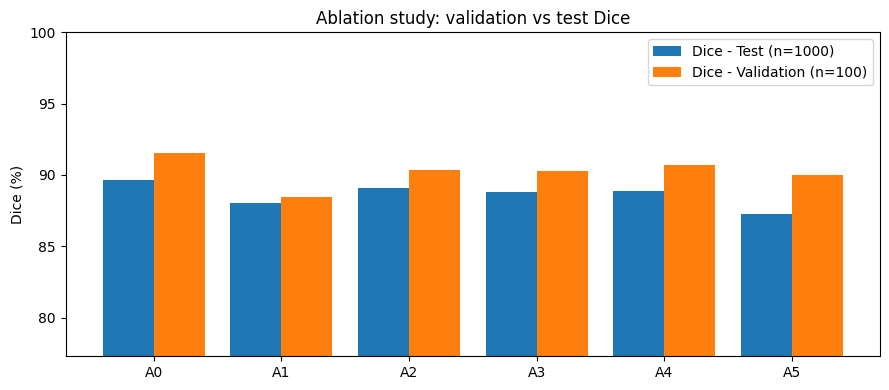

In [ ]:
# ============================================================
# ABLATION TABLE (A0-A5): VALIDATION + TEST
# Rebuilds each variant, loads its best checkpoint and evaluates
# on both sets (needs CELL 1-6 of the ablation notebook to be run)
# ============================================================
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

OUT_DIR = "/kaggle/working/ablation"
ORDER = ["A0", "A1", "A2", "A3", "A4", "A5"]
NAMES = {
    "A0": "KZ-SkinNet (Proposed, full model)",
    "A1": "MobileNetV2 Encoder",
    "A2": "Standard Convolution Decoder",
    "A3": "Without Skip Connections",
    "A4": "BCE-only Loss",
    "A5": "Dice-only Loss",
}
METRICS = ["Accuracy", "Precision", "Sensitivity", "Specificity", "Dice", "IoU", "AUC"]

def pooled_metrics(model, ds, Y):
    prob = model.predict(ds, verbose=0).reshape(-1)
    y = Y.reshape(-1).astype(bool); p = prob >= 0.5
    TP = np.sum(y & p); TN = np.sum(~y & ~p); FP = np.sum(~y & p); FN = np.sum(y & ~p); e = 1e-7
    idx = np.random.RandomState(0).choice(len(y), min(len(y), 2_000_000), replace=False)
    return dict(Accuracy=(TP+TN)/(TP+TN+FP+FN), Precision=TP/(TP+FP+e), Sensitivity=TP/(TP+FN+e),
                Specificity=TN/(TN+FP+e), Dice=2*TP/(2*TP+FP+FN+e), IoU=TP/(TP+FP+FN+e),
                AUC=roc_auc_score(y[idx], prob[idx]))

rows = []
for k in ORDER:
    ckpt = os.path.join(OUT_DIR, f"{k}_best.weights.h5")
    res_file = os.path.join(OUT_DIR, f"{k}_result.json")
    if not os.path.exists(ckpt):
        print("Missing checkpoint:", ckpt); continue
    tf.keras.backend.clear_session()
    model = build_model(weights=None, **VARIANTS[k]["model"])   # weights come from the checkpoint
    model.load_weights(ckpt)
    info = json.load(open(res_file)) if os.path.exists(res_file) else {}
    for set_name, ds, Y in [("Validation (n=100)", val_ds, Y_val), ("Test (n=1000)", test_ds, Y_test)]:
        r = pooled_metrics(model, ds, Y)
        r.update(Set=set_name, ID=k, Variant=NAMES[k], Params=model.count_params(),
                 Epochs=info.get("Epochs"), Minutes=info.get("Minutes"))
        rows.append(r)
    print(k, "done")

table = pd.DataFrame(rows)[["Set", "ID", "Variant", "Params"] + METRICS + ["Epochs", "Minutes"]]
table[METRICS] = (table[METRICS] * 100).round(2)            # percentages

# change vs A0 within each set
for m in ["Dice", "IoU"]:
    a0 = table[table["ID"] == "A0"].set_index("Set")[m]
    table[f"Δ {m}"] = (table[m] - table["Set"].map(a0)).round(2)
table["Params"] = table["Params"].map(lambda p: f"{int(p):,}")

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
for s in table["Set"].unique():
    print(f"\nAblation study - ISIC 2018 {s} (pixel-level pooled metrics, %)")
    display(table[table["Set"] == s].drop(columns="Set").reset_index(drop=True))

table.to_csv(os.path.join(OUT_DIR, "ablation_table_val_test.csv"), index=False)
print("Saved:", os.path.join(OUT_DIR, "ablation_table_val_test.csv"))

# ---------------- chart: Dice on validation vs test ----------------
pv = table.pivot(index="ID", columns="Set", values="Dice").reindex([k for k in ORDER if k in table["ID"].values])
x = np.arange(len(pv))
plt.figure(figsize=(9, 4))
for i, s in enumerate(pv.columns):
    plt.bar(x + (i - 0.5) * 0.4, pv[s], 0.4, label=f"Dice - {s}")
plt.xticks(x, pv.index)
plt.ylim(max(0, np.nanmin(pv.values) - 10), 100)
plt.ylabel("Dice (%)"); plt.title("Ablation study: validation vs test Dice")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ablation_dice_val_test.png"), dpi=300)
plt.show()

## 3. Comparison models (same protocol)
U0 = vanilla U-Net (from scratch), L1 = EfficientNetB0-UNet, L2 = MobileNetV3Large-UNet (same decoder as A0).

*Note:* in the next cell U0 was stopped by a 25-min time limit after 9 epochs. It is therefore **re-trained without time limit** in the following "FIX + RERUN" cell (20 epochs, same rules as all other models). The table of the FIX cell is the final comparison (it also evaluates L1 with the correct EfficientNet preprocessing).

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')] | Mixed precision: True
train: 2594 images loaded in 217s
validation: 100 images loaded in 4s
test: 1000 images loaded in 45s

########## U0: Baseline U-Net (vanilla, from scratch)
Parameters: 31,049,409
Epoch 1/20


2026-11-22 02:54:51.154908: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[16,128,128,128]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,128,128,128]{3,2,1,0}, f32[128,128,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-11-22 02:54:51.397472: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.242756062s
Trying algorithm eng3{k11=2} for conv (f32[16,128,128,128]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,128,128,128]{3,2,1,0}, f32[128,128,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operat

   -> epoch 1: 314s | total 5.2 min
163/163 - 314s - 2s/step - accuracy: 0.7948 - dice_coefficient: 0.4889 - iou_score: 0.3278 - loss: 0.5019 - val_accuracy: 0.8064 - val_dice_coefficient: 0.4653 - val_iou_score: 0.3042 - val_loss: 0.5129 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 146s | total 7.7 min
163/163 - 146s - 897ms/step - accuracy: 0.9069 - dice_coefficient: 0.6207 - iou_score: 0.4527 - loss: 0.3362 - val_accuracy: 0.8734 - val_dice_coefficient: 0.6241 - val_iou_score: 0.4560 - val_loss: 0.3599 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 145s | total 10.1 min
163/163 - 145s - 892ms/step - accuracy: 0.9192 - dice_coefficient: 0.6701 - iou_score: 0.5067 - loss: 0.2886 - val_accuracy: 0.9065 - val_dice_coefficient: 0.7431 - val_iou_score: 0.5951 - val_loss: 0.2631 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 145s | total 12.5 min
163/163 - 145s - 891ms/step - accuracy: 0.9248 - dice_coefficient: 0.6999 - iou_score: 0.5422 - loss: 0.2607 - val_accurac

2026-11-22 03:19:55.638881: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 03:19:55.874281: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


{'ID': 'U0', 'Model': 'Baseline U-Net (vanilla, from scratch)', 'Params': 31049409, 'Epochs': 9, 'Minutes': 24.7, 'val_Accuracy': 0.9259, 'val_Precision': 0.8781, 'val_Sensitivity': 0.8406, 'val_Specificity': 0.9572, 'val_Dice': 0.859, 'val_IoU': 0.7528, 'val_AUC': 0.9663, 'test_Accuracy': 0.9138, 'test_Precision': 0.8798, 'test_Sensitivity': 0.8012, 'test_Specificity': 0.9575, 'test_Dice': 0.8387, 'test_IoU': 0.7221, 'test_AUC': 0.9478}

########## L1: EfficientNetB0-UNet (SepConv decoder)
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parameters: 4,346,548
Epoch 1/20


2026-11-22 03:20:55.898134: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 03:20:56.038023: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 03:20:56.379869: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 03:20:56.521833: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 03:20:57.315362: E external/local_xla/xla/stream_

... (7 outputs left out)

,ID,Model,Params,Accuracy,Precision,Sensitivity,Specificity,Dice,IoU,AUC,Epochs,Minutes
0,U0,"Baseline U-Net (vanilla, from scratch)","31,049,409",92.59,87.81,84.06,95.72,85.90,75.28,96.63,9,24.7
1,L1,EfficientNetB0-UNet (SepConv decoder),"4,346,548",94.67,87.89,92.95,95.30,90.35,82.40,97.95,17,9.4
2,L2,MobileNetV3Large-UNet (SepConv decoder),"3,245,737",94.71,86.69,94.84,94.66,90.58,82.78,98.98,19,7.8



Comparison models - ISIC 2018 Test (n=1000) (pixel-level pooled metrics, %)


,ID,Model,Params,Accuracy,Precision,Sensitivity,Specificity,Dice,IoU,AUC,Epochs,Minutes
0,U0,"Baseline U-Net (vanilla, from scratch)","31,049,409",91.38,87.98,80.12,95.75,83.87,72.21,94.78,9,24.7
1,L1,EfficientNetB0-UNet (SepConv decoder),"4,346,548",94.29,88.09,92.04,95.17,90.02,81.85,97.77,17,9.4
2,L2,MobileNetV3Large-UNet (SepConv decoder),"3,245,737",93.59,85.89,92.25,94.11,88.96,80.11,97.82,19,7.8


Saved: /kaggle/working/comparison/comparison_val_test.csv


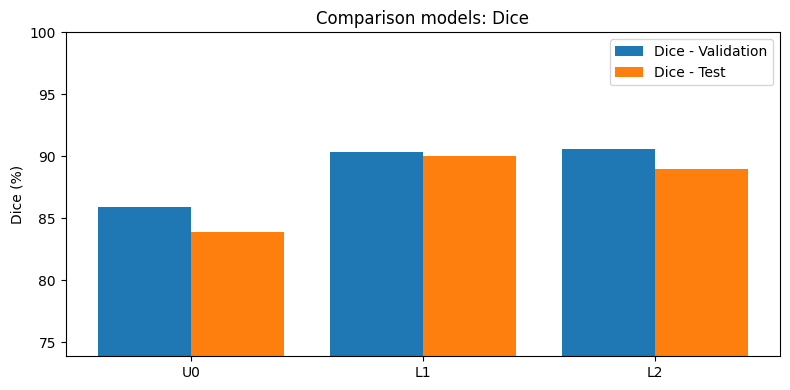

In [ ]:
# ============================================================
# COMPARISON MODELS: U0, L1, L2  (same protocol as ablation A0-A5)
# U0 = Baseline vanilla U-Net (from scratch)
# L1 = EfficientNetB0-UNet   L2 = MobileNetV3Large-UNet
# Self-contained: run in a fresh Kaggle notebook (GPU T4, Internet ON)
# ============================================================
import os, time, json, random
import numpy as np, pandas as pd, cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score

# ---------------- settings (identical to A0-A5) ----------------
SEED = 42
IMG_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 20
MAX_MIN_PER_VARIANT = 25
RUN = ["U0", "L1", "L2"]
OUT_DIR = "/kaggle/working/comparison"
os.makedirs(OUT_DIR, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE

ROOT = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
PATHS = {
    "train":      (f"{ROOT}/train/images/ISIC2018_Task1-2_Training_Input",
                   f"{ROOT}/train/masks/ISIC2018_Task1_Training_GroundTruth"),
    "validation": (f"{ROOT}/validation/images/ISIC2018_Task1-2_Validation_Input",
                   f"{ROOT}/validation/masks/ISIC2018_Task1_Validation_GroundTruth"),
    "test":       (f"{ROOT}/test/images/ISIC2018_Task1-2_Test_Input",
                   f"{ROOT}/test/masks/ISIC2018_Task1_Test_GroundTruth"),
}

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass
USE_MP = bool(gpus) and tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0))[0] >= 7
tf.keras.mixed_precision.set_global_policy("mixed_float16" if USE_MP else "float32")
print("GPUs:", gpus, "| Mixed precision:", USE_MP)

# ---------------- data: pair files and load once into RAM ----------------
def create_dataframe(image_path, mask_path):
    masks = {m.replace("_segmentation.png", ""): m for m in os.listdir(mask_path)
             if m.lower().endswith((".png", ".jpg", ".jpeg"))}
    rows = [(os.path.join(image_path, f), os.path.join(mask_path, masks[f.replace(".jpg", "")]))
            for f in sorted(os.listdir(image_path))
            if f.lower().endswith((".jpg", ".jpeg", ".png")) and f.replace(".jpg", "") in masks]
    return pd.DataFrame(rows, columns=["image", "mask"])

def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)[..., None]

def load_split(df, name):
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, df["image"], df["mask"]))
    X = np.stack([r[0] for r in res]); Y = np.stack([r[1] for r in res])
    print(f"{name}: {len(X)} images loaded in {time.time()-t0:.0f}s")
    return X, Y

dfs = {k: create_dataframe(*v) for k, v in PATHS.items()}
X_train, Y_train = load_split(dfs["train"], "train")
X_val,   Y_val   = load_split(dfs["validation"], "validation")
X_test,  Y_test  = load_split(dfs["test"], "test")

# ---------------- tf.data pipeline + augmentation (same as A0-A5) ----------------
def augment(x, y):
    x = tf.cast(x, tf.float32) / 255.0
    y = tf.cast(y, tf.float32)
    xy = tf.concat([x, y], axis=-1)
    xy = tf.image.random_flip_left_right(xy)
    xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x, y = xy[..., :3], xy[..., 3:]
    x = tf.image.random_brightness(x, 0.15)
    x = tf.image.random_contrast(x, 0.85, 1.15)
    x = tf.image.random_saturation(x, 0.85, 1.15)
    x = tf.image.random_hue(x, 0.03)
    x = tf.clip_by_value(x, 0.0, 1.0)
    return x * 2.0 - 1.0, y

def no_augment(x, y):
    return tf.cast(x, tf.float32) / 127.5 - 1.0, tf.cast(y, tf.float32)

def make_ds(X, Y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True).map(augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(no_augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, Y_train, True)
val_ds   = make_ds(X_val, Y_val, False).cache()
test_ds  = make_ds(X_test, Y_test, False)

# ---------------- models ----------------
def conv_block(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def light_decoder(inp, s1, s2, s3, s4, bridge):
    # identical decoder to KZ-SkinNet (A0)
    x = conv_block(bridge, 128, "bridge")
    for skip, f, n in [(s4, 96, "dec4"), (s3, 64, "dec3"), (s2, 32, "dec2"), (s1, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        x = layers.Concatenate(name=n + "_cat")([x, skip])
        x = conv_block(x, f, n)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x)
    return models.Model(inp, out)

def features_by_resolution(backbone):
    feats = {}
    for l in backbone.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8):
                feats[s[1]] = l.output
        except Exception:
            pass
    return feats[128], feats[64], feats[32], feats[16], feats[8]

def build_effb0_unet(weights="imagenet"):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x255 = layers.Lambda(lambda t: (t + 1.0) * 127.5, name="to_0_255")(inp)   # EfficientNet expects [0,255]
    bb = tf.keras.applications.EfficientNetB0(input_tensor=x255, include_top=False, weights=weights)
    g = lambda n: bb.get_layer(n).output
    return light_decoder(inp, g("block2a_expand_activation"), g("block3a_expand_activation"),
                         g("block4a_expand_activation"), g("block6a_expand_activation"), g("top_activation"))

def build_v3large_unet(weights="imagenet"):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Large(input_tensor=inp, include_top=False,
                                                weights=weights, include_preprocessing=False)
    return light_decoder(inp, *features_by_resolution(bb))

def unet_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{name}_c{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_r{i}")(x)
    return x

def build_vanilla_unet(weights=None, filters=(64, 128, 256, 512, 1024)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    skips, x = [], inp
    for i, f in enumerate(filters[:-1]):
        x = unet_block(x, f, f"enc{i+1}"); skips.append(x)
        x = layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = unet_block(x, filters[-1], "bottleneck")
    for i, (f, s) in enumerate(zip(reversed(filters[:-1]), reversed(skips))):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i+1}")(x)
        x = layers.Concatenate(name=f"cat{i+1}")([x, s])
        x = unet_block(x, f, f"dec{i+1}")
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x)
    return models.Model(inp, out, name="Vanilla_UNet")

MODELS = {
    "U0": ("Baseline U-Net (vanilla, from scratch)",  build_vanilla_unet),
    "L1": ("EfficientNetB0-UNet (SepConv decoder)",   build_effb0_unet),
    "L2": ("MobileNetV3Large-UNet (SepConv decoder)", build_v3large_unet),
}

# ---------------- loss (0.5 BCE + 0.5 Dice, same as A0) ----------------
SMOOTH = 1e-6
def dice_coefficient(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1]); y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (2.0 * inter + SMOOTH) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + SMOOTH)
def iou_score(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1]); y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (inter + SMOOTH) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - inter + SMOOTH)
_bce = tf.keras.losses.BinaryCrossentropy()
def bce_dice_loss(y_true, y_pred):
    return 0.5 * _bce(y_true, tf.cast(y_pred, tf.float32)) + 0.5 * (1.0 - dice_coefficient(y_true, y_pred))

# ---------------- training helpers ----------------
class TimeLimit(tf.keras.callbacks.Callback):
    def __init__(self, minutes):
        super().__init__(); self.limit = minutes * 60
    def on_train_begin(self, logs=None): self.t0 = time.time()
    def on_epoch_begin(self, epoch, logs=None): self.te = time.time()
    def on_epoch_end(self, epoch, logs=None):
        dt = time.time() - self.te; total = time.time() - self.t0
        print(f"   -> epoch {epoch+1}: {dt:.0f}s | total {total/60:.1f} min")
        if total + dt > self.limit:
            print("   Time limit reached, stopping."); self.model.stop_training = True

def pooled_metrics(model, ds, Y):
    prob = model.predict(ds, verbose=0).reshape(-1)
    y = Y.reshape(-1).astype(bool); p = prob >= 0.5
    TP = np.sum(y & p); TN = np.sum(~y & ~p); FP = np.sum(~y & p); FN = np.sum(y & ~p); e = 1e-7
    idx = np.random.RandomState(0).choice(len(y), min(len(y), 2_000_000), replace=False)
    return dict(Accuracy=(TP+TN)/(TP+TN+FP+FN), Precision=TP/(TP+FP+e), Sensitivity=TP/(TP+FN+e),
                Specificity=TN/(TN+FP+e), Dice=2*TP/(2*TP+FP+FN+e), IoU=TP/(TP+FP+FN+e),
                AUC=roc_auc_score(y[idx], prob[idx]))

def run_model(key, weights="imagenet"):
    res_file = f"{OUT_DIR}/{key}_result.json"
    if os.path.exists(res_file):
        print(key, "already done, loading saved result"); return json.load(open(res_file))
    desc, builder = MODELS[key]
    print(f"\n########## {key}: {desc}")
    tf.keras.backend.clear_session()
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
    model = builder(weights=weights)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=bce_dice_loss,
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), dice_coefficient, iou_score])
    print("Parameters:", f"{model.count_params():,}")
    ckpt = f"{OUT_DIR}/{key}_best.weights.h5"
    cbs = [tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
           tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, verbose=1),
           tf.keras.callbacks.CSVLogger(f"{OUT_DIR}/{key}_history.csv"),
           TimeLimit(MAX_MIN_PER_VARIANT)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cbs, verbose=2)
    minutes = round((time.time() - t0) / 60, 1)
    model.load_weights(ckpt)                       # best val_loss checkpoint
    out = {"ID": key, "Model": desc, "Params": int(model.count_params()),
           "Epochs": len(hist.history["loss"]), "Minutes": minutes}
    for set_name, ds, Y in [("val", val_ds, Y_val), ("test", test_ds, Y_test)]:
        for m, v in pooled_metrics(model, ds, Y).items():
            out[f"{set_name}_{m}"] = float(v)
    json.dump(out, open(res_file, "w"), indent=1)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in out.items()})
    return out

# ---------------- run all three ----------------
results = [run_model(k) for k in RUN]

# ---------------- tables: validation and test ----------------
METRICS = ["Accuracy", "Precision", "Sensitivity", "Specificity", "Dice", "IoU", "AUC"]
df = pd.DataFrame(results)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
tables = []
for set_name, label in [("val", "Validation (n=100)"), ("test", "Test (n=1000)")]:
    t = df[["ID", "Model", "Params"]].copy()
    for m in METRICS:
        t[m] = (df[f"{set_name}_{m}"] * 100).round(2)
    t["Epochs"] = df["Epochs"]; t["Minutes"] = df["Minutes"]
    t["Params"] = t["Params"].map(lambda p: f"{int(p):,}")
    print(f"\nComparison models - ISIC 2018 {label} (pixel-level pooled metrics, %)")
    display(t)
    t.insert(0, "Set", label); tables.append(t)
pd.concat(tables).to_csv(f"{OUT_DIR}/comparison_val_test.csv", index=False)
print("Saved:", f"{OUT_DIR}/comparison_val_test.csv")

# ---------------- chart ----------------
x = np.arange(len(df))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, df["val_Dice"] * 100, 0.4, label="Dice - Validation")
plt.bar(x + 0.2, df["test_Dice"] * 100, 0.4, label="Dice - Test")
plt.xticks(x, df["ID"]); plt.ylabel("Dice (%)")
plt.ylim(max(0, min(df["val_Dice"].min(), df["test_Dice"].min()) * 100 - 10), 100)
plt.title("Comparison models: Dice"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/comparison_dice.png", dpi=300); plt.show()

In [ ]:
# ============================================================
# FIX + RERUN (single cell)
#  1) U0 (vanilla U-Net) retrained WITHOUT the 25-min time limit
#     -> same rule as every other model: max 20 epochs + EarlyStopping(5) + ReduceLR(2)
#  2) L1 evaluated with the correct EfficientNet preprocessing (weights="imagenet" graph)
#  3) Final comparison table A0 vs U0, L1, L2 on validation + test
# Needs: A0, L1, L2 checkpoints (/kaggle/working or attached notebook output), GPU T4, Internet ON
# ============================================================
import os, glob, json, time, random
import numpy as np, pandas as pd, cv2
import tensorflow as tf
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score

SEED, IMG_SIZE, BATCH_SIZE, EPOCHS, THRESHOLD = 42, 256, 16, 20, 0.5
U0_DIR  = "/kaggle/working/comparison_v2"          # new U0 run goes here (old one is kept)
OUT_DIR = "/kaggle/working/comparison_table_v2"
os.makedirs(U0_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE

R18 = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
PATHS = {
    "train":      (f"{R18}/train/images/ISIC2018_Task1-2_Training_Input",
                   f"{R18}/train/masks/ISIC2018_Task1_Training_GroundTruth"),
    "Validation": (f"{R18}/validation/images/ISIC2018_Task1-2_Validation_Input",
                   f"{R18}/validation/masks/ISIC2018_Task1_Validation_GroundTruth"),
    "Test":       (f"{R18}/test/images/ISIC2018_Task1-2_Test_Input",
                   f"{R18}/test/masks/ISIC2018_Task1_Test_GroundTruth"),
}

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError: pass
USE_MP = bool(gpus) and tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0))[0] >= 7
tf.keras.mixed_precision.set_global_policy("mixed_float16" if USE_MP else "float32")
print("GPUs:", len(gpus), "| Mixed precision:", USE_MP)

# ---------------- data ----------------
def create_dataframe(image_path, mask_path):
    masks = {m.replace("_segmentation.png", ""): m for m in os.listdir(mask_path) if m.lower().endswith(".png")}
    rows = [(os.path.join(image_path, f), os.path.join(mask_path, masks[f[:-4]]))
            for f in sorted(os.listdir(image_path)) if f.lower().endswith(".jpg") and f[:-4] in masks]
    return pd.DataFrame(rows, columns=["image", "mask"])

def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)[..., None]

DATA = {}
for name, (i_dir, m_dir) in PATHS.items():
    df = create_dataframe(i_dir, m_dir); t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, df["image"], df["mask"]))
    DATA[name] = (np.stack([r[0] for r in res]), np.stack([r[1] for r in res]))
    print(f"{name}: {len(df)} images ({time.time()-t0:.0f}s)")

def augment(x, y):
    x = tf.cast(x, tf.float32) / 255.0; y = tf.cast(y, tf.float32)
    xy = tf.concat([x, y], -1)
    xy = tf.image.random_flip_left_right(xy); xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x, y = xy[..., :3], xy[..., 3:]
    x = tf.image.random_brightness(x, 0.15); x = tf.image.random_contrast(x, 0.85, 1.15)
    x = tf.image.random_saturation(x, 0.85, 1.15); x = tf.image.random_hue(x, 0.03)
    return tf.clip_by_value(x, 0.0, 1.0) * 2.0 - 1.0, y

def no_augment(x, y):
    return tf.cast(x, tf.float32) / 127.5 - 1.0, tf.cast(y, tf.float32)

def make_ds(X, Y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    ds = (ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True).map(augment, num_parallel_calls=AUTOTUNE)
          if training else ds.map(no_augment, num_parallel_calls=AUTOTUNE))
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(*DATA["train"], True)
val_ds   = make_ds(*DATA["Validation"], False).cache()

# ---------------- architectures ----------------
def conv_block(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def light_decoder(inp, s1, s2, s3, s4, bridge):
    x = conv_block(bridge, 128, "bridge")
    for skip, f, n in [(s4, 96, "dec4"), (s3, 64, "dec3"), (s2, 32, "dec2"), (s1, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        x = layers.Concatenate(name=n + "_cat")([x, skip])
        x = conv_block(x, f, n)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x))

def features_by_resolution(bb):
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8): feats[s[1]] = l.output
        except Exception: pass
    return feats[128], feats[64], feats[32], feats[16], feats[8]

def build_A0():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Small(input_tensor=inp, include_top=False, weights=None, include_preprocessing=False)
    return light_decoder(inp, *features_by_resolution(bb))

def build_L1():
    # weights="imagenet" is REQUIRED here: it adds EfficientNet's extra input-rescaling layer
    # that the model was trained with (weights=None silently drops it). Trained weights are loaded afterwards.
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x255 = layers.Lambda(lambda t: (t + 1.0) * 127.5, name="to_0_255")(inp)
    bb = tf.keras.applications.EfficientNetB0(input_tensor=x255, include_top=False, weights="imagenet")
    g = lambda n: bb.get_layer(n).output
    return light_decoder(inp, g("block2a_expand_activation"), g("block3a_expand_activation"),
                         g("block4a_expand_activation"), g("block6a_expand_activation"), g("top_activation"))

def build_L2():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Large(input_tensor=inp, include_top=False, weights=None, include_preprocessing=False)
    return light_decoder(inp, *features_by_resolution(bb))

def unet_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{name}_c{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_r{i}")(x)
    return x

def build_U0(filters=(64, 128, 256, 512, 1024)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3)); skips, x = [], inp
    for i, f in enumerate(filters[:-1]):
        x = unet_block(x, f, f"enc{i+1}"); skips.append(x); x = layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = unet_block(x, filters[-1], "bottleneck")
    for i, (f, s) in enumerate(zip(reversed(filters[:-1]), reversed(skips))):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i+1}")(x)
        x = layers.Concatenate(name=f"cat{i+1}")([x, s]); x = unet_block(x, f, f"dec{i+1}")
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x), name="Vanilla_UNet")

# ---------------- loss ----------------
SMOOTH = 1e-6
def dice_coefficient(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1]); y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (2.0 * inter + SMOOTH) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + SMOOTH)
_bce = tf.keras.losses.BinaryCrossentropy()
def bce_dice_loss(y_true, y_pred):
    return 0.5 * _bce(y_true, tf.cast(y_pred, tf.float32)) + 0.5 * (1.0 - dice_coefficient(y_true, y_pred))

class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.t0 = time.time()
    def on_epoch_begin(self, epoch, logs=None): self.te = time.time()
    def on_epoch_end(self, epoch, logs=None):
        print(f"   -> epoch {epoch+1}: {time.time()-self.te:.0f}s | total {(time.time()-self.t0)/60:.1f} min")

# ---------------- 1) retrain U0 without time limit ----------------
U0_CKPT, U0_INFO = f"{U0_DIR}/U0_best.weights.h5", f"{U0_DIR}/U0_result.json"
if os.path.exists(U0_INFO):
    print("U0 (v2) already trained - skipping training")
else:
    print("\n########## Retraining U0: Baseline U-Net (no time limit, max 20 epochs)")
    tf.keras.backend.clear_session()
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
    u0 = build_U0()
    u0.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=bce_dice_loss,
               metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), dice_coefficient])
    t0 = time.time()
    hist = u0.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2, callbacks=[
        tf.keras.callbacks.ModelCheckpoint(U0_CKPT, monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, verbose=1),
        tf.keras.callbacks.CSVLogger(f"{U0_DIR}/U0_history.csv"), EpochTimer()])
    json.dump({"Epochs": len(hist.history["loss"]), "Minutes": round((time.time() - t0) / 60, 1)}, open(U0_INFO, "w"))
    del u0

# ---------------- 2) evaluate A0, U0, L1, L2 the same way ----------------
def find_ckpt(key):
    if key == "U0":
        return U0_CKPT
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits = sorted(glob.glob(os.path.join(d, "**", f"{key}_best.weights.h5"), recursive=True))
        if hits: return hits[0]
    return None

def find_info(key):
    if key == "U0":
        return json.load(open(U0_INFO))
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits = sorted(glob.glob(os.path.join(d, "**", f"{key}_result.json"), recursive=True))
        if hits: return json.load(open(hits[0]))
    return {}

def pixel_metrics(prob, y):
    p = prob >= THRESHOLD
    TP = np.sum(y & p); TN = np.sum(~y & ~p); FP = np.sum(~y & p); FN = np.sum(y & ~p)
    prec, rec = TP / (TP + FP + 1e-12), TP / (TP + FN + 1e-12)
    return {"Dice": 2*TP/(2*TP+FP+FN), "IoU": TP/(TP+FP+FN), "Accuracy": (TP+TN)/(TP+TN+FP+FN),
            "Precision": prec, "Recall": rec, "Specificity": TN/(TN+FP),
            "F1-score": 2*prec*rec/(prec+rec+1e-12), "AUC": roc_auc_score(y, prob),
            "TP": int(TP), "FP": int(FP), "FN": int(FN), "TN": int(TN)}

ORDER = ["A0", "U0", "L1", "L2"]
NAMES = {"A0": "KZ-SkinNet (Proposed)", "U0": "Baseline U-Net (vanilla)",
         "L1": "EfficientNetB0-UNet", "L2": "MobileNetV3Large-UNet"}
BUILDERS = {"A0": build_A0, "U0": build_U0, "L1": build_L1, "L2": build_L2}
EVAL = {s: (DATA[s][0].astype(np.float32) / 127.5 - 1.0, DATA[s][1].reshape(-1).astype(bool)) for s in ["Validation", "Test"]}

rows = []
for k in ORDER:
    ckpt = find_ckpt(k)
    if not ckpt or not os.path.exists(ckpt):
        print(f"{k}: checkpoint not found, skipped"); continue
    tf.keras.backend.clear_session()
    model = BUILDERS[k](); model.load_weights(ckpt)
    info = find_info(k)
    for s, (X, Y) in EVAL.items():
        r = pixel_metrics(model.predict(X, batch_size=BATCH_SIZE, verbose=0).reshape(-1), Y)
        r.update(Set=s, ID=k, Model=NAMES[k], Params=model.count_params(), Epochs=info.get("Epochs"))
        rows.append(r)
    print(f"{k}: evaluated ({ckpt})")

# ---------------- 3) tables ----------------
METRICS = ["Dice", "IoU", "Accuracy", "Precision", "Recall", "Specificity", "F1-score", "AUC"]
full = pd.DataFrame(rows)
table = full[["Set", "ID", "Model", "Params", "Epochs"] + METRICS].copy()
table[METRICS] = (table[METRICS] * 100).round(2)
a0 = table[table["ID"] == "A0"].set_index("Set")["Dice"]
table["Δ Dice vs A0"] = (table["Dice"] - table["Set"].map(a0)).round(2)
table["Params"] = table["Params"].map(lambda p: f"{int(p):,}")

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
for s in ["Validation", "Test"]:
    n = len(EVAL[s][1]) // (IMG_SIZE * IMG_SIZE)
    print(f"\nKZ-SkinNet vs comparison models - ISIC 2018 {s} (n={n}), pixel-level pooled metrics (%)")
    display(table[table["Set"] == s].drop(columns="Set").reset_index(drop=True))
print("\nPixel-level confusion counts")
display(full[["Set", "ID", "TP", "FP", "FN", "TN"]])

table.to_csv(f"{OUT_DIR}/comparison_A0_U0_L1_L2_val_test_v2.csv", index=False)
full[["Set", "ID", "TP", "FP", "FN", "TN"]].to_csv(f"{OUT_DIR}/comparison_confusion_counts_v2.csv", index=False)
print("Saved to", OUT_DIR)

GPUs: 2 | Mixed precision: True
train: 2594 images (212s)
Validation: 100 images (5s)
Test: 1000 images (44s)

########## Retraining U0: Baseline U-Net (no time limit, max 20 epochs)
Epoch 1/20
   -> epoch 1: 177s | total 3.0 min
163/163 - 177s - 1s/step - accuracy: 0.7986 - dice_coefficient: 0.4959 - loss: 0.4935 - val_accuracy: 0.8297 - val_dice_coefficient: 0.4780 - val_loss: 0.4896 - learning_rate: 1.0000e-04
Epoch 2/20
   -> epoch 2: 148s | total 5.4 min
163/163 - 148s - 906ms/step - accuracy: 0.9084 - dice_coefficient: 0.6263 - loss: 0.3301 - val_accuracy: 0.8953 - val_dice_coefficient: 0.6881 - val_loss: 0.3145 - learning_rate: 1.0000e-04
Epoch 3/20
   -> epoch 3: 145s | total 7.8 min
163/163 - 145s - 889ms/step - accuracy: 0.9201 - dice_coefficient: 0.6731 - loss: 0.2861 - val_accuracy: 0.9057 - val_dice_coefficient: 0.7353 - val_loss: 0.2772 - learning_rate: 1.0000e-04
Epoch 4/20
   -> epoch 4: 146s | total 10.3 min
163/163 - 146s - 898ms/step - accuracy: 0.9275 - dice_coeffic

,ID,Model,Params,Epochs,Dice,IoU,Accuracy,Precision,Recall,Specificity,F1-score,AUC,Δ Dice vs A0
0,A0,KZ-SkinNet (Proposed),"1,083,865",20,91.51,84.34,95.31,89.05,94.10,95.76,91.51,99.04,0.00
1,U0,Baseline U-Net (vanilla),"31,049,409",20,88.16,78.83,93.75,89.64,86.73,96.32,88.16,97.96,-3.35
2,L1,EfficientNetB0-UNet,"4,346,548",17,90.35,82.40,94.67,87.89,92.95,95.30,90.35,97.95,-1.16
3,L2,MobileNetV3Large-UNet,"3,245,737",19,90.58,82.78,94.71,86.69,94.84,94.66,90.58,98.98,-0.93



KZ-SkinNet vs comparison models - ISIC 2018 Test (n=1000), pixel-level pooled metrics (%)


,ID,Model,Params,Epochs,Dice,IoU,Accuracy,Precision,Recall,Specificity,F1-score,AUC,Δ Dice vs A0
0,A0,KZ-SkinNet (Proposed),"1,083,865",20,89.62,81.19,94.07,87.73,91.60,95.02,89.62,97.85,0.00
1,U0,Baseline U-Net (vanilla),"31,049,409",20,86.53,76.26,92.72,89.65,83.62,96.25,86.53,96.72,-3.09
2,L1,EfficientNetB0-UNet,"4,346,548",17,90.02,81.85,94.29,88.09,92.04,95.17,90.02,97.78,0.40
3,L2,MobileNetV3Large-UNet,"3,245,737",19,88.96,80.11,93.59,85.89,92.25,94.11,88.96,97.83,-0.66



Pixel-level confusion counts


,Set,ID,TP,FP,FN,TN
0,Validation,A0,1654887,203485,103679,4591549
1,Test,A0,16789630,2348565,1540340,44857465
2,Validation,U0,1525147,176276,233419,4618758
3,Test,U0,15327713,1769295,3002257,45436735
4,Validation,L1,1634582,225241,123984,4569793
5,Test,L1,16871803,2281907,1458167,44924123
6,Validation,L2,1667813,256159,90753,4538875
7,Test,L2,16909882,2778278,1420088,44427752


Saved to /kaggle/working/comparison_table_v2


## 4. KZ-SkinNet (A0): overall metrics, external testing and data-leakage check

In [ ]:
# ============================================================
# KZ-SkinNet (A0): OVERALL VALIDATION + TEST METRICS
# Dice, IoU, Accuracy, Precision, Recall, F1-score, AUC
# Aggregation: global pixel-level (all pixels of all images pooled), threshold 0.5
# Self-contained: run in any Kaggle notebook with the ISIC 2018 dataset attached
# ============================================================
import os, glob, time
import numpy as np, pandas as pd, cv2
import tensorflow as tf
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score

IMG_SIZE, BATCH_SIZE, THRESHOLD = 256, 16, 0.5
OUT_DIR = "/kaggle/working/A0_evaluation"
os.makedirs(OUT_DIR, exist_ok=True)

ROOT = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
PATHS = {
    "Validation": (f"{ROOT}/validation/images/ISIC2018_Task1-2_Validation_Input",
                   f"{ROOT}/validation/masks/ISIC2018_Task1_Validation_GroundTruth"),
    "Test":       (f"{ROOT}/test/images/ISIC2018_Task1-2_Test_Input",
                   f"{ROOT}/test/masks/ISIC2018_Task1_Test_GroundTruth"),
}

# ---------------- find the A0 checkpoint (current session or attached notebook output) ----------------
ckpts = (sorted(glob.glob("/kaggle/working/**/A0_best.weights.h5", recursive=True)) +
         sorted(glob.glob("/kaggle/input/**/A0_best.weights.h5", recursive=True)))
assert ckpts, "A0_best.weights.h5 not found - run A0 first or attach its notebook output"
CKPT = ckpts[0]
print("A0 checkpoint:", CKPT)

# ---------------- A0 architecture (identical to the ablation run) ----------------
def conv_block(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def build_kz_skinnet():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Small(input_tensor=inp, include_top=False,
                                                weights=None, include_preprocessing=False)
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8):
                feats[s[1]] = l.output
        except Exception:
            pass
    x = conv_block(feats[8], 128, "bridge")
    for res, f, n in [(16, 96, "dec4"), (32, 64, "dec3"), (64, 32, "dec2"), (128, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        x = layers.Concatenate(name=n + "_cat")([x, feats[res]])
        x = conv_block(x, f, n)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x)
    return models.Model(inp, out)

model = build_kz_skinnet()
model.load_weights(CKPT)
print("Parameters:", f"{model.count_params():,}")

# ---------------- data ----------------
def create_dataframe(image_path, mask_path):
    masks = {m.replace("_segmentation.png", ""): m for m in os.listdir(mask_path)
             if m.lower().endswith((".png", ".jpg", ".jpeg"))}
    rows = [(os.path.join(image_path, f), os.path.join(mask_path, masks[f.replace(".jpg", "")]))
            for f in sorted(os.listdir(image_path))
            if f.lower().endswith((".jpg", ".jpeg", ".png")) and f.replace(".jpg", "") in masks]
    return pd.DataFrame(rows, columns=["image", "mask"])

def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)

def load_split(df):
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, df["image"], df["mask"]))
    return np.stack([r[0] for r in res]), np.stack([r[1] for r in res])

# ---------------- evaluation ----------------
rows, counts = [], []
for set_name, (img_dir, mask_dir) in PATHS.items():
    df = create_dataframe(img_dir, mask_dir)
    X, Y = load_split(df)
    t0 = time.time()
    prob = model.predict(X.astype(np.float32) / 127.5 - 1.0, batch_size=BATCH_SIZE, verbose=0)[..., 0]
    y = Y.reshape(-1).astype(bool)
    p_prob = prob.reshape(-1)
    p = p_prob >= THRESHOLD
    TP = int(np.sum(y & p)); TN = int(np.sum(~y & ~p)); FP = int(np.sum(~y & p)); FN = int(np.sum(y & ~p))
    precision = TP / (TP + FP)
    recall    = TP / (TP + FN)
    rows.append({
        "Dataset":   f"ISIC 2018 {set_name} (n={len(df)})",
        "Dice":      2 * TP / (2 * TP + FP + FN),
        "IoU":       TP / (TP + FP + FN),
        "Accuracy":  (TP + TN) / (TP + TN + FP + FN),
        "Precision": precision,
        "Recall":    recall,
        "F1-score":  2 * precision * recall / (precision + recall),
        "AUC":       roc_auc_score(y, p_prob),          # all pixels, no subsampling
    })
    counts.append({"Dataset": set_name, "Images": len(df), "Pixels": y.size,
                   "TP": TP, "FP": FP, "FN": FN, "TN": TN})
    print(f"{set_name}: {len(df)} images evaluated in {time.time()-t0:.0f}s")

metrics = pd.DataFrame(rows)
cols = ["Dice", "IoU", "Accuracy", "Precision", "Recall", "F1-score", "AUC"]
metrics_pct = metrics.copy(); metrics_pct[cols] = (metrics_pct[cols] * 100).round(2)

pd.set_option("display.width", 250)
print("\nKZ-SkinNet (A0) - overall pixel-level performance (%), threshold = 0.5")
display(metrics_pct)
print("\nPixel-level confusion counts (lesion = positive class)")
display(pd.DataFrame(counts))

metrics_pct.to_csv(f"{OUT_DIR}/A0_overall_val_test_metrics.csv", index=False)
pd.DataFrame(counts).to_csv(f"{OUT_DIR}/A0_pixel_confusion_counts.csv", index=False)
print("Saved to", OUT_DIR)

A0 checkpoint: /kaggle/working/ablation/A0_best.weights.h5
Parameters: 1,083,865
Validation: 100 images evaluated in 15s
Test: 1000 images evaluated in 39s

KZ-SkinNet (A0) - overall pixel-level performance (%), threshold = 0.5


,Dataset,Dice,IoU,Accuracy,Precision,Recall,F1-score,AUC
0,ISIC 2018 Validation (n=100),91.51,84.34,95.31,89.05,94.1,91.51,99.04
1,ISIC 2018 Test (n=1000),89.62,81.19,94.07,87.73,91.6,89.62,97.85



Pixel-level confusion counts (lesion = positive class)


,Dataset,Images,Pixels,TP,FP,FN,TN
0,Validation,100,6553600,1654887,203485,103679,4591549
1,Test,1000,65536000,16789630,2348565,1540340,44857465


Saved to /kaggle/working/A0_evaluation


In [ ]:
# ============================================================
# A0 (KZ-SkinNet): EXTERNAL TESTING on ISIC 2016 test + PH2
# and DATA-LEAKAGE CHECK between ISIC 2016 / PH2 and ISIC 2018
# Leakage is checked two ways:
#   (1) same ISIC image ID (ISIC_xxxxxxx) in both datasets
#   (2) same image content (perceptual hash + pixel correlation), catches renamed copies
# ============================================================
import os, re, glob, time
import numpy as np, pandas as pd, cv2
import tensorflow as tf
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score

IMG_SIZE, BATCH_SIZE, THRESHOLD = 256, 16, 0.5
OUT_DIR = "/kaggle/working/external_and_leakage"
os.makedirs(OUT_DIR, exist_ok=True)

R18 = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
ISIC2018 = {
    "ISIC2018-train": (f"{R18}/train/images/ISIC2018_Task1-2_Training_Input",
                       f"{R18}/train/masks/ISIC2018_Task1_Training_GroundTruth"),
    "ISIC2018-val":   (f"{R18}/validation/images/ISIC2018_Task1-2_Validation_Input",
                       f"{R18}/validation/masks/ISIC2018_Task1_Validation_GroundTruth"),
    "ISIC2018-test":  (f"{R18}/test/images/ISIC2018_Task1-2_Test_Input",
                       f"{R18}/test/masks/ISIC2018_Task1_Test_GroundTruth"),
}
R16 = "/kaggle/input/datasets/mahmudulhasantasin/isic-2016-original-dataset/isic 2016"
ISIC2016_IMG = f"{R16}/ISBI2016_ISIC_Part1_Test_Data"
ISIC2016_GT  = f"{R16}/ISBI2016_ISIC_Part1_Test_GroundTruth"
PH2_IMG = "/kaggle/input/datasets/athina123/ph2dataset/trainx"
PH2_GT  = "/kaggle/input/datasets/athina123/ph2dataset/trainy"

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

# ---------------- file pairing ----------------
def list_images(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if p.lower().endswith(IMG_EXT))

def key_of(path):
    name = os.path.basename(path)
    m = re.search(r"ISIC_(\d{7})", name, re.I)
    if m:
        return "ISIC_" + m.group(1)
    nums = re.findall(r"\d+", os.path.splitext(name)[0])
    return nums[-1] if nums else os.path.splitext(name)[0].lower()

def pair(img_dir, gt_dir):
    imgs = {key_of(p): p for p in list_images(img_dir)}
    gts  = {key_of(p): p for p in list_images(gt_dir)}
    keys = sorted(set(imgs) & set(gts))
    print(f"{os.path.basename(img_dir)}: {len(imgs)} images, {len(gts)} masks, {len(keys)} pairs")
    return pd.DataFrame({"key": keys, "image": [imgs[k] for k in keys], "mask": [gts[k] for k in keys]})

df18 = {k: pair(*v) for k, v in ISIC2018.items()}
df16 = pair(ISIC2016_IMG, ISIC2016_GT)
dfph2 = pair(PH2_IMG, PH2_GT)

# ---------------- (1) leakage by ISIC image ID ----------------
ids18 = {name: set(d["key"]) for name, d in df18.items()}
df16["in_2018_train_ID"] = df16["key"].isin(ids18["ISIC2018-train"])
df16["in_2018_val_ID"]   = df16["key"].isin(ids18["ISIC2018-val"])
df16["in_2018_test_ID"]  = df16["key"].isin(ids18["ISIC2018-test"])

# ---------------- (2) leakage by image content ----------------
def fingerprint(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    small = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    dhash = np.packbits((small[:, 1:] > small[:, :-1]).flatten())          # 64-bit difference hash
    thumb = cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32).flatten()
    thumb = (thumb - thumb.mean()) / (thumb.std() + 1e-6)
    return dhash, thumb

def fingerprints(paths):
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(fingerprint, paths))
    return np.stack([r[0] for r in res]), np.stack([r[1] for r in res])

t0 = time.time()
fp18 = {name: fingerprints(d["image"].tolist()) for name, d in df18.items()}
fp16 = fingerprints(df16["image"].tolist())
fpph2 = fingerprints(dfph2["image"].tolist())
print(f"Fingerprints computed in {time.time()-t0:.0f}s")

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def content_matches(fp_query, fp_ref, ham_max=10, corr_min=0.95):
    """for each query image: best matching reference index if it is a near-duplicate, else -1"""
    hq, tq = fp_query; hr, tr = fp_ref
    best = np.full(len(hq), -1); best_corr = np.zeros(len(hq))
    for i in range(len(hq)):
        ham = POP[np.bitwise_xor(hr, hq[i])].sum(axis=1)
        cand = np.where(ham <= ham_max)[0]
        if len(cand):
            corr = (tr[cand] @ tq[i]) / tq.shape[1]
            j = np.argmax(corr)
            if corr[j] >= corr_min:
                best[i], best_corr[i] = cand[j], corr[j]
    return best, best_corr

leak_rows = []
for ext_name, dfe, fpe in [("ISIC 2016 test", df16, fp16), ("PH2", dfph2, fpph2)]:
    any_dup = np.zeros(len(dfe), dtype=bool)
    for ref_name, dref in df18.items():
        idx, corr = content_matches(fpe, fp18[ref_name])
        dup = idx >= 0
        any_dup |= dup
        dfe[f"dup_{ref_name}"] = [dref["key"].iloc[j] if j >= 0 else "" for j in idx]
        id_overlap = int(dfe["key"].isin(ids18[ref_name]).sum()) if ext_name == "ISIC 2016 test" else 0
        leak_rows.append({"External set": ext_name, "Compared with": ref_name, "External images": len(dfe),
                          "Same ISIC ID": id_overlap, "Same image content": int(dup.sum())})
    id_any = dfe["key"].isin(set().union(*ids18.values())) if ext_name == "ISIC 2016 test" else np.zeros(len(dfe), bool)
    dfe["leaked"] = np.asarray(id_any) | any_dup
    leak_rows.append({"External set": ext_name, "Compared with": "ANY ISIC 2018 split", "External images": len(dfe),
                      "Same ISIC ID": int(np.sum(id_any)), "Same image content": int(any_dup.sum())})

leak = pd.DataFrame(leak_rows)
leak["% of external set"] = (100 * leak[["Same ISIC ID", "Same image content"]].max(axis=1) / leak["External images"]).round(1)
print("\n================ DATA-LEAKAGE CHECK ================")
display(leak)
df16.to_csv(f"{OUT_DIR}/isic2016_test_overlap_per_image.csv", index=False)
dfph2.to_csv(f"{OUT_DIR}/ph2_overlap_per_image.csv", index=False)
leak.to_csv(f"{OUT_DIR}/leakage_summary.csv", index=False)

# ---------------- A0 model ----------------
def conv_block(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def build_kz_skinnet():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Small(input_tensor=inp, include_top=False,
                                                weights=None, include_preprocessing=False)
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8):
                feats[s[1]] = l.output
        except Exception:
            pass
    x = conv_block(feats[8], 128, "bridge")
    for res, f, n in [(16, 96, "dec4"), (32, 64, "dec3"), (64, 32, "dec2"), (128, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        x = layers.Concatenate(name=n + "_cat")([x, feats[res]])
        x = conv_block(x, f, n)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x)
    return models.Model(inp, out)

ckpts = (sorted(glob.glob("/kaggle/working/**/A0_best.weights.h5", recursive=True)) +
         sorted(glob.glob("/kaggle/input/**/A0_best.weights.h5", recursive=True)))
assert ckpts, "A0_best.weights.h5 not found - attach the ablation notebook output"
model = build_kz_skinnet(); model.load_weights(ckpts[0])
print("\nA0 checkpoint:", ckpts[0])

# ---------------- evaluation (same preprocessing as ISIC 2018) ----------------
def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)

def evaluate(df, label):
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, df["image"], df["mask"]))
    X = np.stack([r[0] for r in res]).astype(np.float32) / 127.5 - 1.0
    Y = np.stack([r[1] for r in res]).astype(bool)
    prob = model.predict(X, batch_size=BATCH_SIZE, verbose=0)[..., 0]
    P = prob >= THRESHOLD
    # pixel-level pooled
    y, p = Y.reshape(-1), P.reshape(-1)
    TP = np.sum(y & p); TN = np.sum(~y & ~p); FP = np.sum(~y & p); FN = np.sum(y & ~p)
    prec, rec = TP / (TP + FP + 1e-12), TP / (TP + FN + 1e-12)
    # image-wise
    tp = (Y & P).sum((1, 2)); fp = (~Y & P).sum((1, 2)); fn = (Y & ~P).sum((1, 2))
    dice_i = 2 * tp / (2 * tp + fp + fn + 1e-12); iou_i = tp / (tp + fp + fn + 1e-12)
    return {"Dataset": label, "Images": len(df),
            "Dice": 2*TP/(2*TP+FP+FN), "IoU": TP/(TP+FP+FN), "Accuracy": (TP+TN)/(TP+TN+FP+FN),
            "Precision": prec, "Recall": rec, "Specificity": TN/(TN+FP),
            "F1-score": 2*prec*rec/(prec+rec+1e-12), "AUC": roc_auc_score(y, prob.reshape(-1)),
            "Image-wise Dice (mean±SD)": f"{100*dice_i.mean():.2f} ± {100*dice_i.std(ddof=1):.2f}",
            "Image-wise IoU (mean±SD)":  f"{100*iou_i.mean():.2f} ± {100*iou_i.std(ddof=1):.2f}",
            "TP": int(TP), "FP": int(FP), "FN": int(FN), "TN": int(TN)}

rows = [evaluate(df16, "ISIC 2016 test - all images")]
clean16 = df16[~df16["leaked"]]
if len(clean16) >= 10:
    rows.append(evaluate(clean16, "ISIC 2016 test - only images NOT in ISIC 2018"))
else:
    print(f"\nOnly {len(clean16)} ISIC 2016 test images are absent from ISIC 2018 - too few for a clean external test.")
rows.append(evaluate(dfph2, "PH2 - all images"))
if dfph2["leaked"].any():
    rows.append(evaluate(dfph2[~dfph2["leaked"]], "PH2 - only images NOT in ISIC 2018"))

ev = pd.DataFrame(rows)
M = ["Dice", "IoU", "Accuracy", "Precision", "Recall", "Specificity", "F1-score", "AUC"]
ev_pct = ev.copy(); ev_pct[M] = (ev_pct[M] * 100).round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("\n================ A0 EXTERNAL TESTING (pixel-level pooled metrics %, threshold 0.5) ================")
display(ev_pct.drop(columns=["TP", "FP", "FN", "TN"]))
print("\nPixel-level confusion counts")
display(ev_pct[["Dataset", "Images", "TP", "FP", "FN", "TN"]])
ev_pct.to_csv(f"{OUT_DIR}/A0_external_results.csv", index=False)
print("Saved to", OUT_DIR)

ISIC2018_Task1-2_Training_Input: 2594 images, 2594 masks, 2594 pairs
ISIC2018_Task1-2_Validation_Input: 100 images, 100 masks, 100 pairs
ISIC2018_Task1-2_Test_Input: 1000 images, 1000 masks, 1000 pairs
ISBI2016_ISIC_Part1_Test_Data: 379 images, 379 masks, 379 pairs
trainx: 200 images, 200 masks, 200 pairs
Fingerprints computed in 183s

================ DATA-LEAKAGE CHECK ================


,External set,Compared with,External images,Same ISIC ID,Same image content,% of external set
0,ISIC 2016 test,ISIC2018-train,379,339,342,90.2
1,ISIC 2016 test,ISIC2018-val,379,0,4,1.1
2,ISIC 2016 test,ISIC2018-test,379,0,7,1.8
3,ISIC 2016 test,ANY ISIC 2018 split,379,339,342,90.2
4,PH2,ISIC2018-train,200,0,0,0.0
5,PH2,ISIC2018-val,200,0,0,0.0
6,PH2,ISIC2018-test,200,0,0,0.0
7,PH2,ANY ISIC 2018 split,200,0,0,0.0



A0 checkpoint: /kaggle/working/ablation/A0_best.weights.h5

================ A0 EXTERNAL TESTING (pixel-level pooled metrics %, threshold 0.5) ================


,Dataset,Images,Dice,IoU,Accuracy,Precision,Recall,Specificity,F1-score,AUC,Image-wise Dice (mean±SD),Image-wise IoU (mean±SD)
0,ISIC 2016 test - all images,379,93.56,87.89,96.45,95.74,91.47,98.40,93.56,99.39,92.01 ± 8.47,86.03 ± 10.89
1,ISIC 2016 test - only images NOT in ISIC 2018,37,92.41,85.89,95.53,94.36,90.54,97.68,92.41,98.84,90.34 ± 9.83,83.52 ± 13.12
2,PH2 - all images,200,92.28,85.67,94.90,90.14,94.52,95.08,92.28,98.81,92.09 ± 7.07,86.01 ± 10.35



Pixel-level confusion counts


,Dataset,Images,TP,FP,FN,TN
0,ISIC 2016 test - all images,379,6401873,284903,597092,17554276
1,ISIC 2016 test - only images NOT in ISIC 2018,37,659639,39435,68918,1656840
2,PH2 - all images,200,3992621,436757,231287,8446535


Saved to /kaggle/working/external_and_leakage


**Leakage finding:** 342 of the 379 ISIC 2016 test images (90.2%) are also contained in the ISIC 2018 training set. ISIC 2016 is therefore reported only on the 37 non-overlapping images; PH2 (no overlap) is the external test set.

## 5. Qualitative results (TRUE: IoU ≥ 0.65 = ISIC 2018 thresholded-Jaccard criterion; FALSE: IoU < 0.65)

A0 checkpoint: /kaggle/working/ablation/A0_best.weights.h5
Test images: 1000 | TRUE (IoU >= 0.65): 898 | FALSE: 102


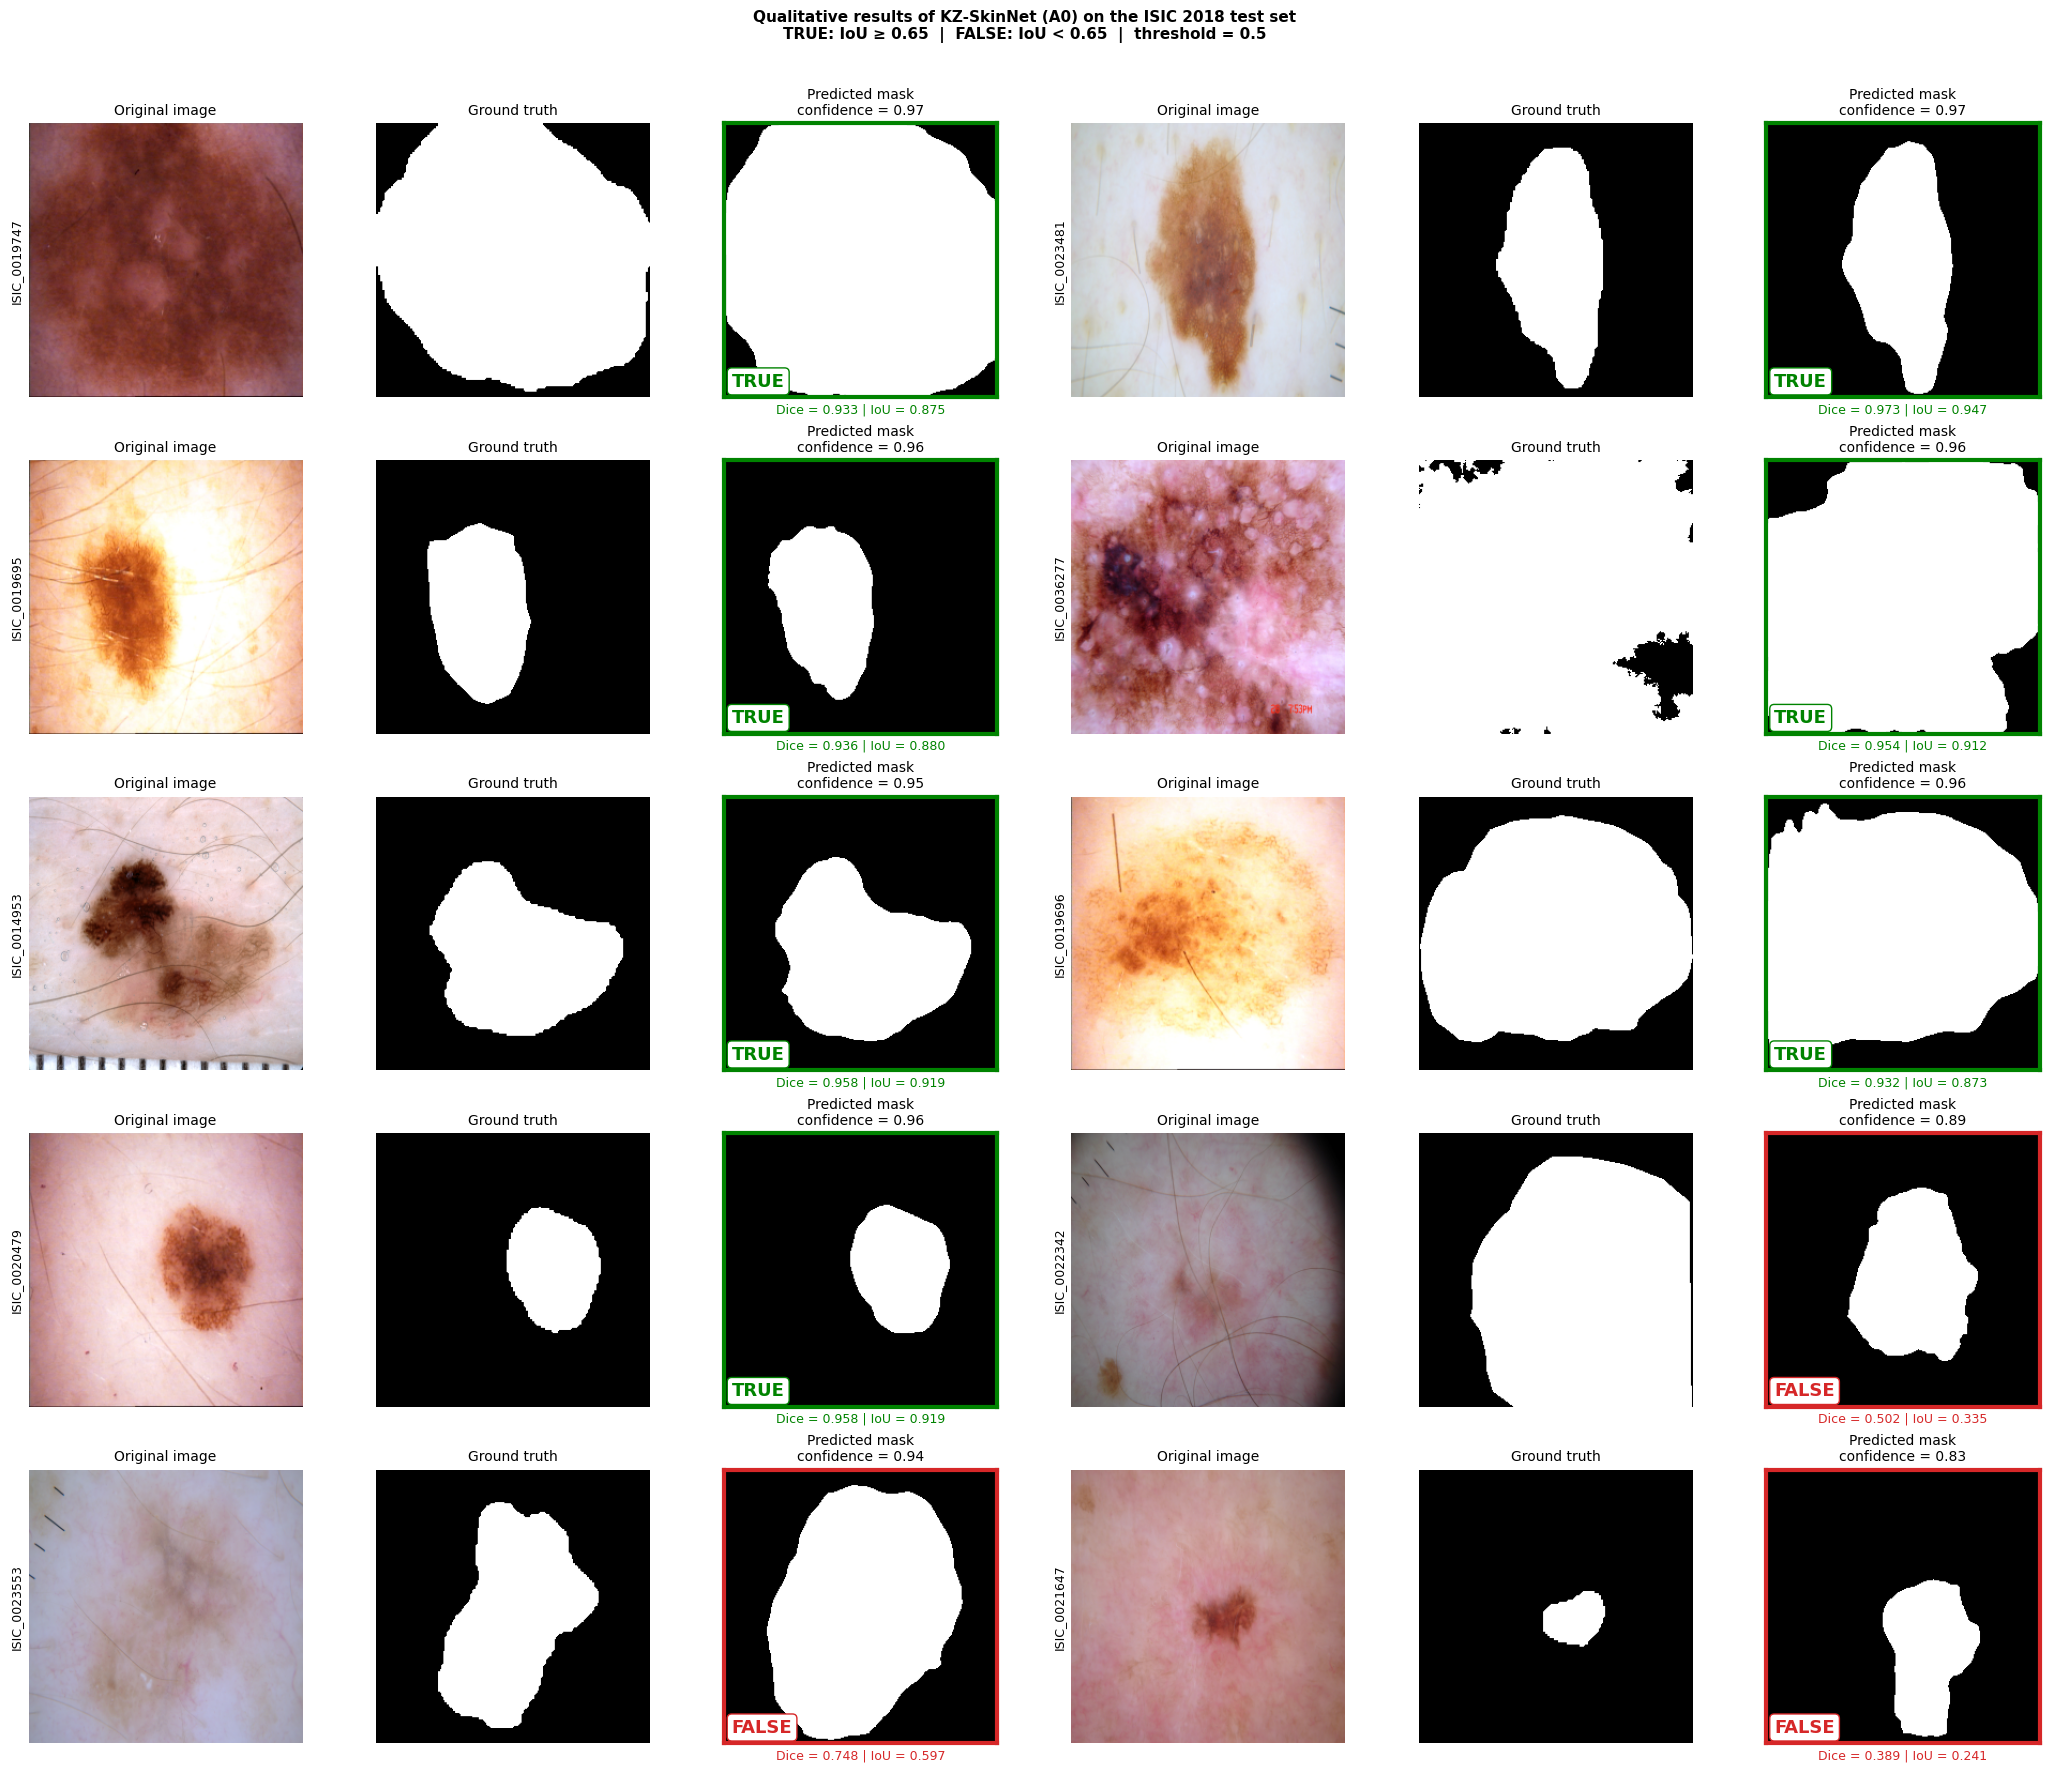

Saved: /kaggle/working/figures/A0_qualitative_10_samples.png


,Image,Dice,IoU,Confidence,Label
0,ISIC_0019747,0.9334,0.8751,0.9724,TRUE
1,ISIC_0023481,0.9728,0.9470,0.9653,TRUE
2,ISIC_0019695,0.9363,0.8802,0.9553,TRUE
3,ISIC_0036277,0.9538,0.9117,0.9640,TRUE
4,ISIC_0014953,0.9578,0.9190,0.9523,TRUE
5,ISIC_0019696,0.9323,0.8732,0.9589,TRUE
6,ISIC_0020479,0.9578,0.9191,0.9630,TRUE
7,ISIC_0022342,0.5019,0.3350,0.8851,FALSE
8,ISIC_0023553,0.7479,0.5973,0.9433,FALSE
9,ISIC_0021647,0.3886,0.2412,0.8270,FALSE


In [ ]:
# ============================================================
# A0 (KZ-SkinNet): QUALITATIVE RESULTS - 10 ISIC 2018 test samples
# Columns: Original image | Ground truth | Predicted mask (+ confidence score)
# TRUE (green)  = prediction agrees with ground truth  (IoU >= 0.65)
# FALSE (red)   = prediction disagrees with ground truth (IoU < 0.65)
# IoU 0.65 is the ISIC 2018 challenge "thresholded Jaccard" cut-off
# ============================================================
import os, glob
import numpy as np, pandas as pd, cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor

IMG_SIZE, THRESHOLD, IOU_CORRECT = 256, 0.5, 0.65
N_SAMPLES = 10
N_FALSE = 3               # in "mixed" mode: 7 TRUE + 3 FALSE (failure cases)
SAMPLE_MODE = "mixed"     # "mixed" = TRUE + FALSE examples, "random" = any 10
SAMPLES_PER_ROW = 2       # 2 samples side by side -> 5 rows x 6 panels (fits a journal page)
SEED = 42
OUT_DIR = "/kaggle/working/figures"
os.makedirs(OUT_DIR, exist_ok=True)

R18 = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
TEST_IMG = f"{R18}/test/images/ISIC2018_Task1-2_Test_Input"
TEST_GT  = f"{R18}/test/masks/ISIC2018_Task1_Test_GroundTruth"

# ---------------- A0 model ----------------
def conv_block(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def build_kz_skinnet():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Small(input_tensor=inp, include_top=False,
                                                weights=None, include_preprocessing=False)
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8):
                feats[s[1]] = l.output
        except Exception:
            pass
    x = conv_block(feats[8], 128, "bridge")
    for res, f, n in [(16, 96, "dec4"), (32, 64, "dec3"), (64, 32, "dec2"), (128, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        x = layers.Concatenate(name=n + "_cat")([x, feats[res]])
        x = conv_block(x, f, n)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x)
    return models.Model(inp, out)

ckpts = (sorted(glob.glob("/kaggle/working/**/A0_best.weights.h5", recursive=True)) +
         sorted(glob.glob("/kaggle/input/**/A0_best.weights.h5", recursive=True)))
assert ckpts, "A0_best.weights.h5 not found - attach the ablation notebook output"
model = build_kz_skinnet(); model.load_weights(ckpts[0])
print("A0 checkpoint:", ckpts[0])

# ---------------- test data ----------------
masks = {m.replace("_segmentation.png", ""): m for m in os.listdir(TEST_GT) if m.lower().endswith(".png")}
files = [f for f in sorted(os.listdir(TEST_IMG)) if f.lower().endswith(".jpg") and f[:-4] in masks]

def load_pair(f):
    im = cv2.cvtColor(cv2.imread(os.path.join(TEST_IMG, f)), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(os.path.join(TEST_GT, masks[f[:-4]]), cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)

with ThreadPoolExecutor(8) as ex:
    res = list(ex.map(load_pair, files))
IMGS = np.stack([r[0] for r in res]); GTS = np.stack([r[1] for r in res]).astype(bool)

# ---------------- predict the whole test set, score every image ----------------
PROB = model.predict(IMGS.astype(np.float32) / 127.5 - 1.0, batch_size=16, verbose=0)[..., 0]
PRED = PROB >= THRESHOLD
tp = (GTS & PRED).sum((1, 2)); fp = (~GTS & PRED).sum((1, 2)); fn = (GTS & ~PRED).sum((1, 2))
dice = 2 * tp / (2 * tp + fp + fn + 1e-12)
iou = tp / (tp + fp + fn + 1e-12)
# confidence = mean predicted lesion probability inside the predicted lesion region
conf = np.array([PROB[i][PRED[i]].mean() if PRED[i].any() else 1 - PROB[i].mean() for i in range(len(PROB))])
correct = iou >= IOU_CORRECT
print(f"Test images: {len(files)} | TRUE (IoU >= {IOU_CORRECT}): {correct.sum()} | FALSE: {(~correct).sum()}")

# ---------------- choose 10 samples ----------------
rng = np.random.RandomState(SEED)
if SAMPLE_MODE == "mixed":
    t_idx, f_idx = np.where(correct)[0], np.where(~correct)[0]
    n_false = min(N_FALSE, len(f_idx)); n_true = min(N_SAMPLES - n_false, len(t_idx))
    chosen = list(rng.choice(t_idx, n_true, replace=False)) + list(rng.choice(f_idx, n_false, replace=False))
    if len(chosen) < N_SAMPLES:
        rest = np.setdiff1d(np.arange(len(files)), chosen)
        chosen += list(rng.choice(rest, N_SAMPLES - len(chosen), replace=False))
else:
    chosen = list(rng.choice(len(files), N_SAMPLES, replace=False))

# ---------------- figure ----------------
n_rows = int(np.ceil(N_SAMPLES / SAMPLES_PER_ROW))
fig, axes = plt.subplots(n_rows, 3 * SAMPLES_PER_ROW, figsize=(10.5 * SAMPLES_PER_ROW, 3.6 * n_rows), squeeze=False)
for a in axes.flat:
    a.axis("off")
for n, i in enumerate(chosen):
    r, c0 = n // SAMPLES_PER_ROW, 3 * (n % SAMPLES_PER_ROW)
    ok = bool(correct[i])
    label, color = ("TRUE", "#008300") if ok else ("FALSE", "#d62728")
    panels = [(IMGS[i], None, "Original image"),
              (GTS[i], "gray", "Ground truth"),
              (PRED[i], "gray", f"Predicted mask\nconfidence = {conf[i]:.2f}")]
    for c, (im, cmap, title) in enumerate(panels):
        ax = axes[r, c0 + c]; ax.axis("on")
        ax.imshow(im, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(title, fontsize=10)
    axes[r, c0].set_ylabel(files[i][:-4], fontsize=9)
    ax = axes[r, c0 + 2]
    for s in ax.spines.values():                   # coloured frame around the prediction
        s.set_visible(True); s.set_edgecolor(color); s.set_linewidth(3)
    ax.text(0.03, 0.04, label, transform=ax.transAxes, color=color, fontsize=13, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor=color, boxstyle="round,pad=0.25"))
    ax.set_xlabel(f"Dice = {dice[i]:.3f} | IoU = {iou[i]:.3f}", fontsize=9, color=color)

fig.suptitle("Qualitative results of KZ-SkinNet (A0) on the ISIC 2018 test set\n"
             f"TRUE: IoU ≥ {IOU_CORRECT}  |  FALSE: IoU < {IOU_CORRECT}  |  threshold = {THRESHOLD}",
             fontsize=11, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
out = os.path.join(OUT_DIR, "A0_qualitative_10_samples.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out)

pd.DataFrame({"Image": [files[i][:-4] for i in chosen], "Dice": dice[chosen].round(4), "IoU": iou[chosen].round(4),
              "Confidence": conf[chosen].round(4), "Label": np.where(correct[chosen], "TRUE", "FALSE")})

## 6. Training curves (Loss, Dice, IoU, F1)
F1 equals Dice for binary masks, so the F1 curve is the logged Dice curve. IoU was not logged for the re-trained U0, so U0 is omitted from the comparison IoU figure.

A0: 20 epochs  <- /kaggle/working/ablation/A0_history.csv
A1: 13 epochs  <- /kaggle/working/ablation/A1_history.csv
A2: 20 epochs  <- /kaggle/working/ablation/A2_history.csv
A3: 20 epochs  <- /kaggle/working/ablation/A3_history.csv
A4: 20 epochs  <- /kaggle/working/ablation/A4_history.csv
A5: 20 epochs  <- /kaggle/working/ablation/A5_history.csv
U0: 20 epochs  <- /kaggle/working/comparison_v2/U0_history.csv
L1: 17 epochs  <- /kaggle/working/comparison/L1_history.csv
L2: 19 epochs  <- /kaggle/working/comparison/L2_history.csv


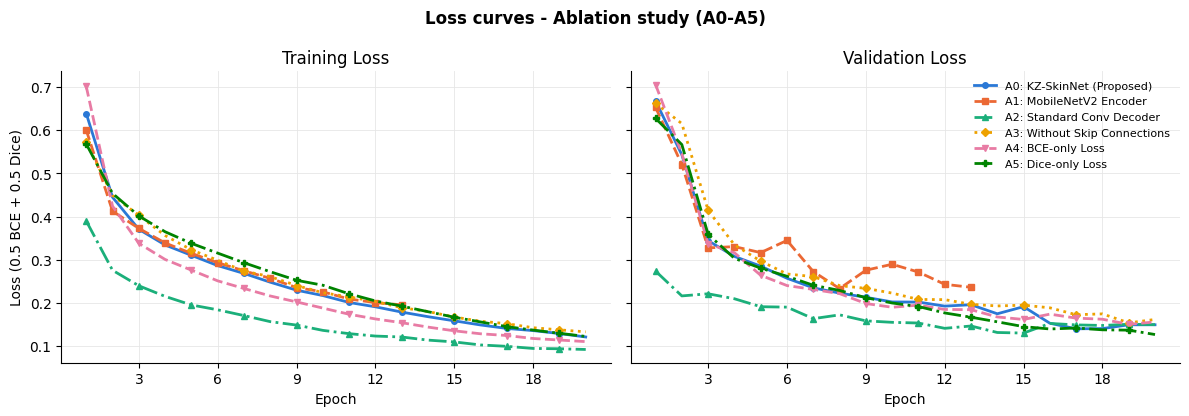

Saved: /kaggle/working/figures_final/ablation_loss_curves.png


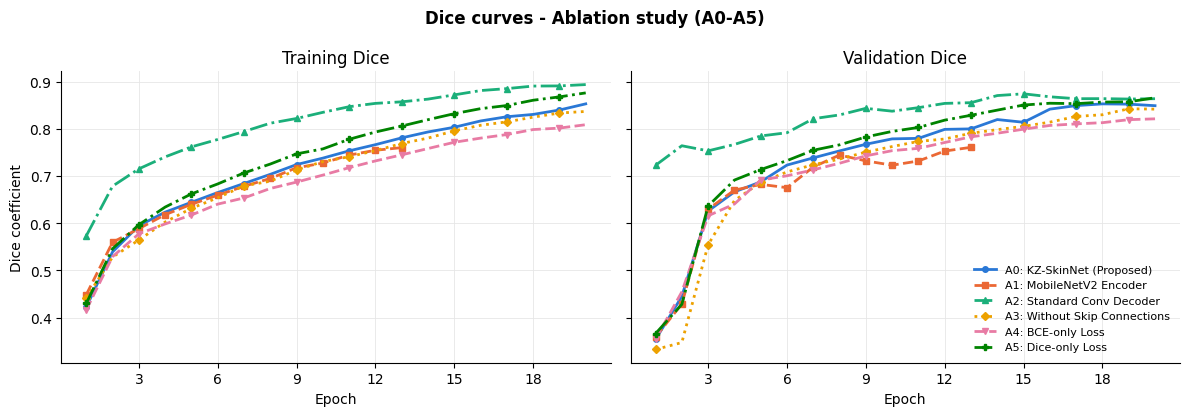

Saved: /kaggle/working/figures_final/ablation_dice_curves.png


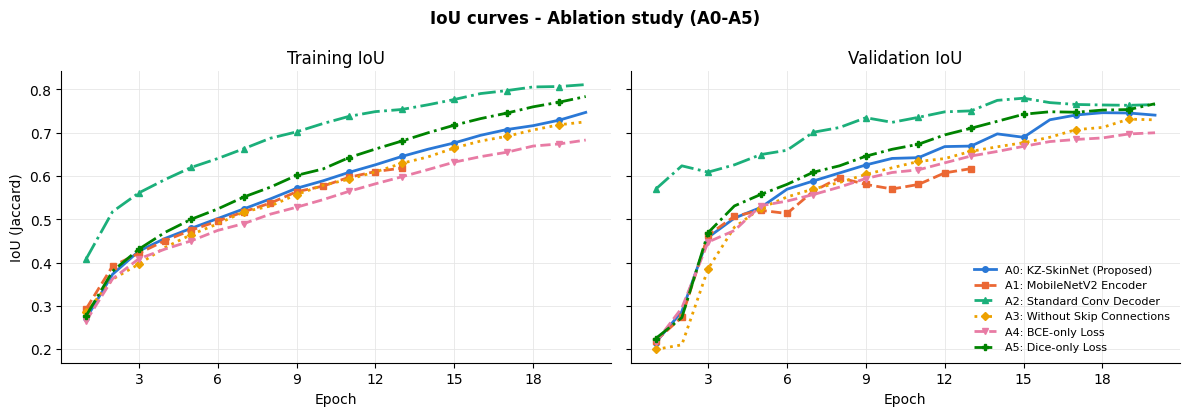

Saved: /kaggle/working/figures_final/ablation_iou_curves.png


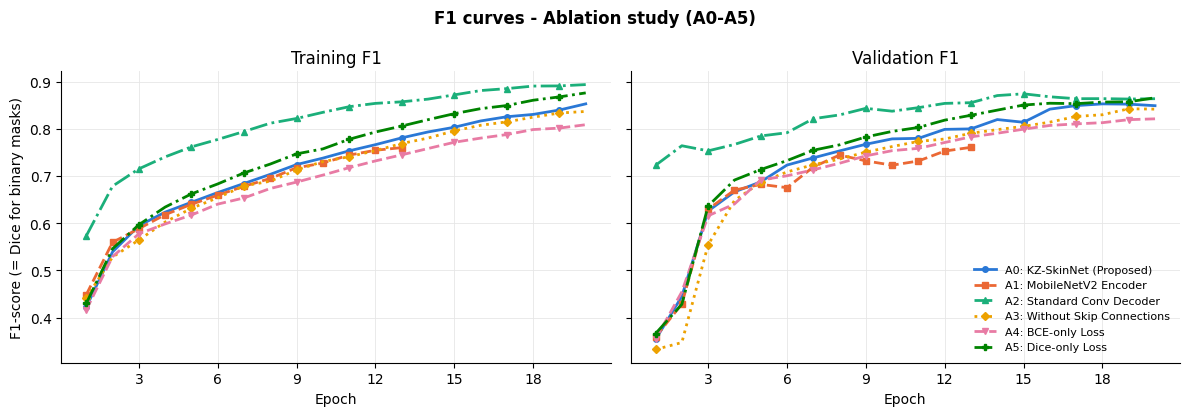

Saved: /kaggle/working/figures_final/ablation_f1_curves.png


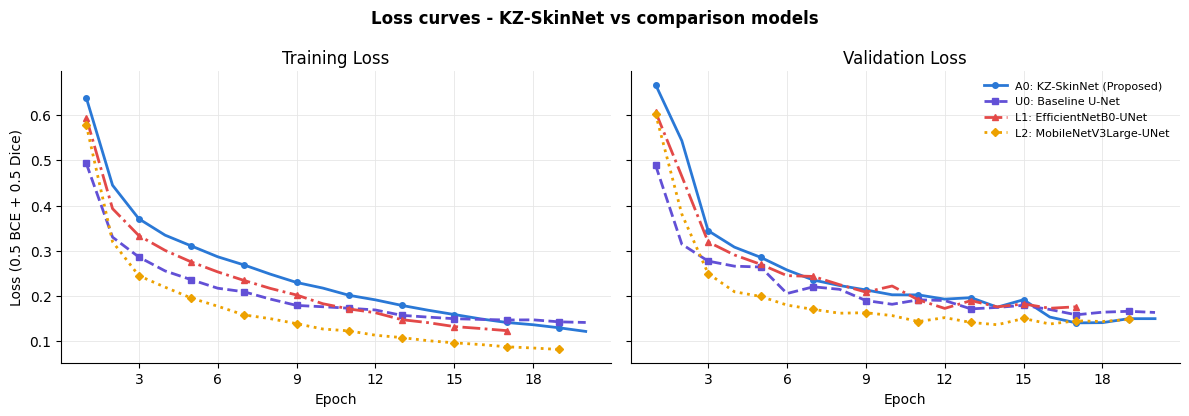

Saved: /kaggle/working/figures_final/comparison_loss_curves.png


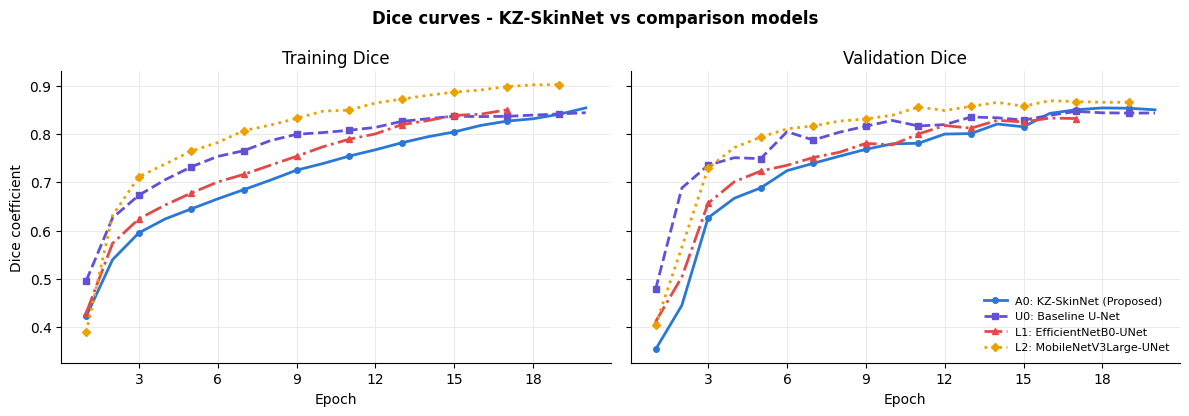

Saved: /kaggle/working/figures_final/comparison_dice_curves.png


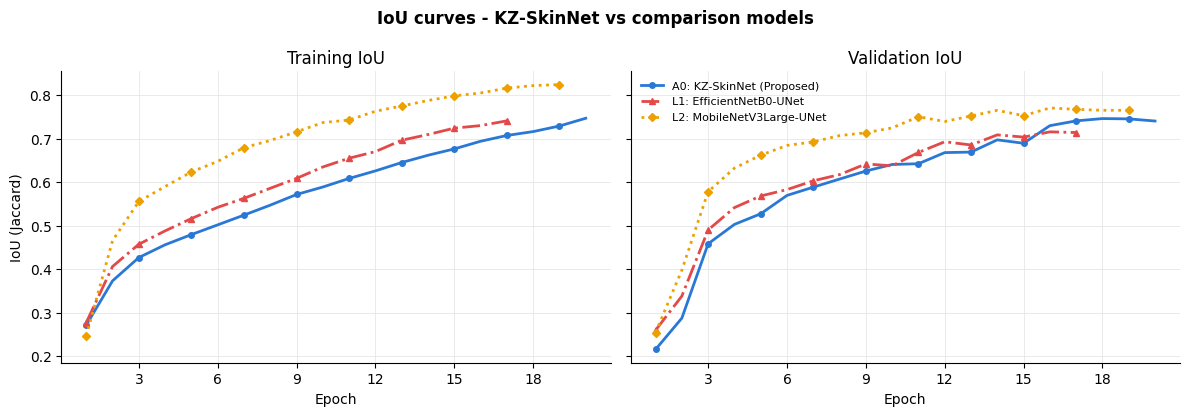

Saved: /kaggle/working/figures_final/comparison_iou_curves.png


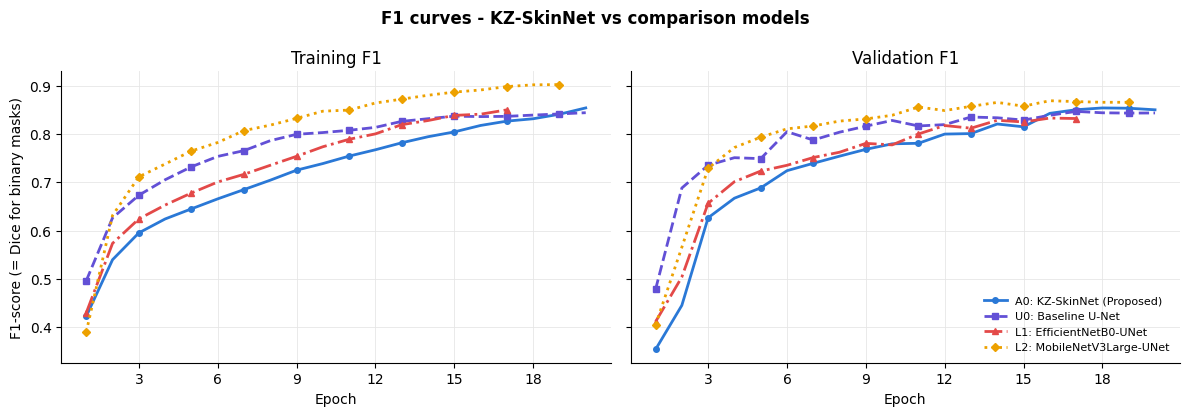

Saved: /kaggle/working/figures_final/comparison_f1_curves.png

Not logged during training (curve omitted): [('comparison', 'IoU', 'U0')]


In [ ]:
# ============================================================
# CELL C: TRAINING CURVES - Loss, Dice, IoU, F1 (training + validation)
# A0-A5 (ablation) and A0 vs U0 (re-trained v2), L1, L2 (comparison)
# Reads the *_history.csv files written during training (no re-training).
# Note: F1-score and Dice are the same quantity for binary masks (F1 = 2TP/(2TP+FP+FN) = Dice),
# so the F1 curve is the logged Dice curve shown under the F1 name.
# ============================================================
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

FIG_DIR = "/kaggle/working/figures_final"; os.makedirs(FIG_DIR, exist_ok=True)
NAMES = {"A0": "A0: KZ-SkinNet (Proposed)", "A1": "A1: MobileNetV2 Encoder", "A2": "A2: Standard Conv Decoder",
         "A3": "A3: Without Skip Connections", "A4": "A4: BCE-only Loss", "A5": "A5: Dice-only Loss",
         "U0": "U0: Baseline U-Net", "L1": "L1: EfficientNetB0-UNet", "L2": "L2: MobileNetV3Large-UNet"}
GROUPS = {"ablation": ["A0", "A1", "A2", "A3", "A4", "A5"], "comparison": ["A0", "U0", "L1", "L2"]}
STYLE = {"A0": ("#2a78d6", "-", "o"), "A1": ("#eb6834", "--", "s"), "A2": ("#1baf7a", "-.", "^"),
         "A3": ("#eda100", ":", "D"), "A4": ("#e87ba4", "--", "v"), "A5": ("#008300", "-.", "P"),
         "U0": ("#6250d6", "--", "s"), "L1": ("#e34948", "-.", "^"), "L2": ("#eda100", ":", "D")}
CURVES = {"Loss": ("loss", "val_loss", "Loss (0.5 BCE + 0.5 Dice)"),
          "Dice": ("dice_coefficient", "val_dice_coefficient", "Dice coefficient"),
          "IoU":  ("iou_score", "val_iou_score", "IoU (Jaccard)"),
          "F1":   ("dice_coefficient", "val_dice_coefficient", "F1-score (= Dice for binary masks)")}

def find_history(k):
    hits = []
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits += sorted(glob.glob(os.path.join(d, "**", f"{k}_history.csv"), recursive=True))
    if k == "U0":                                   # prefer the re-trained U0 (no time limit)
        v2 = [h for h in hits if "comparison_v2" in h]
        hits = v2 or hits
    return hits[0] if hits else None

H = {}
for k in NAMES:
    f = find_history(k)
    if f: H[k] = pd.read_csv(f); print(f"{k}: {len(H[k])} epochs  <- {f}")
    else: print(f"{k}: history not found")

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6})
missing = []
for group, keys in GROUPS.items():
    for metric, (tr, va, ylabel) in CURVES.items():
        ks = [k for k in keys if k in H]
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
        for ax, col, title in [(axes[0], tr, "Training"), (axes[1], va, "Validation")]:
            for k in ks:
                if col not in H[k]:
                    missing.append((group, metric, k)); continue
                c, ls, mk = STYLE[k]; ep = H[k]["epoch"] + 1
                ax.plot(ep, H[k][col], color=c, linestyle=ls, linewidth=2, marker=mk, markersize=4,
                        markevery=max(1, len(ep) // 8), label=NAMES[k])
            ax.set_title(f"{title} {metric}"); ax.set_xlabel("Epoch")
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        axes[0].set_ylabel(ylabel); axes[1].legend(loc="best", fontsize=8, frameon=False)
        fig.suptitle(f"{metric} curves - {'Ablation study (A0-A5)' if group == 'ablation' else 'KZ-SkinNet vs comparison models'}",
                     fontweight="bold")
        fig.tight_layout()
        out = os.path.join(FIG_DIR, f"{group}_{metric.lower()}_curves.png")
        fig.savefig(out, dpi=300, bbox_inches="tight"); plt.show(); print("Saved:", out)

if missing:
    print("\nNot logged during training (curve omitted):", sorted(set((g, m, k) for g, m, k in missing)))

## 7. Final results of all models + verification
**CELL S** loads the data once and defines the helpers used by the remaining sections.

In [ ]:
# ============================================================
# CELL S: COMMON SETUP for the reviewer experiments on KZ-SkinNet (A0)
# Loads ISIC 2018 (train/val/test) + PH2 once, defines all architectures,
# finds the saved checkpoints. Run this first, then any of the cells below.
# ============================================================
import os, glob, json, time, random, platform
import numpy as np, pandas as pd, cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score

SEED, IMG_SIZE, BATCH_SIZE, THRESHOLD = 42, 256, 16, 0.5
OUT = "/kaggle/working/reviewer_experiments"
os.makedirs(OUT, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE

R18 = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
PATHS = {
    "train":      (f"{R18}/train/images/ISIC2018_Task1-2_Training_Input",
                   f"{R18}/train/masks/ISIC2018_Task1_Training_GroundTruth"),
    "Validation": (f"{R18}/validation/images/ISIC2018_Task1-2_Validation_Input",
                   f"{R18}/validation/masks/ISIC2018_Task1_Validation_GroundTruth"),
    "Test":       (f"{R18}/test/images/ISIC2018_Task1-2_Test_Input",
                   f"{R18}/test/masks/ISIC2018_Task1_Test_GroundTruth"),
}

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError: pass
GPU_CC = tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0)) if gpus else (0, 0)
tf.keras.mixed_precision.set_global_policy("float32")       # inference / analysis in float32
print("TensorFlow", tf.__version__, "| GPUs:", len(gpus))

# ---------------- data (loaded once into RAM) ----------------
def create_dataframe(image_path, mask_path):
    masks = {m.replace("_segmentation.png", ""): m for m in os.listdir(mask_path) if m.lower().endswith(".png")}
    rows = [(os.path.join(image_path, f), os.path.join(mask_path, masks[f[:-4]]))
            for f in sorted(os.listdir(image_path)) if f.lower().endswith(".jpg") and f[:-4] in masks]
    return pd.DataFrame(rows, columns=["image", "mask"])

def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)

DFS, RAW = {}, {}
for name, (i_dir, m_dir) in PATHS.items():
    DFS[name] = create_dataframe(i_dir, m_dir); t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, DFS[name]["image"], DFS[name]["mask"]))
    RAW[name] = (np.stack([r[0] for r in res]), np.stack([r[1] for r in res]).astype(bool))
    print(f"{name}: {len(res)} images ({time.time()-t0:.0f}s)")

# PH2 (external, used by the bootstrap cell)
PH2_IMG, PH2_GT = "/kaggle/input/datasets/athina123/ph2dataset/trainx", "/kaggle/input/datasets/athina123/ph2dataset/trainy"
if os.path.isdir(PH2_IMG):
    import re
    key = lambda p: (re.findall(r"\d+", os.path.basename(p)) or [os.path.basename(p)])[-1]
    ims = {key(p): p for p in glob.glob(os.path.join(PH2_IMG, "**", "*"), recursive=True) if p.lower().endswith((".bmp", ".jpg", ".png"))}
    gts = {key(p): p for p in glob.glob(os.path.join(PH2_GT, "**", "*"), recursive=True) if p.lower().endswith((".bmp", ".jpg", ".png"))}
    ks = sorted(set(ims) & set(gts))
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, [ims[k] for k in ks], [gts[k] for k in ks]))
    RAW["PH2"] = (np.stack([r[0] for r in res]), np.stack([r[1] for r in res]).astype(bool))
    print(f"PH2: {len(res)} images")

def to_input(imgs_uint8):
    return imgs_uint8.astype(np.float32) / 127.5 - 1.0

# ---------------- architectures (identical to the training runs) ----------------
def conv_block(x, filters, name, separable=True):
    Conv = layers.SeparableConv2D if separable else layers.Conv2D
    x = Conv(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def features_by_resolution(bb):
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8): feats[s[1]] = l.output
        except Exception: pass
    return feats[128], feats[64], feats[32], feats[16], feats[8]

def encoder_features(inp, kind, weights=None):
    if kind == "v3small":
        return features_by_resolution(tf.keras.applications.MobileNetV3Small(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v3large":
        return features_by_resolution(tf.keras.applications.MobileNetV3Large(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v2":
        bb = tf.keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=1.0)
        g = lambda n: bb.get_layer(n).output
        return (g("block_1_expand_relu"), g("block_3_expand_relu"), g("block_6_expand_relu"),
                g("block_13_expand_relu"), g("out_relu"))
    if kind == "effb0":
        # weights="imagenet" is required so the graph contains EfficientNet's extra rescaling layer (as in training)
        x255 = layers.Lambda(lambda t: (t + 1.0) * 127.5, name="to_0_255")(inp)
        bb = tf.keras.applications.EfficientNetB0(input_tensor=x255, include_top=False, weights="imagenet")
        g = lambda n: bb.get_layer(n).output
        return (g("block2a_expand_activation"), g("block3a_expand_activation"),
                g("block4a_expand_activation"), g("block6a_expand_activation"), g("top_activation"))

def build_seg(encoder="v3small", separable=True, use_skip=True, weights=None):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    s1, s2, s3, s4, bridge = encoder_features(inp, encoder, weights)
    x = conv_block(bridge, 128, "bridge", separable)
    for skip, f, n in [(s4, 96, "dec4"), (s3, 64, "dec3"), (s2, 32, "dec2"), (s1, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        if use_skip:
            x = layers.Concatenate(name=n + "_cat")([x, skip])
        x = conv_block(x, f, n, separable)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x))

def unet_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{name}_c{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_r{i}")(x)
    return x

def build_unet(filters=(64, 128, 256, 512, 1024)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3)); skips, x = [], inp
    for i, f in enumerate(filters[:-1]):
        x = unet_block(x, f, f"enc{i+1}"); skips.append(x); x = layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = unet_block(x, filters[-1], "bottleneck")
    for i, (f, s) in enumerate(zip(reversed(filters[:-1]), reversed(skips))):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i+1}")(x)
        x = layers.Concatenate(name=f"cat{i+1}")([x, s]); x = unet_block(x, f, f"dec{i+1}")
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x), name="Vanilla_UNet")

MODELS = {   # id: (name, builder)
    "A0": ("KZ-SkinNet (Proposed)",        lambda: build_seg()),
    "A1": ("MobileNetV2 Encoder",          lambda: build_seg(encoder="v2")),
    "A2": ("Standard Conv Decoder",        lambda: build_seg(separable=False)),
    "A3": ("Without Skip Connections",     lambda: build_seg(use_skip=False)),
    "A4": ("BCE-only Loss",                lambda: build_seg()),
    "A5": ("Dice-only Loss",               lambda: build_seg()),
    "U0": ("Baseline U-Net (vanilla)",     lambda: build_unet()),
    "L1": ("EfficientNetB0-UNet",          lambda: build_seg(encoder="effb0")),
    "L2": ("MobileNetV3Large-UNet",        lambda: build_seg(encoder="v3large")),
}

def find_ckpt(key):
    pref = ["comparison_v2"] if key == "U0" else []          # use the re-trained U0 if it exists
    hits = []
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits += sorted(glob.glob(os.path.join(d, "**", f"{key}_best.weights.h5"), recursive=True))
    for p in pref:
        for h in hits:
            if p in h: return h
    return hits[0] if hits else None

def load_model(key):
    tf.keras.backend.clear_session()
    m = MODELS[key][1](); ck = find_ckpt(key)
    assert ck, f"checkpoint for {key} not found"
    m.load_weights(ck)
    return m, ck

def predict(model, imgs_uint8, bs=BATCH_SIZE):
    return model.predict(to_input(imgs_uint8), batch_size=bs, verbose=0)[..., 0]

def per_image_metrics(prob, gt, thr=THRESHOLD):
    p = prob >= thr
    tp = (gt & p).sum((1, 2)).astype(float); fp = (~gt & p).sum((1, 2)).astype(float)
    fn = (gt & ~p).sum((1, 2)).astype(float); tn = (~gt & ~p).sum((1, 2)).astype(float)
    e = 1e-12
    return pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "TN": tn,
                         "Dice": 2*tp/(2*tp+fp+fn+e), "IoU": tp/(tp+fp+fn+e),
                         "Precision": tp/(tp+fp+e), "Sensitivity": tp/(tp+fn+e), "Specificity": tn/(tn+fp+e)})

def pooled_from_counts(TP, FP, FN, TN):
    prec, rec = TP/(TP+FP), TP/(TP+FN)
    return {"Dice": 2*TP/(2*TP+FP+FN), "IoU": TP/(TP+FP+FN), "Accuracy": (TP+TN)/(TP+TN+FP+FN),
            "Precision": prec, "Sensitivity": rec, "Specificity": TN/(TN+FP)}

print("Checkpoints found:", {k: (find_ckpt(k) is not None) for k in MODELS})

TensorFlow 2.20.0 | GPUs: 2
train: 2594 images (212s)
Validation: 100 images (5s)
Test: 1000 images (47s)
PH2: 200 images
Checkpoints found: {'A0': True, 'A1': True, 'A2': True, 'A3': True, 'A4': True, 'A5': True, 'U0': True, 'L1': True, 'L2': True}


In [ ]:
# ============================================================
# CELL V (single cell): FINAL RESULTS TABLE + VERIFICATION for ALL models
# A0-A5 (ablation), U0 (re-trained, comparison_v2), L1, L2 - every model rebuilt from its best
# checkpoint and evaluated the same way on ISIC 2018 validation + test:
# pixel-level pooled metrics, threshold 0.5, AUC on all pixels.
# Verification: recomputed test Dice vs the value saved during training (|diff| < 0.1 -> OK).
# Part 1 re-defines the CELL S helpers (safe even if older cells overwrote them).
# Needs CELL S to have been run once (data in RAM).
# ============================================================
assert "RAW" in globals(), "Run CELL S once first (it loads the data)"
tf.keras.mixed_precision.set_global_policy("float32")

# ---------------- Part 1: helpers (same as CELL S) ----------------
def to_input(imgs_uint8):
    return imgs_uint8.astype(np.float32) / 127.5 - 1.0

def conv_block(x, filters, name, separable=True):
    Conv = layers.SeparableConv2D if separable else layers.Conv2D
    x = Conv(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def features_by_resolution(bb):
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8): feats[s[1]] = l.output
        except Exception: pass
    return feats[128], feats[64], feats[32], feats[16], feats[8]

def encoder_features(inp, kind, weights=None):
    if kind == "v3small":
        return features_by_resolution(tf.keras.applications.MobileNetV3Small(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v3large":
        return features_by_resolution(tf.keras.applications.MobileNetV3Large(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v2":
        bb = tf.keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=1.0)
        g = lambda n: bb.get_layer(n).output
        return (g("block_1_expand_relu"), g("block_3_expand_relu"), g("block_6_expand_relu"),
                g("block_13_expand_relu"), g("out_relu"))
    if kind == "effb0":
        # weights="imagenet" is required so the graph contains EfficientNet's extra rescaling layer (as in training)
        x255 = layers.Lambda(lambda t: (t + 1.0) * 127.5, name="to_0_255")(inp)
        bb = tf.keras.applications.EfficientNetB0(input_tensor=x255, include_top=False, weights="imagenet")
        g = lambda n: bb.get_layer(n).output
        return (g("block2a_expand_activation"), g("block3a_expand_activation"),
                g("block4a_expand_activation"), g("block6a_expand_activation"), g("top_activation"))

def build_seg(encoder="v3small", separable=True, use_skip=True, weights=None):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    s1, s2, s3, s4, bridge = encoder_features(inp, encoder, weights)
    x = conv_block(bridge, 128, "bridge", separable)
    for skip, f, n in [(s4, 96, "dec4"), (s3, 64, "dec3"), (s2, 32, "dec2"), (s1, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        if use_skip:
            x = layers.Concatenate(name=n + "_cat")([x, skip])
        x = conv_block(x, f, n, separable)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x))

def unet_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{name}_c{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_r{i}")(x)
    return x

def build_unet(filters=(64, 128, 256, 512, 1024)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3)); skips, x = [], inp
    for i, f in enumerate(filters[:-1]):
        x = unet_block(x, f, f"enc{i+1}"); skips.append(x); x = layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = unet_block(x, filters[-1], "bottleneck")
    for i, (f, s) in enumerate(zip(reversed(filters[:-1]), reversed(skips))):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i+1}")(x)
        x = layers.Concatenate(name=f"cat{i+1}")([x, s]); x = unet_block(x, f, f"dec{i+1}")
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x), name="Vanilla_UNet")

MODELS = {   # id: (name, builder)
    "A0": ("KZ-SkinNet (Proposed)",        lambda: build_seg()),
    "A1": ("MobileNetV2 Encoder",          lambda: build_seg(encoder="v2")),
    "A2": ("Standard Conv Decoder",        lambda: build_seg(separable=False)),
    "A3": ("Without Skip Connections",     lambda: build_seg(use_skip=False)),
    "A4": ("BCE-only Loss",                lambda: build_seg()),
    "A5": ("Dice-only Loss",               lambda: build_seg()),
    "U0": ("Baseline U-Net (vanilla)",     lambda: build_unet()),
    "L1": ("EfficientNetB0-UNet",          lambda: build_seg(encoder="effb0")),
    "L2": ("MobileNetV3Large-UNet",        lambda: build_seg(encoder="v3large")),
}

def find_ckpt(key):
    pref = ["comparison_v2"] if key == "U0" else []          # use the re-trained U0 if it exists
    hits = []
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits += sorted(glob.glob(os.path.join(d, "**", f"{key}_best.weights.h5"), recursive=True))
    for p in pref:
        for h in hits:
            if p in h: return h
    return hits[0] if hits else None

def load_model(key):
    tf.keras.backend.clear_session()
    m = MODELS[key][1](); ck = find_ckpt(key)
    assert ck, f"checkpoint for {key} not found"
    m.load_weights(ck)
    return m, ck

def predict(model, imgs_uint8, bs=BATCH_SIZE):
    return model.predict(to_input(imgs_uint8), batch_size=bs, verbose=0)[..., 0]

# ---------------- Part 2: evaluate all models ----------------
ALL = ["A0", "A1", "A2", "A3", "A4", "A5", "U0", "L1", "L2"]
VOUT = f"{OUT}/final_results"; os.makedirs(VOUT, exist_ok=True)

def saved_result(key):
    for d in ["/kaggle/working", "/kaggle/input"]:
        for h in sorted(glob.glob(os.path.join(d, "**", f"{key}_result.json"), recursive=True)):
            if key == "U0" and "comparison_v2" not in h:
                continue                                  # only the re-trained U0 counts
            return json.load(open(h)), h
    return {}, None

rows = []
for k in ALL:
    ck = find_ckpt(k)
    if ck is None:
        print(f"{k}: checkpoint not found - skipped"); continue
    m, _ = load_model(k)
    info, _ = saved_result(k)
    for s in ["Validation", "Test"]:
        imgs, gt = RAW[s]
        prob = predict(m, imgs); y = gt.reshape(-1); p = prob.reshape(-1) >= THRESHOLD
        TP = int(np.sum(y & p)); FP = int(np.sum(~y & p)); FN = int(np.sum(y & ~p)); TN = int(np.sum(~y & ~p))
        e = 1e-12
        prec, rec = TP / (TP + FP + e), TP / (TP + FN + e)
        rows.append({"Set": s, "ID": k, "Model": MODELS[k][0], "Params": m.count_params(), "Epochs": info.get("Epochs"),
                     "Accuracy": (TP + TN) / (TP + TN + FP + FN), "Precision": prec, "Recall": rec,
                     "Specificity": TN / (TN + FP + e), "F1-score": 2 * prec * rec / (prec + rec + e),
                     "Dice": 2 * TP / (2 * TP + FP + FN + e), "IoU": TP / (TP + FP + FN + e),
                     "AUC": roc_auc_score(y, prob.reshape(-1)), "TP": TP, "FP": FP, "FN": FN, "TN": TN,
                     "checkpoint": ck})
    print(f"{k}: evaluated  ({ck})")

full = pd.DataFrame(rows)
METRICS = ["Accuracy", "Precision", "Recall", "Specificity", "F1-score", "Dice", "IoU", "AUC"]
table = full[["Set", "ID", "Model", "Params", "Epochs"] + METRICS].copy()
table[METRICS] = (table[METRICS] * 100).round(2)
a0 = table[table["ID"] == "A0"].set_index("Set")["Dice"]
table["Δ Dice vs A0"] = (table["Dice"] - table["Set"].map(a0)).round(2)
table["Params"] = table["Params"].map(lambda p: f"{int(p):,}")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
for s in ["Validation", "Test"]:
    n = len(RAW[s][1])
    print(f"\n================ FINAL RESULTS - ISIC 2018 {s} (n={n}), pixel-level pooled metrics (%) ================")
    print(table[table["Set"] == s].drop(columns="Set").to_string(index=False))

# ---------------- verification against the values saved at training time ----------------
chk = []
for k in full["ID"].unique():
    info, src = saved_result(k)
    saved = info.get("Dice", info.get("test_Dice"))
    if saved is None and k == "U0":                      # re-trained U0: value from the fix-cell table
        csvs = glob.glob("/kaggle/working/**/comparison_A0_U0_L1_L2_val_test_v2.csv", recursive=True)
        if csvs:
            t2 = pd.read_csv(csvs[0]); row = t2[(t2.ID == "U0") & (t2.Set == "Test")]
            if len(row): saved = float(row["Dice"].iloc[0]) / 100
    now = float(full[(full.ID == k) & (full.Set == "Test")]["Dice"].iloc[0])
    if saved is None:
        chk.append({"ID": k, "Saved test Dice": "not stored", "Recomputed test Dice": round(100 * now, 2),
                    "Difference": "-", "Status": "no reference (OK)"})
    else:
        d = 100 * (now - saved)
        chk.append({"ID": k, "Saved test Dice": round(100 * saved, 2), "Recomputed test Dice": round(100 * now, 2),
                    "Difference": round(d, 2), "Status": "OK" if abs(d) < 0.1 else "CHECK - mismatch"})
print("\n================ VERIFICATION: recomputed vs saved test Dice ================")
print(pd.DataFrame(chk).to_string(index=False))

print("\nPixel-level confusion counts")
print(full[["Set", "ID", "TP", "FP", "FN", "TN"]].to_string(index=False))
table.to_csv(f"{VOUT}/final_results_all_models_val_test.csv", index=False)
full.drop(columns="checkpoint").to_csv(f"{VOUT}/final_results_all_models_raw.csv", index=False)
pd.DataFrame(chk).to_csv(f"{VOUT}/verification.csv", index=False)
print("Saved to", VOUT)

A0: evaluated  (/kaggle/working/ablation/A0_best.weights.h5)


2026-11-22 06:48:48.826350: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:48:48.977899: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:48:49.114770: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:48:49.913965: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:48:50.060453: E external/local_xla/xla/stream_

A1: evaluated  (/kaggle/working/ablation/A1_best.weights.h5)
A2: evaluated  (/kaggle/working/ablation/A2_best.weights.h5)
A3: evaluated  (/kaggle/working/ablation/A3_best.weights.h5)
A4: evaluated  (/kaggle/working/ablation/A4_best.weights.h5)
A5: evaluated  (/kaggle/working/ablation/A5_best.weights.h5)


2026-11-22 06:53:07.634402: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:53:07.871851: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:53:09.031629: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:53:09.358231: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:53:19.719578: E external/local_xla/xla/stream_

U0: evaluated  (/kaggle/working/comparison_v2/U0_best.weights.h5)


2026-11-22 06:54:29.183676: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:54:29.319659: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:54:29.644409: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:54:29.786257: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:54:30.571218: E external/local_xla/xla/stream_

L1: evaluated  (/kaggle/working/comparison/L1_best.weights.h5)


2026-11-22 06:55:34.666694: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:55:34.802481: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:55:35.050074: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:55:35.186777: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


L2: evaluated  (/kaggle/working/comparison/L2_best.weights.h5)

================ FINAL RESULTS - ISIC 2018 Validation (n=100), pixel-level pooled metrics (%) ================
ID                    Model     Params  Epochs  Accuracy  Precision  Recall  Specificity  F1-score  Dice   IoU   AUC  Δ Dice vs A0
A0    KZ-SkinNet (Proposed)  1,083,865      20     95.31      89.05   94.10        95.76     91.51 91.51 84.34 99.04          0.00
A1      MobileNetV2 Encoder  2,541,377      13     93.71      87.06   89.90        95.10     88.46 88.46 79.31 97.92         -3.05
A2    Standard Conv Decoder  2,120,129      20     94.63      87.31   93.60        95.01     90.35 90.35 82.39 98.91         -1.16
A3 Without Skip Connections  1,043,265      20     94.64      88.07   92.57        95.40     90.27 90.27 82.26 98.53         -1.24
A4            BCE-only Loss  1,083,865      20     94.80      87.12   94.62        94.87     90.71 90.71 83.00 99.08         -0.80
A5           Dice-only Loss  1,083,865 

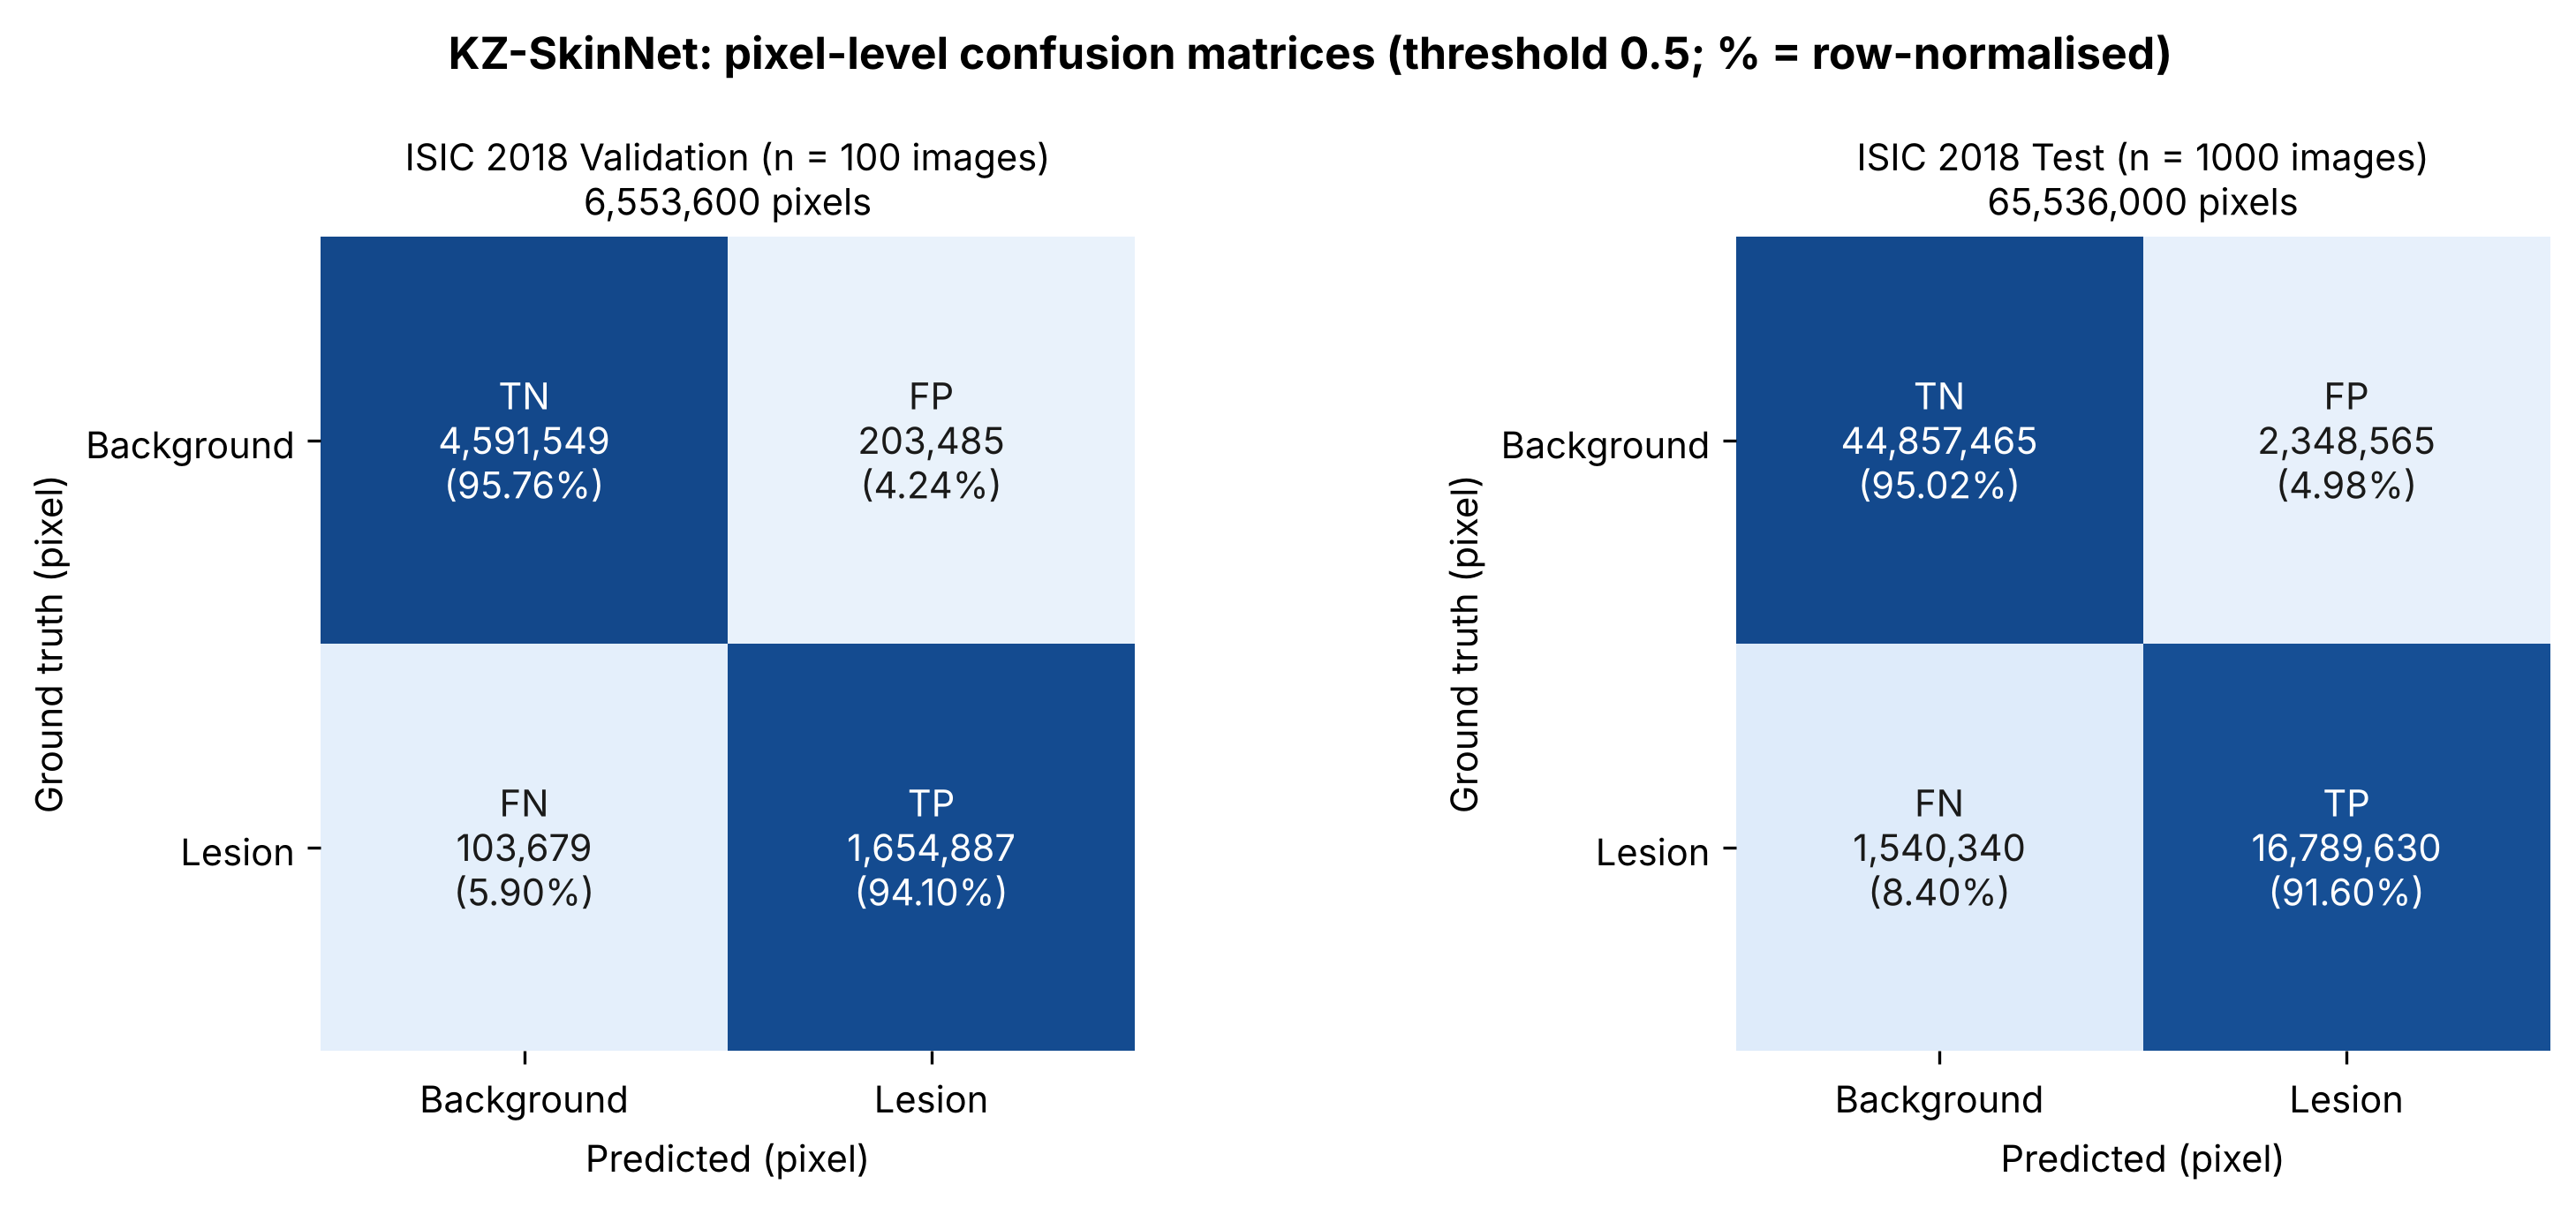

In [ ]:
# ============================================================
# PIXEL-LEVEL CONFUSION MATRICES of KZ-SkinNet (A0) - replaces the former image-level Figure 7
# counts taken from CELL V (final_results_all_models_raw.csv)
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
raw = pd.read_csv(f"{OUT}/final_results/final_results_all_models_raw.csv")
a0 = raw[raw.ID == "A0"].set_index("Set")
sets = {f"ISIC 2018 {s} (n = {n} images)": tuple(int(a0.loc[s, c]) for c in ["TP", "FP", "FN", "TN"])
        for s, n in [("Validation", 100), ("Test", 1000)]}
cmap = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#9ec5f4", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (title, (TP, FP, FN, TN)) in zip(axes, sets.items()):
    cm = np.array([[TN, FP], [FN, TP]], float); rowpct = cm / cm.sum(1, keepdims=True) * 100
    ax.imshow(rowpct, cmap=cmap, vmin=0, vmax=100)
    lab = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{lab[i][j]}\n{int(cm[i, j]):,}\n({rowpct[i, j]:.2f}%)", ha="center", va="center",
                    color="white" if rowpct[i, j] > 55 else "#1a1a19", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Background", "Lesion"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Background", "Lesion"])
    ax.set_xlabel("Predicted (pixel)"); ax.set_ylabel("Ground truth (pixel)")
    ax.set_title(f"{title}\n{int(cm.sum()):,} pixels", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("KZ-SkinNet: pixel-level confusion matrices (threshold 0.5; % = row-normalised)", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/KZ-SkinNet_pixel_confusion_matrix.png", dpi=300, bbox_inches="tight"); plt.show()


## 8. Robustness: three independent runs + paired Wilcoxon tests, bootstrap 95% CI
Seed 42 = the ablation run of A0; seeds 123 and 2024 re-trained with the identical protocol.

In [ ]:
# ============================================================
# CELL R (single cell): 3 INDEPENDENT RUNS + WILCOXON SIGNED-RANK TESTS (R3.10, R4.12)
#  (a) KZ-SkinNet (A0) with 3 seeds (42 = existing ablation run, + 123 and 2024 trained here,
#      identical protocol) -> mean ± SD over the 3 runs
#  (b) per-image test Dice of A0 (seed 42) vs every other model: paired Wilcoxon signed-rank test,
#      Holm-Bonferroni correction, matched-pairs rank-biserial effect size
# Part 1 re-defines the CELL S helpers (safe even if older cells overwrote them).
# Needs CELL S to have been run once (data in RAM). Trains 2 models (~6-12 min each on a T4).
# Seeds are trained with XLA switched off (avoids the fp16/fp32 'mixed precision is disallowed' error);
# if mixed precision still fails, the seed is retrained automatically in float32.
# ============================================================
assert "RAW" in globals(), "Run CELL S once first (it loads the data)"
tf.keras.mixed_precision.set_global_policy("float32")
gpus = tf.config.list_physical_devices("GPU")
GPU_CC = tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0)) if gpus else (0, 0)

# ---------------- Part 1: helpers (same as CELL S) ----------------
def to_input(imgs_uint8):
    return imgs_uint8.astype(np.float32) / 127.5 - 1.0

def conv_block(x, filters, name, separable=True):
    Conv = layers.SeparableConv2D if separable else layers.Conv2D
    x = Conv(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def features_by_resolution(bb):
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8): feats[s[1]] = l.output
        except Exception: pass
    return feats[128], feats[64], feats[32], feats[16], feats[8]

def encoder_features(inp, kind, weights=None):
    if kind == "v3small":
        return features_by_resolution(tf.keras.applications.MobileNetV3Small(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v3large":
        return features_by_resolution(tf.keras.applications.MobileNetV3Large(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v2":
        bb = tf.keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=1.0)
        g = lambda n: bb.get_layer(n).output
        return (g("block_1_expand_relu"), g("block_3_expand_relu"), g("block_6_expand_relu"),
                g("block_13_expand_relu"), g("out_relu"))
    if kind == "effb0":
        # weights="imagenet" is required so the graph contains EfficientNet's extra rescaling layer (as in training)
        x255 = layers.Lambda(lambda t: (t + 1.0) * 127.5, name="to_0_255")(inp)
        bb = tf.keras.applications.EfficientNetB0(input_tensor=x255, include_top=False, weights="imagenet")
        g = lambda n: bb.get_layer(n).output
        return (g("block2a_expand_activation"), g("block3a_expand_activation"),
                g("block4a_expand_activation"), g("block6a_expand_activation"), g("top_activation"))

def build_seg(encoder="v3small", separable=True, use_skip=True, weights=None):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    s1, s2, s3, s4, bridge = encoder_features(inp, encoder, weights)
    x = conv_block(bridge, 128, "bridge", separable)
    for skip, f, n in [(s4, 96, "dec4"), (s3, 64, "dec3"), (s2, 32, "dec2"), (s1, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        if use_skip:
            x = layers.Concatenate(name=n + "_cat")([x, skip])
        x = conv_block(x, f, n, separable)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x))

def unet_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{name}_c{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_r{i}")(x)
    return x

def build_unet(filters=(64, 128, 256, 512, 1024)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3)); skips, x = [], inp
    for i, f in enumerate(filters[:-1]):
        x = unet_block(x, f, f"enc{i+1}"); skips.append(x); x = layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = unet_block(x, filters[-1], "bottleneck")
    for i, (f, s) in enumerate(zip(reversed(filters[:-1]), reversed(skips))):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i+1}")(x)
        x = layers.Concatenate(name=f"cat{i+1}")([x, s]); x = unet_block(x, f, f"dec{i+1}")
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x), name="Vanilla_UNet")

MODELS = {   # id: (name, builder)
    "A0": ("KZ-SkinNet (Proposed)",        lambda: build_seg()),
    "A1": ("MobileNetV2 Encoder",          lambda: build_seg(encoder="v2")),
    "A2": ("Standard Conv Decoder",        lambda: build_seg(separable=False)),
    "A3": ("Without Skip Connections",     lambda: build_seg(use_skip=False)),
    "A4": ("BCE-only Loss",                lambda: build_seg()),
    "A5": ("Dice-only Loss",               lambda: build_seg()),
    "U0": ("Baseline U-Net (vanilla)",     lambda: build_unet()),
    "L1": ("EfficientNetB0-UNet",          lambda: build_seg(encoder="effb0")),
    "L2": ("MobileNetV3Large-UNet",        lambda: build_seg(encoder="v3large")),
}

def find_ckpt(key):
    pref = ["comparison_v2"] if key == "U0" else []          # use the re-trained U0 if it exists
    hits = []
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits += sorted(glob.glob(os.path.join(d, "**", f"{key}_best.weights.h5"), recursive=True))
    for p in pref:
        for h in hits:
            if p in h: return h
    return hits[0] if hits else None

def load_model(key):
    tf.keras.backend.clear_session()
    m = MODELS[key][1](); ck = find_ckpt(key)
    assert ck, f"checkpoint for {key} not found"
    m.load_weights(ck)
    return m, ck

def predict(model, imgs_uint8, bs=BATCH_SIZE):
    return model.predict(to_input(imgs_uint8), batch_size=bs, verbose=0)[..., 0]

def per_image_metrics(prob, gt, thr=THRESHOLD):
    p = prob >= thr
    tp = (gt & p).sum((1, 2)).astype(float); fp = (~gt & p).sum((1, 2)).astype(float)
    fn = (gt & ~p).sum((1, 2)).astype(float); tn = (~gt & ~p).sum((1, 2)).astype(float)
    e = 1e-12
    return pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "TN": tn,
                         "Dice": 2*tp/(2*tp+fp+fn+e), "IoU": tp/(tp+fp+fn+e),
                         "Precision": tp/(tp+fp+e), "Sensitivity": tp/(tp+fn+e), "Specificity": tn/(tn+fp+e)})

def pooled_from_counts(TP, FP, FN, TN):
    prec, rec = TP/(TP+FP), TP/(TP+FN)
    return {"Dice": 2*TP/(2*TP+FP+FN), "IoU": TP/(TP+FP+FN), "Accuracy": (TP+TN)/(TP+TN+FP+FN),
            "Precision": prec, "Sensitivity": rec, "Specificity": TN/(TN+FP)}

# ---------------- Part 2: seeds + Wilcoxon ----------------
from scipy.stats import wilcoxon
EPOCHS, SEEDS = 20, [42, 123, 2024]
SEED_DIR = f"{OUT}/seeds"; os.makedirs(SEED_DIR, exist_ok=True)

# ---------- training pipeline (identical to the ablation run) ----------
def augment(x, y):
    x = tf.cast(x, tf.float32) / 255.0; y = tf.cast(y, tf.float32)
    xy = tf.concat([x, y], -1)
    xy = tf.image.random_flip_left_right(xy); xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x, y = xy[..., :3], xy[..., 3:]
    x = tf.image.random_brightness(x, 0.15); x = tf.image.random_contrast(x, 0.85, 1.15)
    x = tf.image.random_saturation(x, 0.85, 1.15); x = tf.image.random_hue(x, 0.03)
    return tf.clip_by_value(x, 0.0, 1.0) * 2.0 - 1.0, y

def make_ds(X, Y, training, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, Y[..., None].astype(np.uint8)))
    if training:
        ds = ds.shuffle(len(X), seed=seed, reshuffle_each_iteration=True).map(augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 127.5 - 1.0, tf.cast(y, tf.float32)), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

def dice_coefficient(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1]); y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (2.0 * inter + 1e-6) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + 1e-6)
_bce = tf.keras.losses.BinaryCrossentropy()
def bce_dice_loss(y_true, y_pred):
    return 0.5 * _bce(y_true, tf.cast(y_pred, tf.float32)) + 0.5 * (1.0 - dice_coefficient(y_true, y_pred))

def train_seed(seed):
    ckpt = f"{SEED_DIR}/A0_seed{seed}_best.weights.h5"
    if os.path.exists(ckpt):
        print(f"seed {seed}: already trained"); return ckpt

    def _run(policy):
        print(f"\n########## training KZ-SkinNet (A0) with seed {seed}  [{policy}, XLA off]")
        tf.keras.backend.clear_session()
        tf.keras.mixed_precision.set_global_policy(policy)
        random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
        m = build_seg(weights="imagenet")
        m.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=bce_dice_loss,
                  metrics=[dice_coefficient], jit_compile=False)          # XLA off -> no fp16/fp32 clash
        t0 = time.time()
        m.fit(make_ds(*RAW["train"], True, seed), validation_data=make_ds(*RAW["Validation"], False, seed).cache(),
              epochs=EPOCHS, verbose=2, callbacks=[
                  tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True),
                  tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
                  tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, verbose=1),
                  tf.keras.callbacks.CSVLogger(f"{SEED_DIR}/A0_seed{seed}_history.csv")])
        print(f"seed {seed}: {(time.time()-t0)/60:.1f} min  ({policy})")

    try:
        _run("mixed_float16" if GPU_CC[0] >= 7 else "float32")   # same precision as the seed-42 run
    except (tf.errors.InternalError, tf.errors.InvalidArgumentError) as e:
        print(f"   mixed precision failed ({type(e).__name__}) -> retrying seed {seed} in float32")
        if os.path.exists(ckpt): os.remove(ckpt)
        _run("float32")
    finally:
        tf.keras.mixed_precision.set_global_policy("float32")
    return ckpt

# ---------- (a) 3 runs ----------
run_rows = []
for seed in SEEDS:
    ck = find_ckpt("A0") if seed == 42 else train_seed(seed)
    tf.keras.backend.clear_session(); tf.keras.mixed_precision.set_global_policy("float32")
    m = build_seg(); m.load_weights(ck)
    for s in ["Validation", "Test"]:
        pi = per_image_metrics(predict(m, RAW[s][0]), RAW[s][1])
        r = pooled_from_counts(pi.TP.sum(), pi.FP.sum(), pi.FN.sum(), pi.TN.sum())
        r.update(Seed=seed, Set=s, **{"Image-wise Dice": pi.Dice.mean()}); run_rows.append(r)
runs = pd.DataFrame(run_rows)
M = ["Dice", "IoU", "Accuracy", "Precision", "Sensitivity", "Specificity", "Image-wise Dice"]
print("\nKZ-SkinNet (A0): individual runs (%)")
show = runs.copy(); show[M] = (show[M] * 100).round(2); print(show[["Set", "Seed"] + M].to_string(index=False))
agg = runs.groupby("Set")[M].agg(["mean", "std"]) * 100
summary = pd.DataFrame({c: agg[c]["mean"].round(2).astype(str) + " ± " + agg[c]["std"].round(2).astype(str) for c in M})
print(f"\nKZ-SkinNet (A0): mean ± SD over {len(SEEDS)} independent runs (%)")
print(summary.to_string())
runs.to_csv(f"{SEED_DIR}/A0_three_runs.csv", index=False); summary.to_csv(f"{SEED_DIR}/A0_three_runs_mean_sd.csv")

# ---------- (b) paired Wilcoxon on per-image test Dice ----------
tf.keras.mixed_precision.set_global_policy("float32")
m0, _ = load_model("A0")
d0 = per_image_metrics(predict(m0, RAW["Test"][0]), RAW["Test"][1]).Dice.to_numpy()
tests = []
for k in ["A1", "A2", "A3", "A4", "A5", "U0", "L1", "L2"]:
    if find_ckpt(k) is None:
        print(k, "checkpoint not found - skipped"); continue
    mk, _ = load_model(k)
    dk = per_image_metrics(predict(mk, RAW["Test"][0]), RAW["Test"][1]).Dice.to_numpy()
    diff = d0 - dk
    nz = diff[diff != 0]
    ranks = pd.Series(np.abs(nz)).rank().to_numpy()
    rb = (ranks[nz > 0].sum() - ranks[nz < 0].sum()) / ranks.sum()       # rank-biserial effect size
    stat, p = wilcoxon(d0, dk, zero_method="wilcox", alternative="two-sided")
    tests.append({"Comparison": f"A0 vs {k} ({MODELS[k][0]})", "Mean Dice A0": d0.mean(), f"Mean Dice other": dk.mean(),
                  "Median diff (A0-other)": np.median(diff), "A0 better on (images)": int((diff > 0).sum()),
                  "W": stat, "p": p, "Effect size r": rb})
tt = pd.DataFrame(tests).sort_values("p").reset_index(drop=True)
m_ = len(tt); tt["p (Holm)"] = np.minimum(1, np.maximum.accumulate((m_ - np.arange(m_)) * tt["p"]))
tt["Significant (α=0.05)"] = np.where(tt["p (Holm)"] < 0.05, "yes", "no")
for c in ["Mean Dice A0", "Mean Dice other", "Median diff (A0-other)"]:
    tt[c] = (tt[c] * 100).round(2)
tt["p"] = tt["p"].map(lambda v: f"{v:.2e}"); tt["p (Holm)"] = tt["p (Holm)"].map(lambda v: f"{v:.2e}")
tt["Effect size r"] = tt["Effect size r"].round(3)
print(f"\nPaired Wilcoxon signed-rank test on per-image Dice, ISIC 2018 test set (n = {len(d0)} images)")
print(tt.to_string(index=False))
tt.to_csv(f"{OUT}/wilcoxon_A0_vs_all.csv", index=False)
print("Saved to", OUT)

I0000 00:00:1795329048.277949   12335 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795329048.282355   12335 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1795329068.648864   12423 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


seed 123: already trained

########## training KZ-SkinNet (A0) with seed 2024  [mixed_float16, XLA off]


/usr/local/lib/python3.12/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Epoch 1/20
163/163 - 200s - 1s/step - dice_coefficient: 0.4179 - loss: 0.7025 - val_dice_coefficient: 0.3599 - val_loss: 0.6563 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 - 19s - 118ms/step - dice_coefficient: 0.5142 - loss: 0.4897 - val_dice_coefficient: 0.4726 - val_loss: 0.5350 - learning_rate: 1.0000e-04
Epoch 3/20
163/163 - 19s - 119ms/step - dice_coefficient: 0.5450 - loss: 0.4386 - val_dice_coefficient: 0.5820 - val_loss: 0.4018 - learning_rate: 1.0000e-04
Epoch 4/20
163/163 - 19s - 117ms/step - dice_coefficient: 0.5648 - loss: 0.4104 - val_dice_coefficient: 0.6231 - val_loss: 0.3627 - learning_rate: 1.0000e-04
Epoch 5/20
163/163 - 19s - 117ms/step - dice_coefficient: 0.5855 - loss: 0.3828 - val_dice_coefficient: 0.6421 - val_loss: 0.3365 - learning_rate: 1.0000e-04
Epoch 6/20
163/163 - 19s - 118ms/step - dice_coefficient: 0.5980 - loss: 0.3639 - val_dice_coefficient: 0.6565 - val_loss: 0.3291 - learning_rate: 1.0000e-04
Epoch 7/20
163/163 - 19s - 117ms/step - dice_coefficie

2026-11-22 06:42:34.542787: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:42:34.687706: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:42:34.824504: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:42:35.639192: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-22 06:42:35.784607: E external/local_xla/xla/stream_


Paired Wilcoxon signed-rank test on per-image Dice, ISIC 2018 test set (n = 1000 images)
                         Comparison  Mean Dice A0  Mean Dice other  Median diff (A0-other)  A0 better on (images)        W        p  Effect size r p (Holm) Significant (α=0.05)
          A0 vs A5 (Dice-only Loss)          89.4            86.21                    2.59                    788  78262.0 4.60e-79          0.687 3.68e-78                  yes
           A0 vs A4 (BCE-only Loss)          89.4            87.88                    0.99                    714 124968.0 8.41e-43          0.501 5.89e-42                  yes
     A0 vs A1 (MobileNetV2 Encoder)          89.4            88.02                    1.32                    699 139954.0 1.46e-33          0.441 8.77e-33                  yes
A0 vs A3 (Without Skip Connections)          89.4            88.32                    0.90                    692 145674.0 2.43e-30          0.418 1.22e-29                  yes
   A0 vs L2 (MobileNetV3L

In [ ]:
# ============================================================
# CELL B: IMAGE-WISE METRICS + BOOTSTRAP 95% CI (R3.10, R4.12) - KZ-SkinNet (A0)
# (run after CELL S / S2)
# 10,000 bootstrap resamples of IMAGES ->
#   image-wise mean Dice / IoU / Precision / Sensitivity / Specificity, and pooled Dice / IoU
# ============================================================
N_BOOT = 10000
tf.keras.mixed_precision.set_global_policy("float32")
model, ck = load_model("A0")
print("A0 checkpoint:", ck)
rng = np.random.default_rng(SEED)
rows, per_image_all = [], {}
for s in [k for k in ["Validation", "Test", "PH2"] if k in RAW]:
    imgs, gt = RAW[s]
    m = per_image_metrics(predict(model, imgs), gt); per_image_all[s] = m
    n = len(m); idx = rng.integers(0, n, size=(N_BOOT, n))
    for col in ["Dice", "IoU", "Precision", "Sensitivity", "Specificity"]:
        v = m[col].to_numpy(); boot = v[idx].mean(1)
        rows.append({"Dataset": s, "n": n, "Metric": f"{col} (image-wise mean)", "Value": v.mean(),
                     "SD": v.std(ddof=1), "95% CI low": np.percentile(boot, 2.5), "95% CI high": np.percentile(boot, 97.5)})
    TP, FP, FN = (m[c].to_numpy()[idx].sum(1) for c in ["TP", "FP", "FN"])
    for col, b, full in [("Dice (pooled)", 2*TP/(2*TP+FP+FN), 2*m.TP.sum()/(2*m.TP.sum()+m.FP.sum()+m.FN.sum())),
                         ("IoU (pooled)", TP/(TP+FP+FN), m.TP.sum()/(m.TP.sum()+m.FP.sum()+m.FN.sum()))]:
        rows.append({"Dataset": s, "n": n, "Metric": col, "Value": full, "SD": np.nan,
                     "95% CI low": np.percentile(b, 2.5), "95% CI high": np.percentile(b, 97.5)})
ci = pd.DataFrame(rows)
show = ci.copy()
for c in ["Value", "SD", "95% CI low", "95% CI high"]:
    show[c] = (show[c] * 100).round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 50)
print(f"KZ-SkinNet (A0): bootstrap 95% CI, {N_BOOT} resamples of images, threshold {THRESHOLD} (values in %)")
print(show.to_string(index=False))
ci.to_csv(f"{OUT}/A0_bootstrap_ci.csv", index=False)
for s, m in per_image_all.items():
    m.to_csv(f"{OUT}/A0_per_image_metrics_{s}.csv", index=False)
print("\nImage-wise Dice on the test set: min %.3f | median %.3f | max %.3f | images with Dice < 0.5: %d"
      % (per_image_all["Test"].Dice.min(), per_image_all["Test"].Dice.median(), per_image_all["Test"].Dice.max(),
         int((per_image_all["Test"].Dice < 0.5).sum())))
print("Saved to", OUT)

A0 checkpoint: /kaggle/working/ablation/A0_best.weights.h5
KZ-SkinNet (A0): bootstrap 95% CI, 10000 resamples of images, threshold 0.5 (values in %)
   Dataset    n                        Metric  Value    SD  95% CI low  95% CI high
Validation  100        Dice (image-wise mean)  90.60  9.06       88.79        92.23
Validation  100         IoU (image-wise mean)  83.84 12.74       81.36        86.20
Validation  100   Precision (image-wise mean)  88.43 12.34       85.89        90.73
Validation  100 Sensitivity (image-wise mean)  94.64  9.59       92.63        96.37
Validation  100 Specificity (image-wise mean)  94.77  7.94       93.09        96.18
Validation  100                 Dice (pooled)  91.51   NaN       89.82        93.02
Validation  100                  IoU (pooled)  84.34   NaN       81.52        86.95
      Test 1000        Dice (image-wise mean)  89.40 11.69       88.64        90.11
      Test 1000         IoU (image-wise mean)  82.39 14.93       81.42        83.30
      Test 

## 9. Threshold selection (validation set only)

Validation-optimal threshold: 0.65


,Threshold,Val Dice,Val IoU,Test Dice,Test IoU
0,0.50 (used in paper),91.51,84.34,89.62,81.19
1,0.65 (best on validation),91.78,84.80,89.97,81.77


Thresholds within 0.5 Dice-points of the validation optimum: 0.50 - 0.80


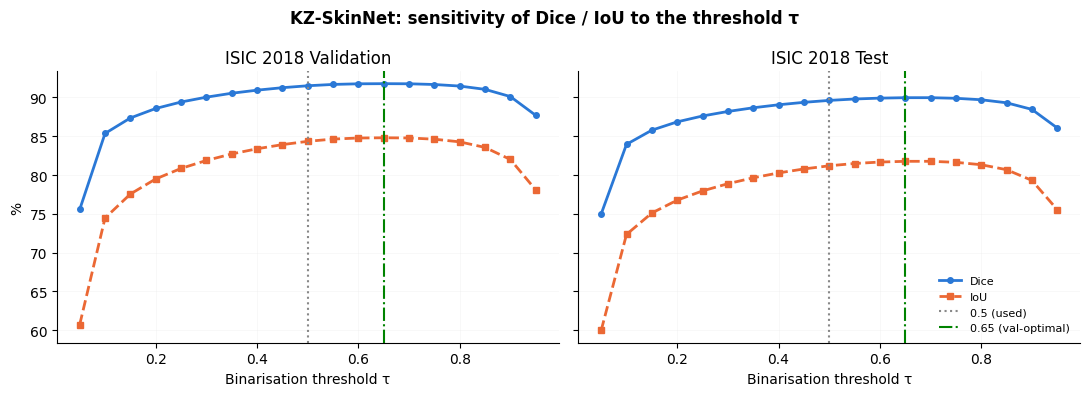

Saved: /kaggle/working/reviewer_experiments/threshold_sweep.png


In [ ]:
# ============================================================
# CELL T: THRESHOLD SELECTION (R1.3) - KZ-SkinNet (A0)
# Sweep the binarisation threshold on the VALIDATION set only, then report the
# test set at 0.5 and at the validation-optimal threshold (no test-set tuning).
# ============================================================
model, ck = load_model("A0")
P = {s: predict(model, RAW[s][0]) for s in ["Validation", "Test"]}
thresholds = np.round(np.arange(0.05, 0.951, 0.05), 2)
rows = []
for s in ["Validation", "Test"]:
    gt = RAW[s][1]
    for t in thresholds:
        p = P[s] >= t
        TP = np.sum(gt & p); FP = np.sum(~gt & p); FN = np.sum(gt & ~p); TN = np.sum(~gt & ~p)
        r = pooled_from_counts(TP, FP, FN, TN); r.update(Set=s, Threshold=t); rows.append(r)
sweep = pd.DataFrame(rows)
val = sweep[sweep["Set"] == "Validation"].set_index("Threshold")
best_t = float(val["Dice"].idxmax())
tst = sweep[sweep["Set"] == "Test"].set_index("Threshold")

summary = pd.DataFrame([
    {"Threshold": "0.50 (used in paper)", "Val Dice": val.loc[0.5, "Dice"], "Val IoU": val.loc[0.5, "IoU"],
     "Test Dice": tst.loc[0.5, "Dice"], "Test IoU": tst.loc[0.5, "IoU"]},
    {"Threshold": f"{best_t:.2f} (best on validation)", "Val Dice": val.loc[best_t, "Dice"], "Val IoU": val.loc[best_t, "IoU"],
     "Test Dice": tst.loc[best_t, "Dice"], "Test IoU": tst.loc[best_t, "IoU"]},
])
summary.iloc[:, 1:] = (summary.iloc[:, 1:] * 100).round(2)
print("Validation-optimal threshold:", best_t)
display(summary)
# how flat is the curve? range of thresholds within 0.5 Dice-points of the optimum
near = val[val["Dice"] >= val["Dice"].max() - 0.005].index
print(f"Thresholds within 0.5 Dice-points of the validation optimum: {near.min():.2f} - {near.max():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, s, d in [(ax[0], "Validation", val), (ax[1], "Test", tst)]:
    a.plot(d.index, d["Dice"] * 100, "-o", color="#2a78d6", lw=2, ms=4, label="Dice")
    a.plot(d.index, d["IoU"] * 100, "--s", color="#eb6834", lw=2, ms=4, label="IoU")
    a.axvline(0.5, color="#888888", ls=":", lw=1.5, label="0.5 (used)")
    a.axvline(best_t, color="#008300", ls="-.", lw=1.5, label=f"{best_t:.2f} (val-optimal)")
    a.set_title(f"ISIC 2018 {s}"); a.set_xlabel("Binarisation threshold τ"); a.grid(alpha=0.3)
ax[0].set_ylabel("%"); ax[1].legend(frameon=False, fontsize=8)
fig.suptitle("KZ-SkinNet: sensitivity of Dice / IoU to the threshold τ", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/threshold_sweep.png", dpi=300, bbox_inches="tight"); plt.show()
sweep.to_csv(f"{OUT}/threshold_sweep.csv", index=False)
print("Saved:", f"{OUT}/threshold_sweep.png")

## 10. Computational efficiency and hardware
*Note:* the column "Checkpoint size (MB)" includes the Adam optimizer state stored in the training checkpoint. Weights-only float32 model sizes (parameters × 4 bytes): A0 4.13 MB, A1 9.69 MB, A2 8.09 MB, A3 3.98 MB, U0 118.44 MB, L1 16.58 MB, L2 12.38 MB.

In [ ]:
# ============================================================
# CELL E: COMPUTATIONAL EFFICIENCY (R2.4, R4.11)
# Parameters, checkpoint size, FLOPs, GPU latency (batch 1) + FPS, GPU throughput (batch 16),
# CPU latency (batch 1), peak GPU memory, hardware. All in float32, input 256x256x3.
# ============================================================
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
EFF_MODELS = ["A0", "A1", "A2", "A3", "U0", "L1", "L2"]     # A4/A5 = same network as A0
N_WARM, N_GPU, N_CPU = 20, 200, 30

def get_flops(model):
    f = tf.function(lambda x: model(x, training=False))
    cf = f.get_concrete_function(tf.TensorSpec([1, IMG_SIZE, IMG_SIZE, 3], tf.float32))
    frozen = convert_variables_to_constants_v2(cf)
    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation(); opts["output"] = "none"
    info = tf.compat.v1.profiler.profile(graph=frozen.graph, run_meta=tf.compat.v1.RunMetadata(), cmd="op", options=opts)
    return info.total_float_ops

def time_model(model, batch, n_runs, device):
    x = tf.constant(to_input(RAW["Test"][0][:batch]))
    f = tf.function(lambda t: model(t, training=False))
    with tf.device(device):
        for _ in range(N_WARM if device.endswith("GPU:0") else 3):
            f(x).numpy()
        ts = []
        for _ in range(n_runs):
            t0 = time.perf_counter(); f(x).numpy(); ts.append((time.perf_counter() - t0) * 1000)
    return np.mean(ts), np.std(ts)

rows = []
for k in EFF_MODELS:
    if find_ckpt(k) is None:
        print(k, "checkpoint not found - skipped"); continue
    tf.keras.backend.clear_session()
    if gpus:
        tf.config.experimental.reset_memory_stats("GPU:0")
    m, ck = load_model(k)
    r = {"ID": k, "Model": MODELS[k][0], "Params (M)": m.count_params() / 1e6,
         "Checkpoint size (MB)": os.path.getsize(ck) / 2**20, "GFLOPs": get_flops(m) / 1e9}
    r["GMACs"] = r["GFLOPs"] / 2
    if gpus:
        mu, sd = time_model(m, 1, N_GPU, "/GPU:0")
        r["GPU latency b=1 (ms)"] = f"{mu:.2f} ± {sd:.2f}"; r["GPU FPS (b=1)"] = round(1000 / mu, 1)
        mu16, _ = time_model(m, 16, max(20, N_GPU // 4), "/GPU:0")
        r["GPU throughput b=16 (img/s)"] = round(16 * 1000 / mu16, 1)
        r["Peak GPU memory (MB)"] = round(tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20, 1)
    with tf.device("/CPU:0"):
        tf.keras.backend.clear_session(); mc, _ = load_model(k)
        mu, sd = time_model(mc, 1, N_CPU, "/CPU:0")
    r["CPU latency b=1 (ms)"] = f"{mu:.1f} ± {sd:.1f}"; r["CPU FPS (b=1)"] = round(1000 / mu, 2)
    rows.append(r); print(k, "done")

eff = pd.DataFrame(rows)
for c in ["Params (M)", "Checkpoint size (MB)", "GFLOPs", "GMACs"]:
    eff[c] = eff[c].round(3)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("\nComputational efficiency (input 256x256x3, float32)")
display(eff)

def cpu_name():
    try:
        for line in open("/proc/cpuinfo"):
            if "model name" in line: return line.split(":", 1)[1].strip()
    except Exception: pass
    return platform.processor()
hw = {"GPU": tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "none",
      "GPU count": len(gpus), "CPU": cpu_name(), "CPU cores": os.cpu_count(),
      "RAM (GB)": round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1),
      "TensorFlow": tf.__version__, "Python": platform.python_version(), "OS": platform.platform()}
print("\nHardware / software used for all experiments")
display(pd.DataFrame([hw]).T.rename(columns={0: "Value"}))
eff.to_csv(f"{OUT}/efficiency.csv", index=False); pd.DataFrame([hw]).to_csv(f"{OUT}/hardware.csv", index=False)
print("Saved to", OUT)

I0000 00:00:1795326499.122523      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1795326499.136860      58 single_machine.cc:376] Starting new session
I0000 00:00:1795326499.325070      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795326499.329805      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.
A0 done


I0000 00:00:1795326522.403692      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1795326522.403991      58 single_machine.cc:376] Starting new session
I0000 00:00:1795326522.419098      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795326522.420764      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


A1 done


I0000 00:00:1795326545.631615      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1795326545.631937      58 single_machine.cc:376] Starting new session
I0000 00:00:1795326545.647073      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795326545.648741      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


A2 done


... (8 outputs left out)

,ID,Model,Params (M),Checkpoint size (MB),GFLOPs,GMACs,GPU latency b=1 (ms),GPU FPS (b=1),GPU throughput b=16 (img/s),Peak GPU memory (MB),CPU latency b=1 (ms),CPU FPS (b=1)
0,A0,KZ-SkinNet (Proposed),1.084,12.861,0.300,0.150,6.35 ± 0.20,157.5,797.7,2683.1,23.7 ± 1.6,42.14
1,A1,MobileNetV2 Encoder,2.541,29.405,1.081,0.541,6.39 ± 0.24,156.4,344.7,2985.9,40.5 ± 2.1,24.68
2,A2,Standard Conv Decoder,2.120,24.717,1.197,0.598,6.68 ± 0.42,149.8,793.1,3219.3,26.8 ± 2.3,37.28
3,A3,Without Skip Connections,1.043,12.390,0.233,0.116,6.30 ± 0.26,158.7,937.9,2390.4,20.4 ± 1.1,48.90
4,U0,Baseline U-Net (vanilla),31.049,355.459,96.415,48.207,31.97 ± 0.93,31.3,48.3,8506.9,476.9 ± 16.7,2.10
5,L1,EfficientNetB0-UNet,4.347,50.223,1.339,0.670,9.31 ± 0.75,107.4,276.7,2789.8,59.4 ± 3.1,16.85
6,L2,MobileNetV3Large-UNet,3.246,37.614,0.815,0.408,7.35 ± 0.24,136.0,414.8,2864.8,39.9 ± 6.0,25.06



Hardware / software used for all experiments


,Value
GPU,Tesla T4
GPU count,2
CPU,Intel(R) Xeon(R) CPU @ 2.00GHz
CPU cores,4
RAM (GB),31.3
TensorFlow,2.20.0
Python,3.12.13
OS,Linux-6.18.55+-x86_64-with-glibc2.35


Saved to /kaggle/working/reviewer_experiments


## 11. Explainability: Seg-Grad-CAM and LIME (quantitative)
Grad-CAM target = sum of predicted lesion probabilities inside the predicted lesion; LIME compared in three configurations (C1 = original set-up with black fill).

Seg-Grad-CAM quantitative evaluation, ISIC 2018 test set (KZ-SkinNet, checkpoint A0_best.weights.h5)


,Layer,Images,Energy-in-lesion (%),Uniform-map baseline (%),Pointing-game hit rate (%),CAM-IoU with GT (%)
0,bridge (8x8),978,74.92 ± 20.79,28.47,94.07,53.67 ± 21.89
1,dec1 (128x128),1000,94.65 ± 9.49,27.97,99.10,71.48 ± 18.85


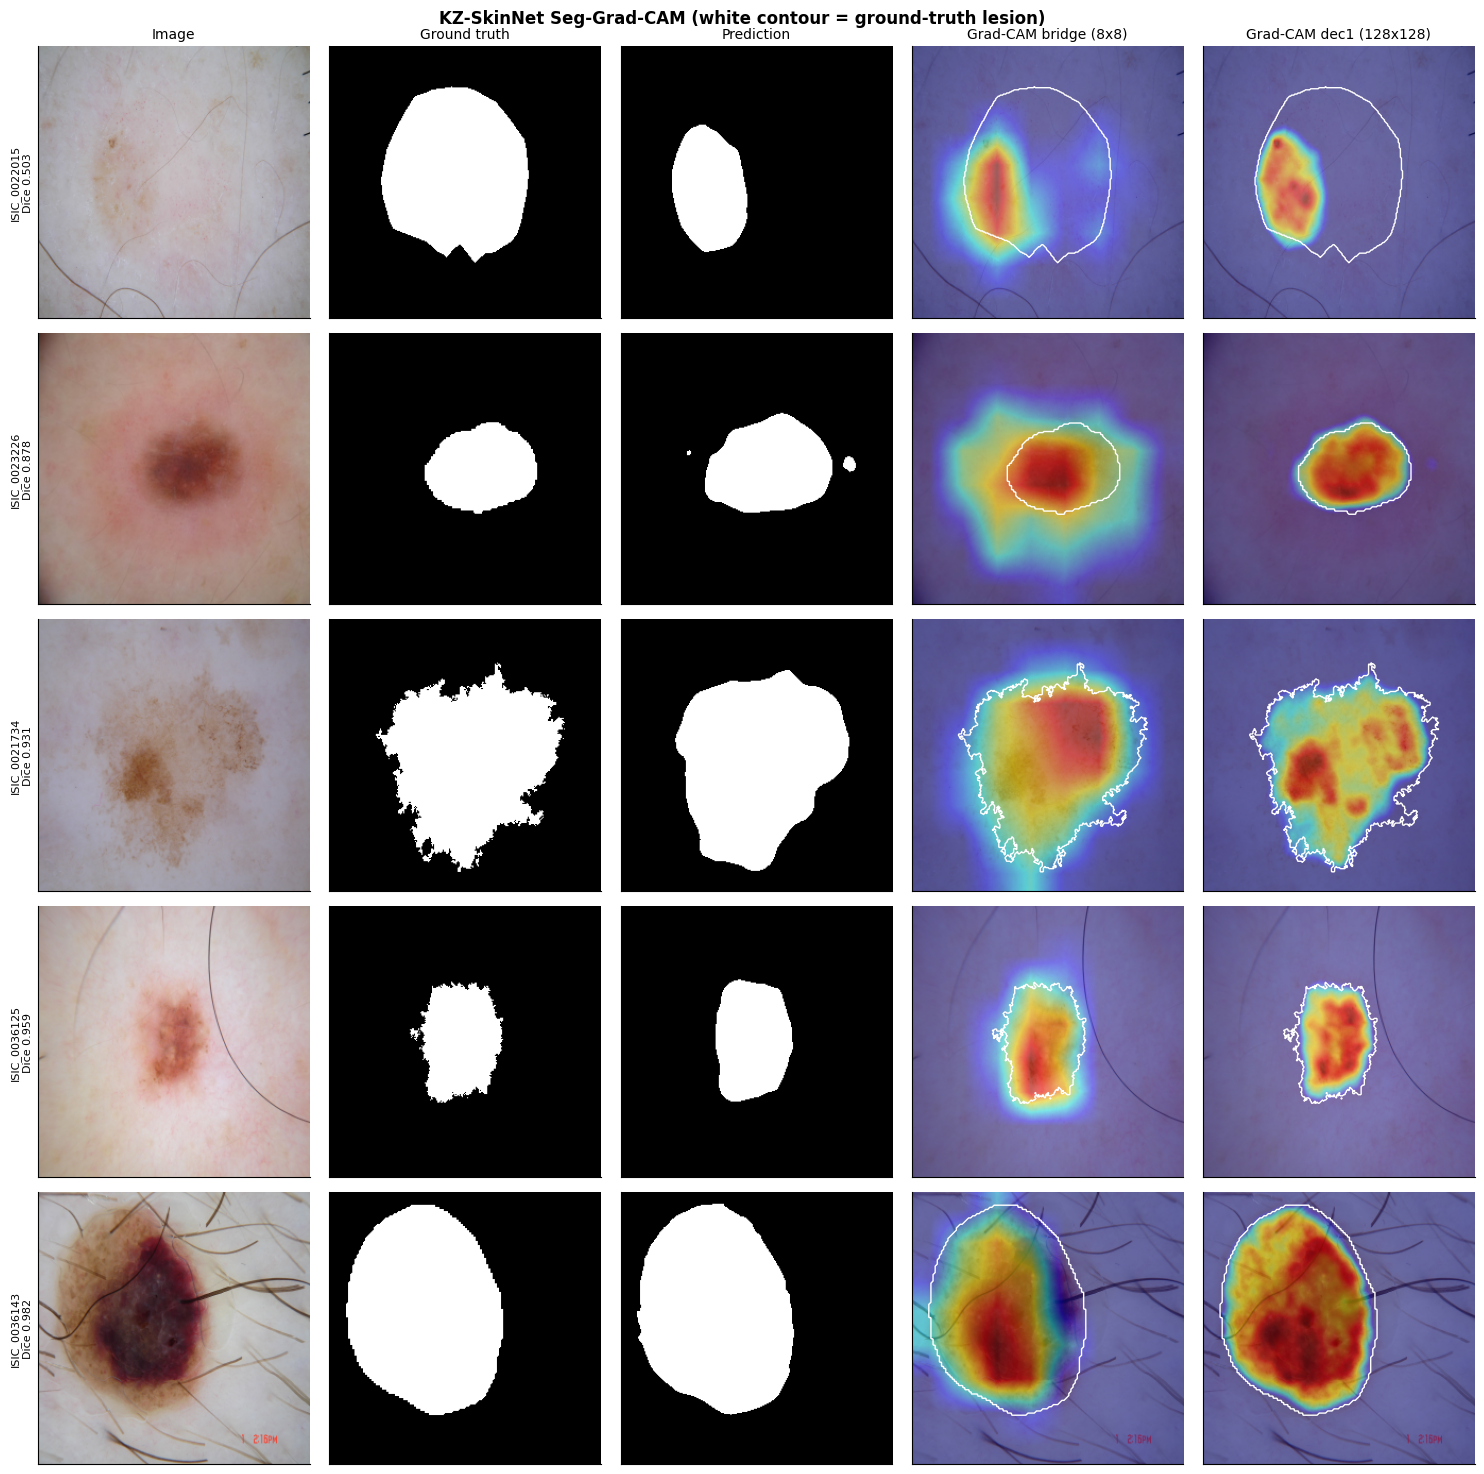

Saved: /kaggle/working/reviewer_experiments/gradcam_examples.png


In [ ]:
# ============================================================
# CELL G: GRAD-CAM FOR SEGMENTATION + QUANTITATIVE EVALUATION (R1.6, R2.3, R4.13) - KZ-SkinNet (A0)
# Seg-Grad-CAM: scalar target = sum of predicted lesion probabilities inside the predicted lesion
# region (pixels with p >= 0.5); gradients of this target w.r.t. a chosen feature map.
# Two layers are analysed: the bottleneck ("bridge", 8x8, most semantic) and the last decoder
# block ("dec1", 128x128, finest). The output layer itself is NOT used (it would just copy the mask).
# Quantitative metrics on ALL test images, compared with a uniform-map baseline:
#   Energy-in-lesion  = sum(CAM * GT) / sum(CAM)          (baseline = lesion area fraction)
#   Pointing game hit = CAM maximum lies inside the GT lesion
#   CAM-IoU           = IoU(CAM >= 0.5, GT)
# ============================================================
CAM_LAYERS = {"bridge (8x8)": "bridge_relu", "dec1 (128x128)": "dec1_relu"}
model, ck = load_model("A0")
grad_model = tf.keras.Model(model.input, [model.get_layer(l).output for l in CAM_LAYERS.values()] + [model.output])

def seg_gradcam(imgs_uint8, bs=16):
    cams = {k: [] for k in CAM_LAYERS}; probs = []
    for i in range(0, len(imgs_uint8), bs):
        x = tf.constant(to_input(imgs_uint8[i:i+bs]))
        with tf.GradientTape() as tape:
            *feats, pred = grad_model(x, training=False)
            tape.watch(feats)
            roi = tf.cast(pred >= THRESHOLD, tf.float32)
            target = tf.reduce_sum(pred * roi, axis=[1, 2, 3])           # one scalar per image
            total = tf.reduce_sum(target)                                 # images are independent
        grads = tape.gradient(total, feats)
        for (name, _), f, g in zip(CAM_LAYERS.items(), feats, grads):
            w = tf.reduce_mean(g, axis=[1, 2], keepdims=True)             # channel weights
            cam = tf.nn.relu(tf.reduce_sum(w * f, axis=-1))
            cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear")[..., 0].numpy()
            mx = cam.reshape(len(cam), -1).max(1).reshape(-1, 1, 1)
            cams[name].append(cam / (mx + 1e-12))
        probs.append(pred.numpy()[..., 0])
    return {k: np.concatenate(v) for k, v in cams.items()}, np.concatenate(probs)

imgs, gt = RAW["Test"]
CAMS, PROB = seg_gradcam(imgs)
area = gt.reshape(len(gt), -1).mean(1)
has_pred = (PROB >= THRESHOLD).reshape(len(gt), -1).any(1)
rows = []
for name, cam in CAMS.items():
    ok = has_pred & (cam.reshape(len(cam), -1).sum(1) > 0)          # images with a non-empty CAM
    if ok.sum() == 0:
        rows.append({"Layer": name, "Images": 0, "Energy-in-lesion (%)": "CAM empty for all images"}); continue
    c, g = cam[ok], gt[ok]
    energy = (c * g).reshape(len(c), -1).sum(1) / c.reshape(len(c), -1).sum(1)
    flat = c.reshape(len(c), -1).argmax(1)
    hit = g.reshape(len(g), -1)[np.arange(len(g)), flat]
    b = c >= 0.5
    ciou = (b & g).reshape(len(g), -1).sum(1) / ((b | g).reshape(len(g), -1).sum(1) + 1e-12)
    rows.append({"Layer": name, "Images": int(ok.sum()),
                 "Energy-in-lesion (%)": f"{100*energy.mean():.2f} ± {100*energy.std(ddof=1):.2f}",
                 "Uniform-map baseline (%)": f"{100*area[ok].mean():.2f}",
                 "Pointing-game hit rate (%)": round(100 * hit.mean(), 2),
                 "CAM-IoU with GT (%)": f"{100*ciou.mean():.2f} ± {100*ciou.std(ddof=1):.2f}"})
gq = pd.DataFrame(rows)
print(f"Seg-Grad-CAM quantitative evaluation, ISIC 2018 test set (KZ-SkinNet, checkpoint {os.path.basename(ck)})")
display(gq); gq.to_csv(f"{OUT}/gradcam_quantitative.csv", index=False)

# ---------------- figure: 5 test images spanning the Dice range ----------------
d = per_image_metrics(PROB, gt).Dice.to_numpy()
pick = [int(np.argmin(np.abs(d - np.quantile(d, q)))) for q in [0.02, 0.25, 0.5, 0.75, 0.98]]
def overlay(img, cam):
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return (0.55 * img + 0.45 * heat).astype(np.uint8)
cols = ["Image", "Ground truth", "Prediction"] + [f"Grad-CAM {n}" for n in CAM_LAYERS]
fig, ax = plt.subplots(len(pick), len(cols), figsize=(3 * len(cols), 3 * len(pick)))
for r, i in enumerate(pick):
    panels = [imgs[i], gt[i], PROB[i] >= THRESHOLD] + [overlay(imgs[i], CAMS[n][i]) for n in CAM_LAYERS]
    for c, p in enumerate(panels):
        a = ax[r, c]; a.imshow(p, cmap="gray" if p.ndim == 2 else None); a.set_xticks([]); a.set_yticks([])
        if c >= 3:
            a.contour(gt[i], levels=[0.5], colors="white", linewidths=1)
        if r == 0: a.set_title(cols[c], fontsize=10)
    ax[r, 0].set_ylabel(f"{DFS['Test'].image.iloc[i].split('/')[-1][:-4]}\nDice {d[i]:.3f}", fontsize=8)
fig.suptitle("KZ-SkinNet Seg-Grad-CAM (white contour = ground-truth lesion)", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/gradcam_examples.png", dpi=300, bbox_inches="tight"); plt.show()
print("Saved:", f"{OUT}/gradcam_examples.png")

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

LIME 1/30 done


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

... (111 outputs left out)

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

LIME 30/30 done

LIME on 30 ISIC 2018 test images, 500 perturbations, 50 SLIC superpixels (%)
'Lesion area fraction' = what a random explanation would score


,Positive weight inside lesion,Top-5 superpixel precision,Lesion area fraction,Images with NO positive superpixel
Config,,,,
"C1 original (global target, black fill)",22.73 ± 26.92,22.24 ± 28.66,29.11 ± 25.11,0
"C2 (global target, skin-colour fill)",51.57 ± 36.97,57.42 ± 39.44,29.11 ± 25.11,0
"C3 proposed (lesion-ROI target, skin fill)",71.35 ± 21.92,79.12 ± 28.44,29.11 ± 25.11,0


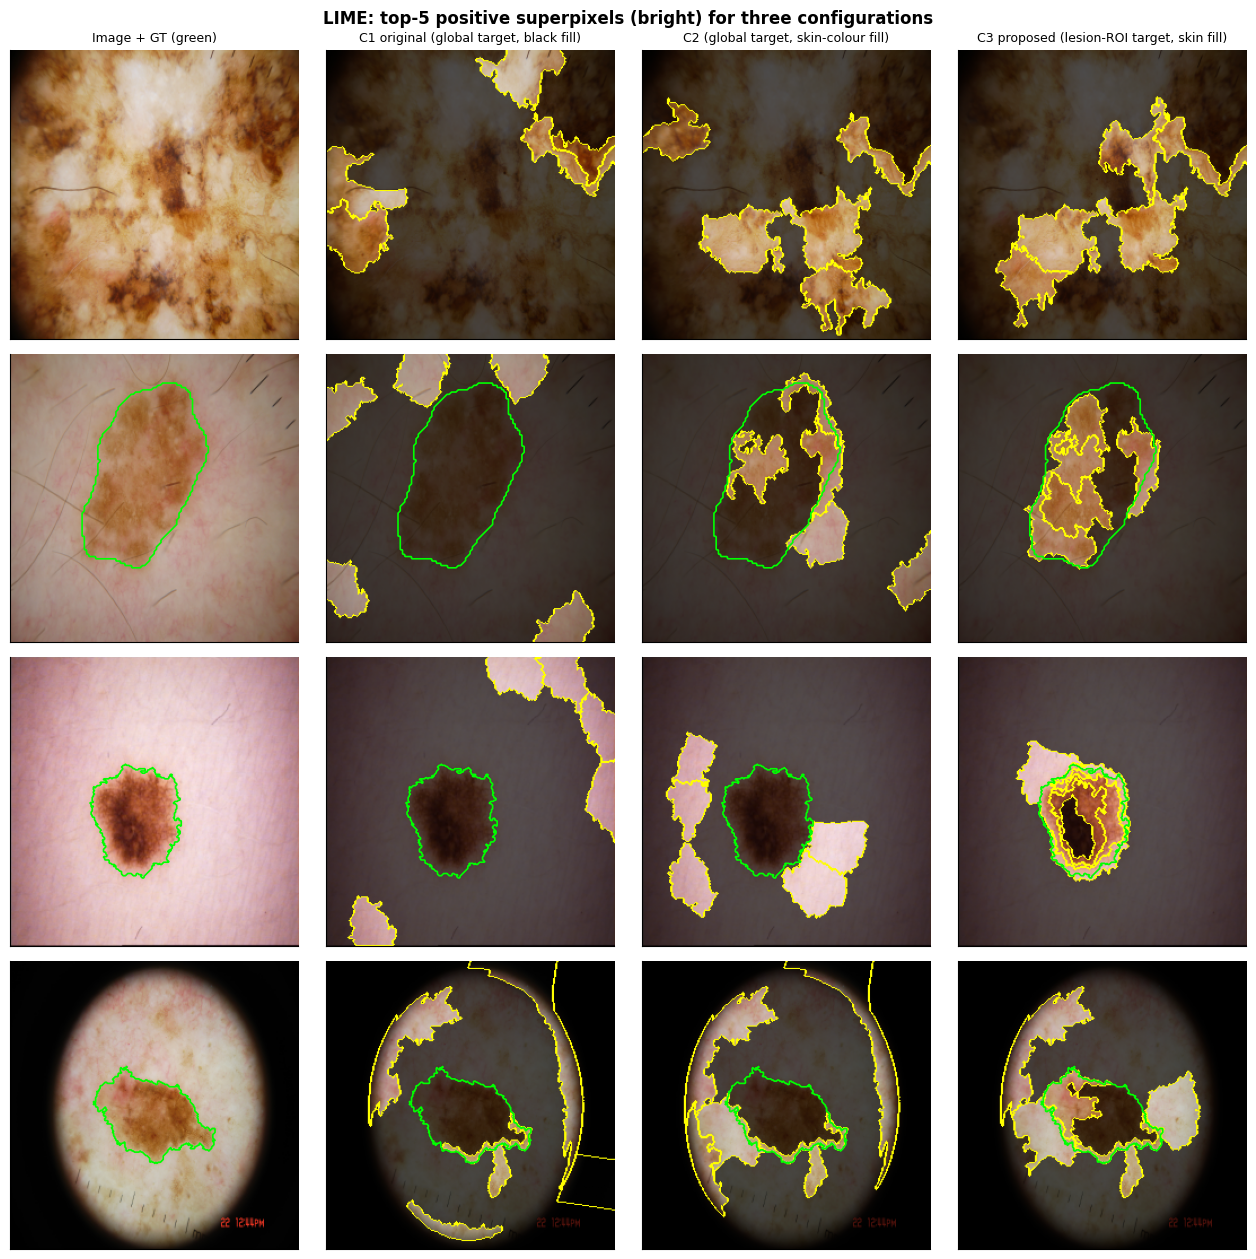

Saved: /kaggle/working/reviewer_experiments/lime_configurations.png


In [ ]:
# ============================================================
# CELL L: WHY LIME HIGHLIGHTED THE BACKGROUND (R1.7) + QUANTITATIVE LIME (R1.6, R2.3, R4.13) - A0
# The original LIME set-up (i) explained the MEAN lesion probability of the WHOLE image and
# (ii) replaced hidden superpixels with BLACK (hide_color = 0).
# Hypothesis tested here: black patches resemble dark lesions, so hiding background superpixels
# changes the predicted lesion area and background superpixels receive large weights.
# We compare 3 configurations on the same superpixels:
#   C1 original : target = whole-image mean probability, hidden superpixels = black
#   C2          : target = whole-image mean probability, hidden superpixels = skin colour
#   C3 proposed : target = mean probability inside the predicted lesion, hidden = skin colour
# Skin colour = mean RGB of the outer 10% image border (no ground truth used).
# Metric: share of the positive LIME weight that falls inside the GT lesion (higher = better).
# ============================================================
from lime import lime_image
from skimage.segmentation import slic, mark_boundaries
N_LIME, N_PERTURB, N_SEG, TOP_K = 30, 500, 50, 5
model, ck = load_model("A0")
imgs, gt = RAW["Test"]
rng = np.random.default_rng(SEED)
sel = rng.choice(len(imgs), N_LIME, replace=False)

def border_colour(img, frac=0.1):
    b = max(1, int(frac * img.shape[0])); m = np.ones(img.shape[:2], bool); m[b:-b, b:-b] = False
    return img[m].mean(0)

def make_fn(mode, roi):
    def fn(batch):
        p = model.predict(to_input(np.asarray(batch, dtype=np.uint8)), batch_size=64, verbose=0)[..., 0]
        s = p.reshape(len(p), -1).mean(1) if mode == "global" else (p * roi).reshape(len(p), -1).sum(1) / (roi.sum() + 1e-12)
        return np.column_stack([1 - s, s])
    return fn

CONFIGS = {"C1 original (global target, black fill)": ("global", "black"),
           "C2 (global target, skin-colour fill)":     ("global", "skin"),
           "C3 proposed (lesion-ROI target, skin fill)": ("roi", "skin")}
explainer = lime_image.LimeImageExplainer(random_state=SEED)
res, store = [], {}
for n, i in enumerate(sel):
    img = imgs[i]; g = gt[i]
    roi = (predict(model, img[None])[0] >= THRESHOLD).astype(np.float32)
    if roi.sum() == 0:
        continue
    segs = slic(img, n_segments=N_SEG, compactness=10, start_label=0)
    frac_in = np.array([g[segs == s].mean() for s in range(segs.max() + 1)])
    for cname, (mode, fill) in CONFIGS.items():
        hide = 0 if fill == "black" else border_colour(img)
        exp = explainer.explain_instance(img.astype(np.double), make_fn(mode, roi), labels=(1,), top_labels=None,
                                         hide_color=hide, num_samples=N_PERTURB, batch_size=100,
                                         segmentation_fn=lambda _x, s=segs: s, random_seed=SEED)
        w = dict(exp.local_exp[1]); wpos = {s: v for s, v in w.items() if v > 0}
        tot = sum(wpos.values())
        share = sum(v * frac_in[s] for s, v in wpos.items()) / tot if tot > 0 else np.nan
        top = sorted(wpos, key=wpos.get, reverse=True)[:TOP_K]
        top_area = np.isin(segs, top)
        top_prec = (top_area & g).sum() / max(top_area.sum(), 1)
        res.append({"Image": i, "Config": cname, "Positive weight inside lesion": share,
                    f"Top-{TOP_K} superpixel precision": top_prec, "Lesion area fraction": g.mean()})
        store[(i, cname)] = (segs, top)
    print(f"LIME {n+1}/{N_LIME} done")

lr = pd.DataFrame(res)
assert len(lr), "No test image had a predicted lesion - check the A0 checkpoint"
summ = lr.groupby("Config", sort=False)[["Positive weight inside lesion", f"Top-{TOP_K} superpixel precision", "Lesion area fraction"]].agg(["mean", "std"]) * 100
summ = pd.DataFrame({c: summ[c]["mean"].round(2).astype(str) + " ± " + summ[c]["std"].round(2).astype(str)
                     for c in ["Positive weight inside lesion", f"Top-{TOP_K} superpixel precision", "Lesion area fraction"]})
summ["Images with NO positive superpixel"] = lr.groupby("Config", sort=False)["Positive weight inside lesion"].apply(lambda v: int(v.isna().sum()))
print(f"\nLIME on {lr.Image.nunique()} ISIC 2018 test images, {N_PERTURB} perturbations, {N_SEG} SLIC superpixels (%)")
print("'Lesion area fraction' = what a random explanation would score")
display(summ)
lr.to_csv(f"{OUT}/lime_quantitative.csv", index=False)

# ---------------- figure: 4 examples, 3 configurations ----------------
show_ids = list(dict.fromkeys(lr.Image))[:4]
fig, ax = plt.subplots(len(show_ids), 1 + len(CONFIGS), figsize=(3.2 * (1 + len(CONFIGS)), 3.2 * len(show_ids)))
for r, i in enumerate(show_ids):
    ax[r, 0].imshow(imgs[i]); ax[r, 0].contour(gt[i], levels=[0.5], colors="lime", linewidths=1.2)
    for c, cname in enumerate(CONFIGS, start=1):
        segs, top = store[(i, cname)]
        vis = imgs[i].copy().astype(float); keep = np.isin(segs, top)
        vis[~keep] *= 0.35
        ax[r, c].imshow(mark_boundaries(vis.astype(np.uint8), segs * keep, color=(1, 1, 0)))
        ax[r, c].contour(gt[i], levels=[0.5], colors="lime", linewidths=1.2)
        if r == 0: ax[r, c].set_title(cname, fontsize=9)
    if r == 0: ax[r, 0].set_title("Image + GT (green)", fontsize=9)
    for a in ax[r]: a.set_xticks([]); a.set_yticks([])
fig.suptitle(f"LIME: top-{TOP_K} positive superpixels (bright) for three configurations", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/lime_configurations.png", dpi=300, bbox_inches="tight"); plt.show()
print("Saved:", f"{OUT}/lime_configurations.png")

## 12. Explainability: SHAP (quantitative)
Model-agnostic SHAP (Partition explainer) with the same target as LIME C3 (mean lesion probability inside the predicted lesion); hidden regions are blurred (not black). Same metrics as Grad-CAM, on 105 ISIC 2018 test images.

A0 checkpoint: /kaggle/working/ablation/A0_best.weights.h5
SHAP 10/105 images  (2.5 min)
SHAP 20/105 images  (3.9 min)
SHAP 30/105 images  (5.3 min)
SHAP 40/105 images  (6.7 min)
SHAP 50/105 images  (8.1 min)
SHAP 60/105 images  (9.5 min)
SHAP 70/105 images  (10.9 min)
SHAP 80/105 images  (12.3 min)
SHAP 90/105 images  (13.7 min)
SHAP 100/105 images  (15.0 min)

SHAP (Partition explainer, blur(64,64) masker, 1000 evaluations/image) - KZ-SkinNet, ISIC 2018 test set
Target: mean lesion probability inside the predicted lesion | baseline = what a uniform map would score
                                             Value
Images                                         105
Images with no positive attribution              0
Energy-in-lesion (%)                 58.11 ± 25.47
Uniform-map baseline (%)                     28.19
Pointing-game hit rate (%)                   71.43
SHAP-IoU with GT (%)                 30.02 ± 17.99


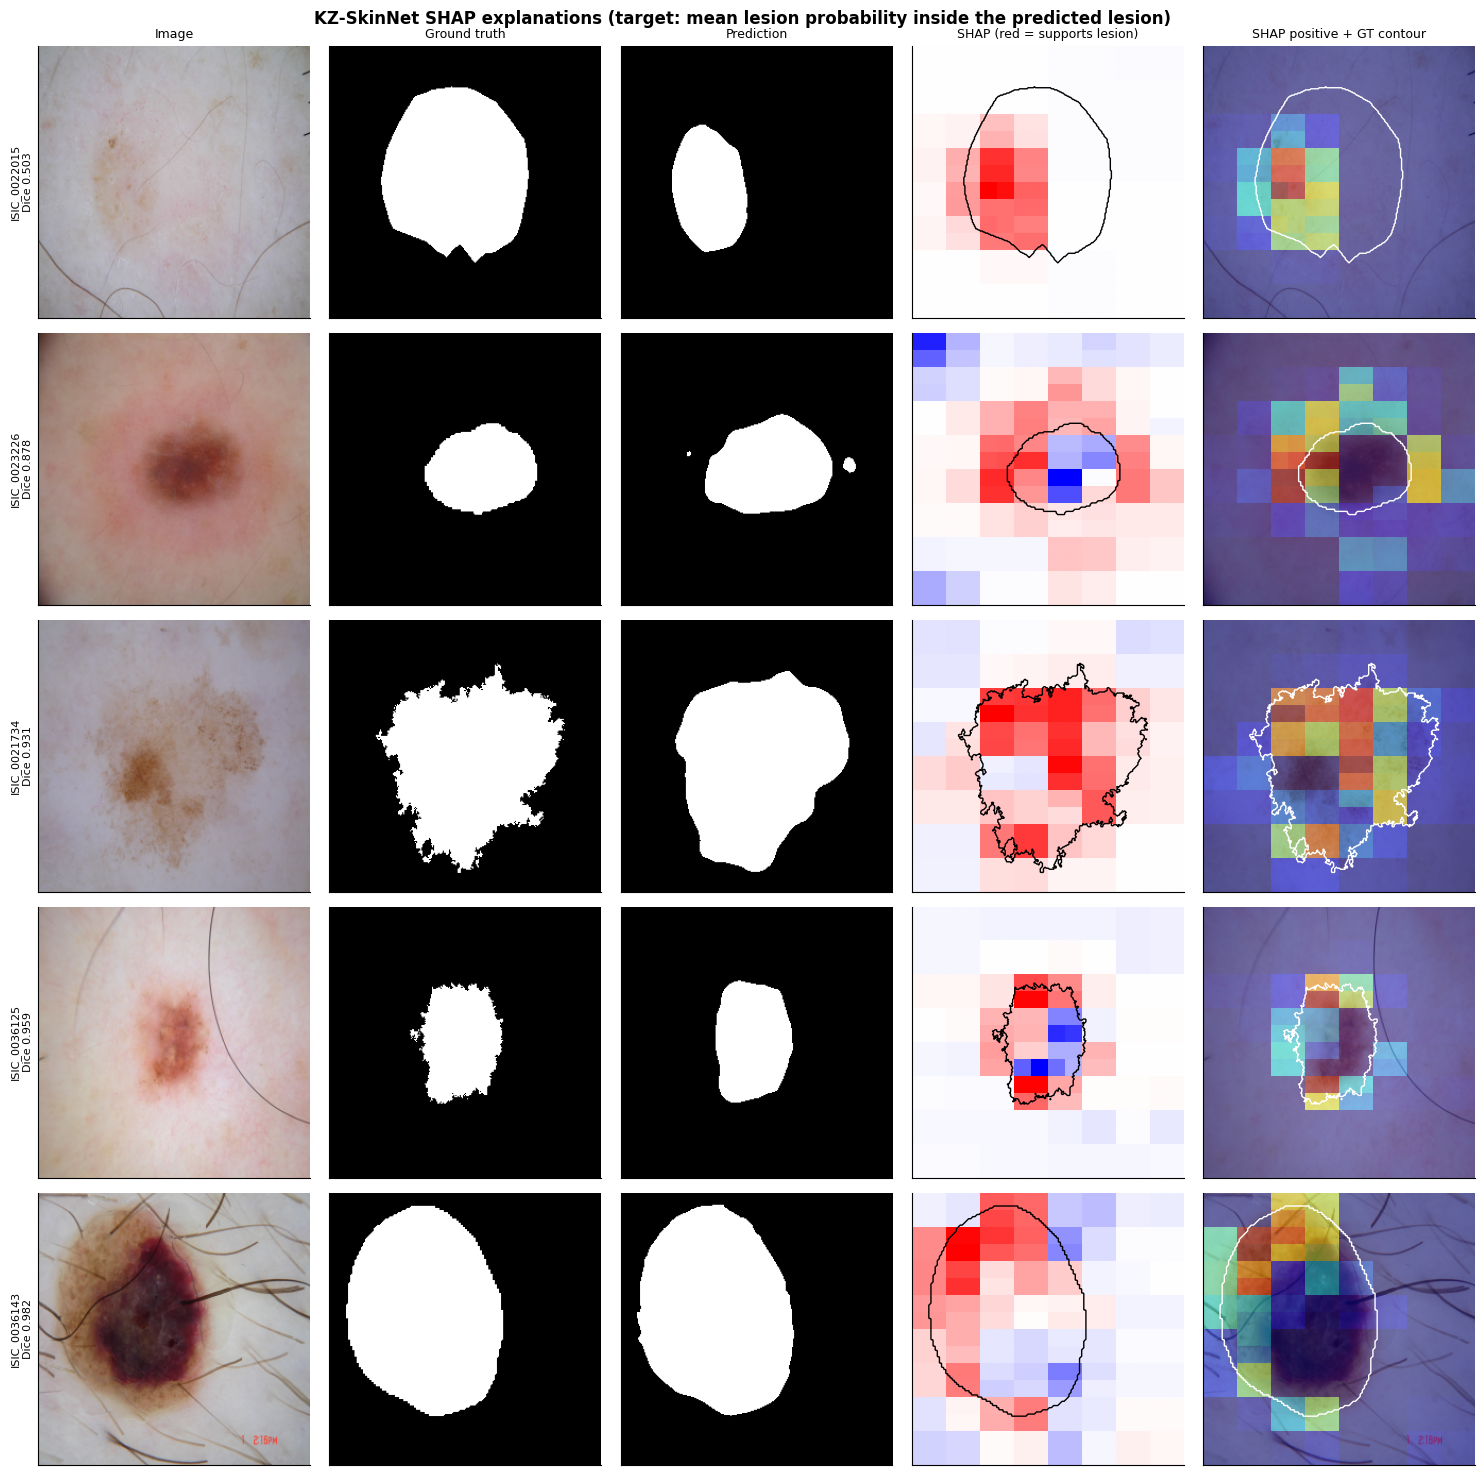

Saved: /kaggle/working/reviewer_experiments/shap_examples.png


In [ ]:
# ============================================================
# CELL H (single cell): SHAP FOR SEGMENTATION + QUANTITATIVE EVALUATION (R1.6, R2.3, R4.13) - KZ-SkinNet (A0)
# Model-agnostic SHAP (Partition explainer) on a scalar target = mean predicted lesion probability
# inside the predicted lesion (same target as LIME C3). Hidden regions are BLURRED, not black.
# Same metrics as Grad-CAM, compared with a uniform-map baseline (= lesion area fraction):
#   Energy-in-lesion = positive SHAP inside GT / all positive SHAP;  Pointing game;  SHAP-IoU
# Part 1 re-defines the CELL S helpers (safe even if older cells overwrote them).
# Needs CELL S to have been run once (data in RAM) and the shap package (pip install shap).
# ============================================================
assert "RAW" in globals(), "Run CELL S once first (it loads the data)"
tf.keras.mixed_precision.set_global_policy("float32")

# ---------------- Part 1: helpers (same as CELL S) ----------------
def to_input(imgs_uint8):
    return imgs_uint8.astype(np.float32) / 127.5 - 1.0

def conv_block(x, filters, name, separable=True):
    Conv = layers.SeparableConv2D if separable else layers.Conv2D
    x = Conv(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def features_by_resolution(bb):
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8): feats[s[1]] = l.output
        except Exception: pass
    return feats[128], feats[64], feats[32], feats[16], feats[8]

def encoder_features(inp, kind, weights=None):
    if kind == "v3small":
        return features_by_resolution(tf.keras.applications.MobileNetV3Small(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v3large":
        return features_by_resolution(tf.keras.applications.MobileNetV3Large(
            input_tensor=inp, include_top=False, weights=weights, include_preprocessing=False))
    if kind == "v2":
        bb = tf.keras.applications.MobileNetV2(input_tensor=inp, include_top=False, weights=weights, alpha=1.0)
        g = lambda n: bb.get_layer(n).output
        return (g("block_1_expand_relu"), g("block_3_expand_relu"), g("block_6_expand_relu"),
                g("block_13_expand_relu"), g("out_relu"))
    if kind == "effb0":
        # weights="imagenet" is required so the graph contains EfficientNet's extra rescaling layer (as in training)
        x255 = layers.Lambda(lambda t: (t + 1.0) * 127.5, name="to_0_255")(inp)
        bb = tf.keras.applications.EfficientNetB0(input_tensor=x255, include_top=False, weights="imagenet")
        g = lambda n: bb.get_layer(n).output
        return (g("block2a_expand_activation"), g("block3a_expand_activation"),
                g("block4a_expand_activation"), g("block6a_expand_activation"), g("top_activation"))

def build_seg(encoder="v3small", separable=True, use_skip=True, weights=None):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    s1, s2, s3, s4, bridge = encoder_features(inp, encoder, weights)
    x = conv_block(bridge, 128, "bridge", separable)
    for skip, f, n in [(s4, 96, "dec4"), (s3, 64, "dec3"), (s2, 32, "dec2"), (s1, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        if use_skip:
            x = layers.Concatenate(name=n + "_cat")([x, skip])
        x = conv_block(x, f, n, separable)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x))

def unet_block(x, f, name):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{name}_c{i}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i}")(x)
        x = layers.Activation("relu", name=f"{name}_r{i}")(x)
    return x

def build_unet(filters=(64, 128, 256, 512, 1024)):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3)); skips, x = [], inp
    for i, f in enumerate(filters[:-1]):
        x = unet_block(x, f, f"enc{i+1}"); skips.append(x); x = layers.MaxPooling2D(2, name=f"pool{i+1}")(x)
    x = unet_block(x, filters[-1], "bottleneck")
    for i, (f, s) in enumerate(zip(reversed(filters[:-1]), reversed(skips))):
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i+1}")(x)
        x = layers.Concatenate(name=f"cat{i+1}")([x, s]); x = unet_block(x, f, f"dec{i+1}")
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x), name="Vanilla_UNet")

MODELS = {   # id: (name, builder)
    "A0": ("KZ-SkinNet (Proposed)",        lambda: build_seg()),
    "A1": ("MobileNetV2 Encoder",          lambda: build_seg(encoder="v2")),
    "A2": ("Standard Conv Decoder",        lambda: build_seg(separable=False)),
    "A3": ("Without Skip Connections",     lambda: build_seg(use_skip=False)),
    "A4": ("BCE-only Loss",                lambda: build_seg()),
    "A5": ("Dice-only Loss",               lambda: build_seg()),
    "U0": ("Baseline U-Net (vanilla)",     lambda: build_unet()),
    "L1": ("EfficientNetB0-UNet",          lambda: build_seg(encoder="effb0")),
    "L2": ("MobileNetV3Large-UNet",        lambda: build_seg(encoder="v3large")),
}

def find_ckpt(key):
    pref = ["comparison_v2"] if key == "U0" else []          # use the re-trained U0 if it exists
    hits = []
    for d in ["/kaggle/working", "/kaggle/input"]:
        hits += sorted(glob.glob(os.path.join(d, "**", f"{key}_best.weights.h5"), recursive=True))
    for p in pref:
        for h in hits:
            if p in h: return h
    return hits[0] if hits else None

def load_model(key):
    tf.keras.backend.clear_session()
    m = MODELS[key][1](); ck = find_ckpt(key)
    assert ck, f"checkpoint for {key} not found"
    m.load_weights(ck)
    return m, ck

def predict(model, imgs_uint8, bs=BATCH_SIZE):
    return model.predict(to_input(imgs_uint8), batch_size=bs, verbose=0)[..., 0]

def per_image_metrics(prob, gt, thr=THRESHOLD):
    p = prob >= thr
    tp = (gt & p).sum((1, 2)).astype(float); fp = (~gt & p).sum((1, 2)).astype(float)
    fn = (gt & ~p).sum((1, 2)).astype(float); tn = (~gt & ~p).sum((1, 2)).astype(float)
    e = 1e-12
    return pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "TN": tn,
                         "Dice": 2*tp/(2*tp+fp+fn+e), "IoU": tp/(tp+fp+fn+e),
                         "Precision": tp/(tp+fp+e), "Sensitivity": tp/(tp+fn+e), "Specificity": tn/(tn+fp+e)})

# ---------------- Part 2: SHAP ----------------
import shap
N_SHAP     = 100       # test images explained (random, fixed seed); 1000 = all (~10x longer)
MAX_EVALS  = 1000      # model evaluations per image for the Partition explainer
MASK_BLUR  = "blur(64,64)"   # hidden regions are blurred (not black) -> no artificial dark "lesions"
model, ck = load_model("A0")
print("A0 checkpoint:", ck)
imgs, gt = RAW["Test"]
PROB = predict(model, imgs)
d_all = per_image_metrics(PROB, gt).Dice.to_numpy()
rng = np.random.default_rng(SEED)
cand = np.where((PROB >= THRESHOLD).reshape(len(PROB), -1).any(1))[0]          # images with a predicted lesion
sel = np.sort(rng.choice(cand, min(N_SHAP, len(cand)), replace=False))
# always include 5 images spanning the Dice range (used for the figure)
fig_ids = [int(cand[np.argmin(np.abs(d_all[cand] - np.quantile(d_all[cand], q)))]) for q in [0.02, 0.25, 0.5, 0.75, 0.98]]
sel = np.unique(np.concatenate([sel, fig_ids]))

masker = shap.maskers.Image(MASK_BLUR, (IMG_SIZE, IMG_SIZE, 3))

def shap_map(i):
    roi = (PROB[i] >= THRESHOLD).astype(np.float32)
    def f(x):                                    # x: batch of (masked) RGB images in [0,255]
        p = model.predict(to_input(np.clip(x, 0, 255).astype(np.uint8)), batch_size=64, verbose=0)[..., 0]
        return (p * roi).reshape(len(p), -1).sum(1) / roi.sum()   # mean lesion probability inside predicted lesion
    expl = shap.Explainer(f, masker)
    sv = expl(imgs[i:i+1].astype(np.float32), max_evals=MAX_EVALS, batch_size=64, silent=True)
    return np.asarray(sv.values)[0].sum(-1).reshape(IMG_SIZE, IMG_SIZE)    # sum over RGB channels

MAPS, rows = {}, []
t0 = time.time()
for n, i in enumerate(sel):
    s = shap_map(i); MAPS[i] = s
    pos = np.clip(s, 0, None); g = gt[i]
    if pos.sum() <= 0:
        rows.append({"Image": i, "Dice": d_all[i], "Energy-in-lesion": np.nan, "Pointing hit": np.nan,
                     "SHAP-IoU": np.nan, "Lesion area": g.mean()}); continue
    pn = pos / pos.max()
    b = pn >= 0.5
    rows.append({"Image": i, "Dice": d_all[i],
                 "Energy-in-lesion": (pos * g).sum() / pos.sum(),            # share of positive attribution in GT
                 "Pointing hit": float(g.reshape(-1)[np.argmax(pos)]),        # max attribution inside GT
                 "SHAP-IoU": (b & g).sum() / max((b | g).sum(), 1),           # IoU(attribution >= 0.5 max, GT)
                 "Lesion area": g.mean()})
    if (n + 1) % 10 == 0:
        print(f"SHAP {n+1}/{len(sel)} images  ({(time.time()-t0)/60:.1f} min)")

sq = pd.DataFrame(rows)
ok = sq.dropna()
summary = pd.DataFrame([{
    "Images": len(ok), "Images with no positive attribution": int(sq["Energy-in-lesion"].isna().sum()),
    "Energy-in-lesion (%)": f"{100*ok['Energy-in-lesion'].mean():.2f} ± {100*ok['Energy-in-lesion'].std(ddof=1):.2f}",
    "Uniform-map baseline (%)": f"{100*ok['Lesion area'].mean():.2f}",
    "Pointing-game hit rate (%)": round(100 * ok["Pointing hit"].mean(), 2),
    "SHAP-IoU with GT (%)": f"{100*ok['SHAP-IoU'].mean():.2f} ± {100*ok['SHAP-IoU'].std(ddof=1):.2f}"}])
print(f"\nSHAP (Partition explainer, {MASK_BLUR} masker, {MAX_EVALS} evaluations/image) - KZ-SkinNet, ISIC 2018 test set")
print("Target: mean lesion probability inside the predicted lesion | baseline = what a uniform map would score")
print(summary.T.rename(columns={0: "Value"}).to_string())
sq.to_csv(f"{OUT}/shap_quantitative_per_image.csv", index=False); summary.to_csv(f"{OUT}/shap_quantitative.csv", index=False)

# ---------------- figure: same 5 Dice-quantile images as the Grad-CAM figure ----------------
cols = ["Image", "Ground truth", "Prediction", "SHAP (red = supports lesion)", "SHAP positive + GT contour"]
fig, ax = plt.subplots(len(fig_ids), len(cols), figsize=(3 * len(cols), 3 * len(fig_ids)))
for r, i in enumerate(fig_ids):
    s = MAPS[i]; lim = np.abs(s).max() + 1e-12
    pos = np.clip(s, 0, None); pos = pos / (pos.max() + 1e-12)
    heat = cv2.applyColorMap((pos * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    panels = [(imgs[i], None, None), (gt[i], "gray", None), (PROB[i] >= THRESHOLD, "gray", None),
              (s, "bwr", (-lim, lim)), ((0.55 * imgs[i] + 0.45 * heat).astype(np.uint8), None, None)]
    for c, (p, cmap, rngv) in enumerate(panels):
        a = ax[r, c]
        a.imshow(p, cmap=cmap, vmin=None if rngv is None else rngv[0], vmax=None if rngv is None else rngv[1])
        a.set_xticks([]); a.set_yticks([])
        if c >= 3: a.contour(gt[i], levels=[0.5], colors="black" if c == 3 else "white", linewidths=1)
        if r == 0: a.set_title(cols[c], fontsize=9)
    ax[r, 0].set_ylabel(f"{DFS['Test'].image.iloc[i].split('/')[-1][:-4]}\nDice {d_all[i]:.3f}", fontsize=8)
fig.suptitle("KZ-SkinNet SHAP explanations (target: mean lesion probability inside the predicted lesion)", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{OUT}/shap_examples.png", dpi=300, bbox_inches="tight"); plt.show()
print("Saved:", f"{OUT}/shap_examples.png")

## 13. 5-fold cross-validation of KZ-SkinNet (A0)
The 2,594 ISIC 2018 training images are split into 5 folds, stratified by lesion-area quintile. In each fold A0 is trained from ImageNet initialisation on 4 folds (2,075–2,076 images), with checkpointing and early stopping on the held-out fold (518–519 images) instead of the 100-image official validation set. The protocol is otherwise identical to A0 (max 20 epochs, EarlyStopping 5, ReduceLROnPlateau 2, Adam 1e-4, batch 16, 0.5·BCE + 0.5·Dice). Every fold model is also evaluated on the untouched official ISIC 2018 test set (1,000 images). Metrics are pixel-level pooled at threshold 0.5 and reported as mean ± SD over the 5 folds, followed by Loss / Dice / IoU / F1-score curves for every fold.

**Result (mean ± SD over 5 folds):** held-out folds Dice 90.66 ± 0.70, IoU 82.92 ± 1.17, AUC 98.67 ± 0.16; ISIC 2018 test Dice 87.99 ± 1.09, IoU 78.56 ± 1.73, AUC 97.39 ± 0.39. All folds used the full 20-epoch budget, like A0.

*This cell is standalone: it loads the data itself and needs no saved checkpoint.*

TensorFlow 2.20.0 | GPUs: 1 | compute capability: (7, 5)
train: 2594 images (255s)
Test: 1000 images (64s)

########## fold 1/5: train 2075 | validation 519  [mixed_float16, XLA off]


4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
130/130 - 229s - 2s/step - accuracy: 0.7595 - dice_coefficient: 0.4394 - f1_score: 0.5957 - iou_score: 0.2860 - loss: 0.5693 - val_accuracy: 0.8133 - val_dice_coefficient: 0.2815 - val_f1_score: 0.3291 - val_iou_score: 0.1697 - val_loss: 0.6809 - learning_rate: 1.0000e-04
Epoch 2/20
130/130 - 17s - 130ms/step - accuracy: 0.9176 - dice_coefficient: 0.5824 - f1_score: 0.8213 - iou_score: 0.4140 - loss: 0.3809 - val_accuracy: 0.8472 - val_dice_coefficient: 0.2972 - val_f1_score: 0.4275 - val_iou_score: 0.1809 - val_loss: 0.6256 - learning_rate: 1.0000e-04
Epoch 3/20
130/130 - 17s - 134ms/step - accuracy: 0.9382 - dice_coefficient: 0.6266 - f1_score: 0.8578 - iou_score: 0.4601 - loss: 0.3294 - val_accuracy: 0.9129 - val_dice_coefficient: 0.4000 - val_f1_score: 0.6936 - val_iou_score: 0.2618 - val_loss: 0.4898 - learning_rate: 1.0000e-04
Epoch 4/20
130/130 - 17s - 130ms/step - accuracy: 0.9439 - dice_coefficient: 0.6515 - f1_score:

fold 1: done

########## fold 2/5: train 2075 | validation 519  [mixed_float16, XLA off]


Epoch 1/20
130/130 - 52s - 402ms/step - accuracy: 0.8024 - dice_coefficient: 0.4471 - f1_score: 0.6285 - iou_score: 0.2930 - loss: 0.5249 - val_accuracy: 0.8065 - val_dice_coefficient: 0.2905 - val_f1_score: 0.3446 - val_iou_score: 0.1753 - val_loss: 0.6643 - learning_rate: 1.0000e-04
Epoch 2/20
130/130 - 17s - 133ms/step - accuracy: 0.9268 - dice_coefficient: 0.6190 - f1_score: 0.8356 - iou_score: 0.4520 - loss: 0.3359 - val_accuracy: 0.8522 - val_dice_coefficient: 0.3192 - val_f1_score: 0.4718 - val_iou_score: 0.1961 - val_loss: 0.5842 - learning_rate: 1.0000e-04
Epoch 3/20
130/130 - 17s - 134ms/step - accuracy: 0.9424 - dice_coefficient: 0.6734 - f1_score: 0.8674 - iou_score: 0.5111 - loss: 0.2804 - val_accuracy: 0.9052 - val_dice_coefficient: 0.4272 - val_f1_score: 0.6787 - val_iou_score: 0.2838 - val_loss: 0.4585 - learning_rate: 1.0000e-04
Epoch 4/20
130/130 - 17s - 133ms/step - accuracy: 0.9471 - dice_coefficient: 0.6989 - f1_score: 0.8757 - iou_score: 0.5409 - loss: 0.2547 - va

Epoch 1/20
130/130 - 52s - 400ms/step - accuracy: 0.7037 - dice_coefficient: 0.4477 - f1_score: 0.5761 - iou_score: 0.2931 - loss: 0.5629 - val_accuracy: 0.2953 - val_dice_coefficient: 0.2958 - val_f1_score: 0.3573 - val_iou_score: 0.1807 - val_loss: 0.7069 - learning_rate: 1.0000e-04
Epoch 2/20
130/130 - 18s - 136ms/step - accuracy: 0.9044 - dice_coefficient: 0.5746 - f1_score: 0.7993 - iou_score: 0.4067 - loss: 0.3924 - val_accuracy: 0.8416 - val_dice_coefficient: 0.3140 - val_f1_score: 0.3655 - val_iou_score: 0.1930 - val_loss: 0.5622 - learning_rate: 1.0000e-04
Epoch 3/20
130/130 - 17s - 134ms/step - accuracy: 0.9267 - dice_coefficient: 0.6192 - f1_score: 0.8365 - iou_score: 0.4527 - loss: 0.3392 - val_accuracy: 0.9267 - val_dice_coefficient: 0.4835 - val_f1_score: 0.7492 - val_iou_score: 0.3347 - val_loss: 0.3969 - learning_rate: 1.0000e-04
Epoch 4/20
130/130 - 17s - 132ms/step - accuracy: 0.9383 - dice_coefficient: 0.6517 - f1_score: 0.8579 - iou_score: 0.4879 - loss: 0.3029 - va

Epoch 1/20
130/130 - 53s - 407ms/step - accuracy: 0.7868 - dice_coefficient: 0.4054 - f1_score: 0.5824 - iou_score: 0.2598 - loss: 0.5657 - val_accuracy: 0.7747 - val_dice_coefficient: 0.2792 - val_f1_score: 0.0280 - val_iou_score: 0.1668 - val_loss: 0.6581 - learning_rate: 1.0000e-04
Epoch 2/20
130/130 - 17s - 134ms/step - accuracy: 0.9298 - dice_coefficient: 0.6038 - f1_score: 0.8414 - iou_score: 0.4356 - loss: 0.3496 - val_accuracy: 0.8633 - val_dice_coefficient: 0.3126 - val_f1_score: 0.5074 - val_iou_score: 0.1912 - val_loss: 0.6063 - learning_rate: 1.0000e-04
Epoch 3/20
130/130 - 17s - 134ms/step - accuracy: 0.9429 - dice_coefficient: 0.6573 - f1_score: 0.8677 - iou_score: 0.4925 - loss: 0.2941 - val_accuracy: 0.9178 - val_dice_coefficient: 0.4314 - val_f1_score: 0.7291 - val_iou_score: 0.2870 - val_loss: 0.4627 - learning_rate: 1.0000e-04
Epoch 4/20
130/130 - 17s - 134ms/step - accuracy: 0.9485 - dice_coefficient: 0.6868 - f1_score: 0.8771 - iou_score: 0.5272 - loss: 0.2638 - va

Epoch 1/20
130/130 - 145s - 1s/step - accuracy: 0.8244 - dice_coefficient: 0.4630 - f1_score: 0.6441 - iou_score: 0.3080 - loss: 0.5002 - val_accuracy: 0.7848 - val_dice_coefficient: 0.2640 - val_f1_score: 0.0406 - val_iou_score: 0.1570 - val_loss: 0.6570 - learning_rate: 1.0000e-04
Epoch 2/20
130/130 - 17s - 131ms/step - accuracy: 0.9330 - dice_coefficient: 0.6543 - f1_score: 0.8477 - iou_score: 0.4902 - loss: 0.3007 - val_accuracy: 0.8202 - val_dice_coefficient: 0.2926 - val_f1_score: 0.2380 - val_iou_score: 0.1772 - val_loss: 0.5974 - learning_rate: 1.0000e-04
Epoch 3/20
130/130 - 17s - 132ms/step - accuracy: 0.9446 - dice_coefficient: 0.7106 - f1_score: 0.8706 - iou_score: 0.5548 - loss: 0.2477 - val_accuracy: 0.8960 - val_dice_coefficient: 0.4320 - val_f1_score: 0.6187 - val_iou_score: 0.2873 - val_loss: 0.4336 - learning_rate: 1.0000e-04
Epoch 4/20
130/130 - 17s - 131ms/step - accuracy: 0.9494 - dice_coefficient: 0.7356 - f1_score: 0.8803 - iou_score: 0.5858 - loss: 0.2235 - val_

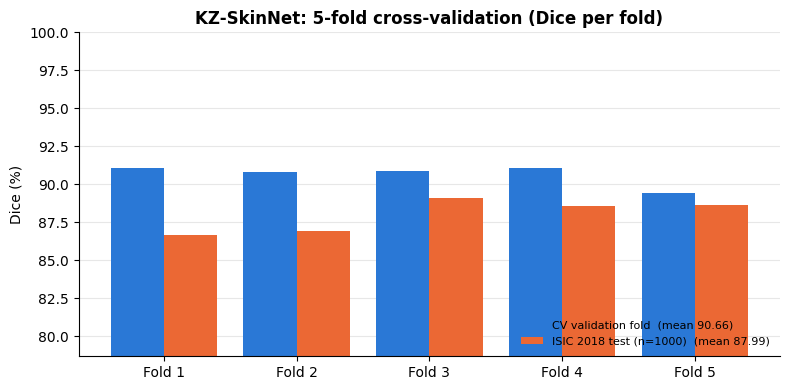

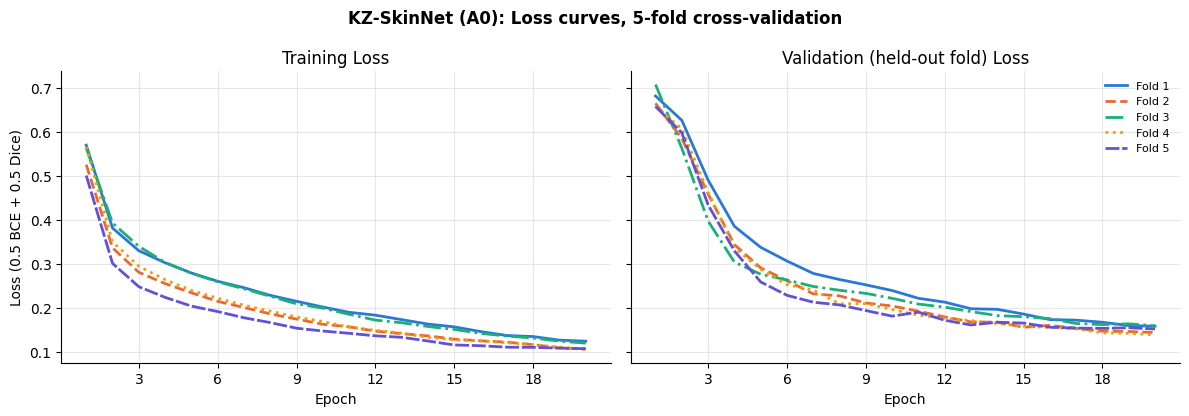

Saved: /kaggle/working/reviewer_experiments/kfold/A0_kfold_loss_curves.png


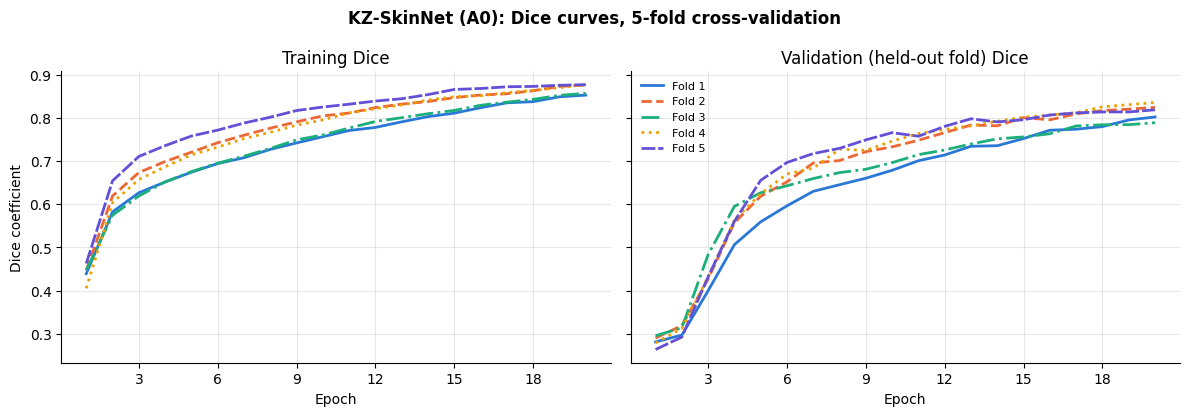

Saved: /kaggle/working/reviewer_experiments/kfold/A0_kfold_dice_curves.png


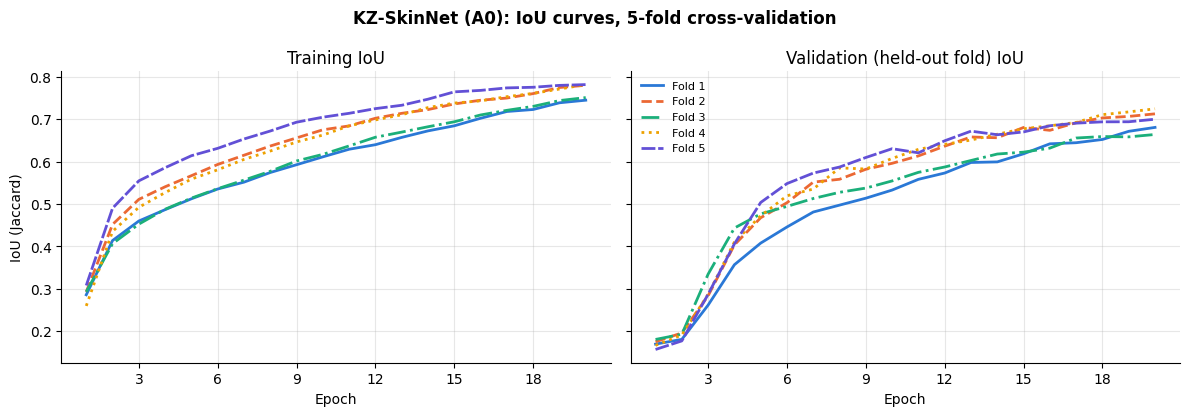

Saved: /kaggle/working/reviewer_experiments/kfold/A0_kfold_iou_curves.png


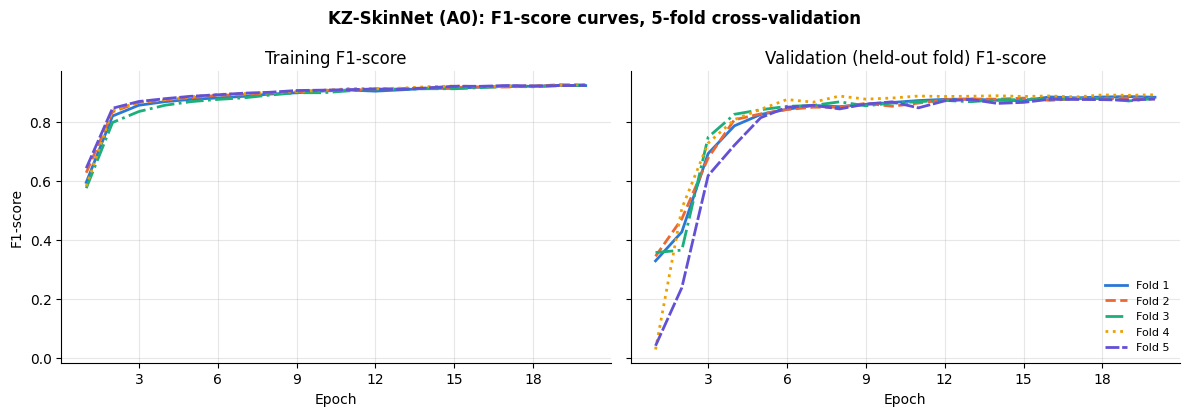

Saved: /kaggle/working/reviewer_experiments/kfold/A0_kfold_f1_curves.png
All outputs saved to /kaggle/working/reviewer_experiments/kfold


In [ ]:
# ============================================================
# CELL K (STANDALONE, one cell): 5-FOLD CROSS-VALIDATION of KZ-SkinNet (A0) - ISIC 2018 only  (R2.6, R3.10)
# - Needs NO saved checkpoint and NO other cell: it loads the data itself and trains
#   a fresh A0 in every fold (ImageNet MobileNetV3Small encoder, same as A0).
# - 2,594 ISIC 2018 training images -> 5 folds stratified by lesion size.
#   Each fold: train on ~2,075, early stopping + best checkpoint on the held-out ~519.
# - Same protocol as A0: max 20 epochs, EarlyStopping 5, ReduceLR 2 (x0.5), Adam 1e-4,
#   batch 16, 0.5*BCE + 0.5*Dice, augmentation, threshold 0.5.
# - Every fold model is also tested on the official ISIC 2018 test set (1,000).
# - Metrics: Accuracy, Precision, Recall, F1-score, Dice, IoU, AUC (+ Specificity), pixel-level pooled.
# - Curves per fold (train + validation): Loss, Dice, IoU, F1-score.
# - Resumable: finished folds (weights + json in /kaggle/working/reviewer_experiments/kfold) are skipped.
# - ~6-10 min per fold on a T4 (~35-50 min total).
# ============================================================
import os, json, time, random
import numpy as np, pandas as pd, cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from matplotlib.ticker import MaxNLocator

IMG_SIZE, BATCH_SIZE, THRESHOLD = 256, 16, 0.5
K, EPOCHS, CV_SEED = 5, 20, 42
OUT = "/kaggle/working/reviewer_experiments"
CV_DIR = f"{OUT}/kfold"; os.makedirs(CV_DIR, exist_ok=True)
AUTOTUNE = tf.data.AUTOTUNE

R18 = "/kaggle/input/datasets/nhlong12/isic-2018/skin-dataset"
PATHS = {
    "train": (f"{R18}/train/images/ISIC2018_Task1-2_Training_Input", f"{R18}/train/masks/ISIC2018_Task1_Training_GroundTruth"),
    "Test":  (f"{R18}/test/images/ISIC2018_Task1-2_Test_Input",      f"{R18}/test/masks/ISIC2018_Task1_Test_GroundTruth"),
}

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError: pass
GPU_CC = tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0)) if gpus else (0, 0)
tf.keras.mixed_precision.set_global_policy("float32")
print("TensorFlow", tf.__version__, "| GPUs:", len(gpus), "| compute capability:", GPU_CC)

# ---------------- data (loaded into RAM) ----------------
def load_pair(img_path, mask_path):
    im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return im, (m > 127).astype(np.uint8)

def load_set(img_paths, mask_paths):
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(load_pair, img_paths, mask_paths))
    return np.stack([r[0] for r in res]), np.stack([r[1] for r in res]).astype(bool)

RAW, NAMES = {}, {}
for name, (i_dir, m_dir) in PATHS.items():
    masks = {m.replace("_segmentation.png", ""): m for m in os.listdir(m_dir) if m.lower().endswith(".png")}
    files = [f for f in sorted(os.listdir(i_dir)) if f.lower().endswith(".jpg") and f[:-4] in masks]
    t0 = time.time()
    RAW[name] = load_set([os.path.join(i_dir, f) for f in files], [os.path.join(m_dir, masks[f[:-4]]) for f in files])
    NAMES[name] = [f[:-4] for f in files]
    print(f"{name}: {len(files)} images ({time.time() - t0:.0f}s)")

def to_input(imgs_uint8):
    return imgs_uint8.astype(np.float32) / 127.5 - 1.0

# ---------------- KZ-SkinNet (A0) architecture (identical to the training run) ----------------
def conv_block(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=name + "_conv")(x)
    x = layers.BatchNormalization(name=name + "_bn")(x)
    return layers.Activation("relu", name=name + "_relu")(x)

def build_kz_skinnet(weights=None):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    bb = tf.keras.applications.MobileNetV3Small(input_tensor=inp, include_top=False,
                                                weights=weights, include_preprocessing=False)
    feats = {}
    for l in bb.layers:
        try:
            s = l.output.shape
            if len(s) == 4 and s[1] in (128, 64, 32, 16, 8): feats[s[1]] = l.output
        except Exception: pass
    x = conv_block(feats[8], 128, "bridge")
    for res, f, n in [(16, 96, "dec4"), (32, 64, "dec3"), (64, 32, "dec2"), (128, 16, "dec1")]:
        x = layers.UpSampling2D(2, interpolation="bilinear", name=n + "_up")(x)
        x = layers.Concatenate(name=n + "_cat")([x, feats[res]])
        x = conv_block(x, f, n)
    x = layers.UpSampling2D(2, interpolation="bilinear", name="final_up")(x)
    return models.Model(inp, layers.Conv2D(1, 1, activation="sigmoid", dtype="float32", name="mask")(x), name="KZ_SkinNet")

def predict(model, imgs_uint8, bs=BATCH_SIZE):
    return model.predict(to_input(imgs_uint8), batch_size=bs, verbose=0)[..., 0]

def per_image_metrics(prob, gt, thr=THRESHOLD):
    p = prob >= thr
    tp = (gt & p).sum((1, 2)).astype(float); fp = (~gt & p).sum((1, 2)).astype(float)
    fn = (gt & ~p).sum((1, 2)).astype(float); tn = (~gt & ~p).sum((1, 2)).astype(float)
    return pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "TN": tn, "Dice": 2*tp/(2*tp+fp+fn+1e-12)})

def pooled_from_counts(TP, FP, FN, TN):
    e = 1e-12
    P, R = TP/(TP+FP+e), TP/(TP+FN+e)
    return {"Accuracy": (TP+TN)/(TP+TN+FP+FN+e), "Precision": P, "Recall": R, "F1-score": 2*P*R/(P+R+e),
            "Dice": 2*TP/(2*TP+FP+FN+e), "IoU": TP/(TP+FP+FN+e), "Specificity": TN/(TN+FP+e)}

# ---------------- training pipeline (same as A0) ----------------
def augment(x, y):
    x = tf.cast(x, tf.float32) / 255.0; y = tf.cast(y, tf.float32)
    xy = tf.concat([x, y], -1)
    xy = tf.image.random_flip_left_right(xy); xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, tf.random.uniform([], 0, 4, dtype=tf.int32))
    x, y = xy[..., :3], xy[..., 3:]
    x = tf.image.random_brightness(x, 0.15); x = tf.image.random_contrast(x, 0.85, 1.15)
    x = tf.image.random_saturation(x, 0.85, 1.15); x = tf.image.random_hue(x, 0.03)
    return tf.clip_by_value(x, 0.0, 1.0) * 2.0 - 1.0, y

def make_ds(X, Y, training, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, Y[..., None].astype(np.uint8)))
    if training:
        ds = ds.shuffle(len(X), seed=seed, reshuffle_each_iteration=True).map(augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 127.5 - 1.0, tf.cast(y, tf.float32)), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

def dice_coefficient(y_true, y_pred):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1]); y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (2.0 * inter + 1e-6) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + 1e-6)
def iou_score(y_true, y_pred):          # soft IoU, same definition as in the A0 training run
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1]); y_pred = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    return (inter + 1e-6) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - inter + 1e-6)
def f1_score(y_true, y_pred):           # F1 at threshold 0.5 (logged per epoch for the F1 curve; does not affect training)
    y_true = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_hat = tf.cast(tf.reshape(tf.cast(y_pred, tf.float32), [-1]) >= THRESHOLD, tf.float32)
    tp = tf.reduce_sum(y_true * y_hat)
    return (2.0 * tp + 1e-6) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_hat) + 1e-6)
_bce = tf.keras.losses.BinaryCrossentropy()
def bce_dice_loss(y_true, y_pred):
    return 0.5 * _bce(y_true, tf.cast(y_pred, tf.float32)) + 0.5 * (1.0 - dice_coefficient(y_true, y_pred))

def train_fold(k, tr_idx, va_idx):
    ckpt = f"{CV_DIR}/A0_fold{k}_best.weights.h5"; info = f"{CV_DIR}/A0_fold{k}_info.json"
    if os.path.exists(ckpt) and os.path.exists(info):
        print(f"fold {k}: already trained"); return ckpt, json.load(open(info))
    Xtr, Ytr = RAW["train"][0][tr_idx], RAW["train"][1][tr_idx]
    Xva, Yva = RAW["train"][0][va_idx], RAW["train"][1][va_idx]

    def _run(policy):
        print(f"\n########## fold {k}/{K}: train {len(tr_idx)} | validation {len(va_idx)}  [{policy}, XLA off]")
        tf.keras.backend.clear_session()
        tf.keras.mixed_precision.set_global_policy(policy)
        random.seed(CV_SEED + k); np.random.seed(CV_SEED + k); tf.random.set_seed(CV_SEED + k)
        m = build_kz_skinnet(weights="imagenet")
        m.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=bce_dice_loss,
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), dice_coefficient, iou_score, f1_score],
                  jit_compile=False)
        t0 = time.time()
        h = m.fit(make_ds(Xtr, Ytr, True, CV_SEED + k), validation_data=make_ds(Xva, Yva, False, CV_SEED + k).cache(),
                  epochs=EPOCHS, verbose=2, callbacks=[
                      tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True),
                      tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
                      tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, verbose=1),
                      tf.keras.callbacks.CSVLogger(f"{CV_DIR}/A0_fold{k}_history.csv")])
        return {"Epochs": len(h.history["loss"]), "Minutes": round((time.time() - t0) / 60, 1), "Precision mode": policy}

    try:
        meta = _run("mixed_float16" if GPU_CC[0] >= 7 else "float32")
    except (tf.errors.InternalError, tf.errors.InvalidArgumentError) as e:
        print(f"   mixed precision failed ({type(e).__name__}) -> retrying fold {k} in float32")
        if os.path.exists(ckpt): os.remove(ckpt)
        meta = _run("float32")
    finally:
        tf.keras.mixed_precision.set_global_policy("float32")
    json.dump(meta, open(info, "w"))
    return ckpt, meta

def pooled(prob, gt):
    pi = per_image_metrics(prob, gt)
    r = pooled_from_counts(pi.TP.sum(), pi.FP.sum(), pi.FN.sum(), pi.TN.sum())
    y = gt.reshape(-1); p = prob.reshape(-1)                 # AUC on 2M random pixels (as in the A0 evaluation)
    idx = np.random.RandomState(0).choice(len(y), min(len(y), 2_000_000), replace=False)
    r["AUC"] = roc_auc_score(y[idx], p[idx])
    r["Image-wise Dice"] = pi.Dice.mean()
    return r

# folds stratified by lesion size (quintiles of lesion area) so every fold has small and large lesions
area = RAW["train"][1].reshape(len(RAW["train"][1]), -1).mean(1)
strata = pd.qcut(area, q=5, labels=False, duplicates="drop")
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=CV_SEED)
assign = np.full(len(area), -1)
for k, (_, va) in enumerate(skf.split(np.zeros(len(area)), strata), start=1):
    assign[va] = k
pd.DataFrame({"image": NAMES["train"], "fold": assign}).to_csv(f"{CV_DIR}/fold_assignment.csv", index=False)

rows = []
for k in range(1, K + 1):
    tr_idx, va_idx = np.where(assign != k)[0], np.where(assign == k)[0]
    ckpt, meta = train_fold(k, tr_idx, va_idx)
    tf.keras.backend.clear_session(); tf.keras.mixed_precision.set_global_policy("float32")
    m = build_kz_skinnet(); m.load_weights(ckpt)
    for name, (X, Y) in [("CV validation fold", (RAW["train"][0][va_idx], RAW["train"][1][va_idx])),
                         ("ISIC 2018 test (n=%d)" % len(RAW["Test"][0]), RAW["Test"])]:
        r = pooled(predict(m, X), Y)
        r.update(Fold=k, Set=name, Images=len(X), Epochs=meta["Epochs"], Minutes=meta["Minutes"])
        rows.append(r)
    print(f"fold {k}: done")

cv = pd.DataFrame(rows)
M = ["Accuracy", "Precision", "Recall", "F1-score", "Dice", "IoU", "AUC", "Specificity", "Image-wise Dice"]
show = cv.copy(); show[M] = (show[M] * 100).round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(f"\nKZ-SkinNet (A0): {K}-fold cross-validation on the ISIC 2018 training set ({len(RAW['train'][0])} images), per fold (%)")
print(show[["Set", "Fold", "Images", "Epochs"] + M].to_string(index=False))
agg = cv.groupby("Set", sort=False)[M].agg(["mean", "std"]) * 100
summary = pd.DataFrame({c: agg[c]["mean"].round(2).astype(str) + " ± " + agg[c]["std"].round(2).astype(str) for c in M})
print(f"\nKZ-SkinNet (A0): mean ± SD over the {K} folds (%)")
print(summary.to_string())
cv.to_csv(f"{CV_DIR}/A0_kfold_per_fold.csv", index=False); summary.to_csv(f"{CV_DIR}/A0_kfold_mean_sd.csv")

# ---------------- figure: Dice per fold ----------------
fig, ax = plt.subplots(figsize=(8, 4))
sets = list(dict.fromkeys(cv["Set"])); colors = ["#2a78d6", "#eb6834"]
w = 0.8 / len(sets); x = np.arange(1, K + 1)
for j, s in enumerate(sets):
    v = cv[cv.Set == s].sort_values("Fold")["Dice"].to_numpy() * 100
    ax.bar(x + (j - (len(sets) - 1) / 2) * w, v, w, color=colors[j % 2], label=f"{s}  (mean {v.mean():.2f})")
ax.set_xticks(x); ax.set_xticklabels([f"Fold {k}" for k in x]); ax.set_ylabel("Dice (%)")
ax.set_ylim(max(0, cv["Dice"].min() * 100 - 8), 100); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
ax.set_title(f"KZ-SkinNet: {K}-fold cross-validation (Dice per fold)", fontweight="bold")
fig.tight_layout(); fig.savefig(f"{CV_DIR}/A0_kfold_dice.png", dpi=300, bbox_inches="tight"); plt.show()

# ---------------- training curves per fold: Loss, Dice, IoU, F1-score ----------------
FOLD_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"]
FOLD_STYLE = ["-", "--", "-.", ":", (0, (5, 1))]
CURVES = {"Loss": ("loss", "Loss (0.5 BCE + 0.5 Dice)"), "Dice": ("dice_coefficient", "Dice coefficient"),
          "IoU": ("iou_score", "IoU (Jaccard)"), "F1-score": ("f1_score", "F1-score")}
hist = {k: pd.read_csv(f"{CV_DIR}/A0_fold{k}_history.csv") for k in range(1, K + 1)
        if os.path.exists(f"{CV_DIR}/A0_fold{k}_history.csv")}
for metric, (col, ylabel) in CURVES.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax, c, title in [(axes[0], col, "Training"), (axes[1], "val_" + col, "Validation (held-out fold)")]:
        for k, h in hist.items():
            if c in h:
                ax.plot(h["epoch"] + 1, h[c], color=FOLD_COLORS[k - 1], linestyle=FOLD_STYLE[k - 1], linewidth=2, label=f"Fold {k}")
        ax.set_title(f"{title} {metric}"); ax.set_xlabel("Epoch"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3); ax.set_axisbelow(True)
    axes[0].set_ylabel(ylabel); axes[1].legend(frameon=False, fontsize=8)
    fig.suptitle(f"KZ-SkinNet (A0): {metric} curves, {K}-fold cross-validation", fontweight="bold")
    fig.tight_layout(); out = f"{CV_DIR}/A0_kfold_{metric.lower().replace('-score', '')}_curves.png"
    fig.savefig(out, dpi=300, bbox_inches="tight"); plt.show(); print("Saved:", out)
print("All outputs saved to", CV_DIR)